# Human influence in Rural Wildfires ignitions

## Group: 02
### Name(s) & ID(s) of Group Members:
- Benedita Barreto da Costa Gonçalves - 202205903
- Isabela Moreira Merelles - 202602764
- Maria Leonor Soares Carvalho - 202307522
- Mariana Vale de Oliveira Coelho de Pinho - 202306234

## Table of Contents

1. [Research Question](#1-research-question)
2. [Data Preparation](#2-data-preparation)
3. [Exploratory Analysis](#3-exploratory-analysis)
4. [Statistical MOdelling](#4-formulate-conclusions)
5. [Look Back and Ahead](#5-look-back-and-ahead)

---

## 1) Research Question

How did initial response times and burnt areas change before and after 2017, and how are these two variables associated across four Portuguese municipalities?

### Secondary Research Questions:

1. Was the change in the proportion of negligent causes concentrated in the critical summer period, or did it also affect the traditional burning months (autumn/winter)?

    Difference in proportion (Variables to use: cause_type, period, season_risk_period). Test: Z test


2. Did the reduction in negligent wildfire occurrences translate into a significantly lower mean number of daily ignitions on weekends compared to weekdays?

    Mean comparison (Variables to use: Daily_Ignitions_Count, Day_Type, Period). Test: t-test


3. Do final burnt areas differ significantly across the four municipalities under study?

    ANOVA (Variables: Log_Total_Burnt_Area, Municipality). Test: One-way ANOVA.


4. Did the disparity in final burnt area between intentional and negligent causes narrow in the post-2017 period in the municipalities under study?

    ANOVA (Variables to use: Log_Total_Burnt_Area, Cause_Type_Period). Test: Two-way ANOVA 


---

## 2) Collect data

### Dataset Source

The dataset used in this project was sourced from the Institute for Nature Conservation and Forests (ICNF), specifically the wildfire statistics published under the Information Management section of [their website](https://www.icnf.pt/florestas/gfr/gfrgestaoinformacao/estatisticas). This dataset contains data on human influenced wildfire ignitions from 2001 until 2025. The records are split across three ICNF files (2001-2010, 2011-2020 and 2021-2025), and were combined into a single dataset before analysis.

The raw file contains 40 columns covering fire identifiers, location, timestamps, burnt area by land cover, fire weather indices, and cause classification. Only a subset of these columns was used in the analysis, and several variables were derived from them. The full mapping is described below so that the variables can be reproduced from the raw file.

### Dataset Details


#### Variables: 

##### Qualitative Variables

- **Cause_Type**: Intentional vs. Negligent. Derived from the cause classification columns (`TipoCausa`, `GrupoCausa`, `CodCausa`), keeping only validated human causes. Fires with an unclassified or unknown cause were excluded.

- **Period**: Pre-2017 (2001–2016) vs. Post-2017 (2018–2025). Derived from `Ano`. In practice, the law was only implemented in 2021, so the post-2017 group mixes pre-law and post-law years (see limitations).

- **Municipality**: Chaves, Montalegre, Ourém, Tomar. Taken from `Concelho`.

- **Season_Risk_Period**: Critical Period vs. Non-Critical Period. Derived from `Mes` and `Dia`, with the critical period defined as 1 June to 30 September.

- **Day_Type**: Weekend vs. Weekday. Derived from the fire date (`Ano`, `Mes`, `Dia`), with Saturday and Sunday classified as weekend.

- **Cause_Type_Period**: Combined factor of `Cause_Type` and `Period`, used for the two-way ANOVA in Q4.

##### Quantitative Variables

- **Daily_Ignitions_Count**: Number of ignitions per municipality per day, computed by counting `Codigo_SGIF` grouped by `date` and `municipality`.

- **Total_Burnt_Area**: Total surface burnt per occurrence, in hectares, from `AreaTotal_ha`.

- **Initial_Response_Time**: Time in minutes between `DataHoraAlerta` and `DataHora_PrimeiraIntervencao`.

- **Fire_Duration**: Total duration from fire alert to final extinction, in hours, from `Duracao_Horas`.

### Data preparation

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

project_path = Path.cwd()
raw = project_path / "01_dataset/raw"
processed = project_path / "01_dataset/processed"
processed.mkdir(parents=True, exist_ok=True)

In [2]:
#Loading the data
cols_necessarias = [
    'Ano', 'Mes', 'Dia', 'Hora', 'AreaTotal_ha', 'Duracao_Horas',
    'DataHoraAlerta', 'DataHora_PrimeiraIntervencao', 'DataHora_Extincao',
    'Concelho', 'TipoCausa', 'Codigo_SGIF'
]

df1 = pd.read_excel(raw / "Registos_Incendios_SGIF_2021_2025.xlsx", usecols=cols_necessarias)
df2 = pd.read_excel(raw / "Registos_Incendios_SGIF_2011_2020.xlsx", usecols=cols_necessarias)
df3 = pd.read_excel(raw / "Registos_Incendios_SGIF_2001_2010.xlsx", usecols=cols_necessarias)

# confirm the raw files share the same schema
print("df1 vs df2:", df1.columns.equals(df2.columns))
print("df2 vs df3:", df2.columns.equals(df3.columns))

df1 vs df2: True
df2 vs df3: True


Before deriving variables, the sample size was checked by municipality and year to confirm that all four municipalities are represented across the full period.

In [3]:
# Concatenar os 3 ficheiros (2001 a 2025)
df = pd.concat([df1, df2, df3], ignore_index=True)

concelhos = ["Chaves", "Ourém", "Montalegre", "Tomar"]

# Filtrar pelos 4 concelhos e pela janela completa de 2001 a 2025
df_final = df[df["Concelho"].isin(concelhos)].copy()
df_final = df_final[df_final["Ano"].between(2001, 2025)].copy()

print(df_final["Concelho"].value_counts())
print(pd.crosstab(df_final["Concelho"], df_final["Ano"], margins=True))

Concelho
Montalegre    5635
Chaves        3914
Ourém         2691
Tomar         2280
Name: count, dtype: int64
Ano         2001  2002  2003  2004  2005  2006  2007  2008  2009  2010  ...  \
Concelho                                                                ...   
Chaves       259   307   127   188   326   167   130   139   308   127  ...   
Montalegre   262   283   177   194   390   147   238   149   475   177  ...   
Ourém        118   159   116   166   293   188   136   144    99    97  ...   
Tomar         58   115    86   166   186   125   130   108   110    95  ...   
All          697   864   506   714  1195   627   634   540   992   496  ...   

Ano         2017  2018  2019  2020  2021  2022  2023  2024  2025    All  
Concelho                                                                 
Chaves       132    67    66    73    46   105    36    68    94   3914  
Montalegre   314   119   168   134   191   192   117    94   131   5635  
Ourém         96    82    63    97    6

In [4]:
# quantitative variables:

#Initial_Response_Time
for col in ["DataHoraAlerta", "DataHora_PrimeiraIntervencao", "DataHora_Extincao"]:
  df_final[col] = pd.to_datetime(df_final[col], errors="coerce")

df_final["Initial_Response_Time"] = (
    df_final["DataHora_PrimeiraIntervencao"] - df_final["DataHoraAlerta"]
).dt.total_seconds() / 60

#Fire_Duration
df_final["Fire_Duration"] = df_final["Duracao_Horas"]

#Total_Burnt_Area
df_final["Total_Burnt_Area"] = df_final["AreaTotal_ha"]

# Escala logarítmica para cumprir os pressupostos das ANOVAs
df_final["Log_Total_Burnt_Area"] = np.log10(df_final["Total_Burnt_Area"] + 0.001)

In [5]:
#qualitative variables:

#Period
df_final["Period"] = np.where(df_final["Ano"] <= 2016, "Pre-2017",
                       np.where(df_final["Ano"] >= 2018, "Post-2017", "Transition"))

#Season_Risk_Period
df_final["Season_Risk_Period"] = np.where(
    df_final["Mes"].isin([6, 7, 8, 9]),
    "Critical", "Non-Critical"
)

#Day_Type
df_final["Day_Type"] = np.where(
    df_final["DataHoraAlerta"].dt.dayofweek >= 5,
    "Weekend", "Weekday"
)

In [6]:
# 1. Mapear apenas causas humanas apuradas
cause_map = {
    "Negligente": "Negligent",
    "Intencional": "Intentional",
}

df_final["Cause_Type"] = df_final["TipoCausa"].map(cause_map)

df_final["Cause_Type_Period"] = np.where(
    df_final["Cause_Type"].isna(),
    np.nan,
    df_final["Cause_Type"].astype(str) + "_" + df_final["Period"].astype(str),
)

# 2. Contagem diária de ignições negligentes (excluindo 2017) para a Q2
df_final["Date"] = df_final["DataHoraAlerta"].dt.date

df_neg = df_final[
    (df_final["Cause_Type"] == "Negligent")
    & (df_final["Period"] != "Transition")
].copy()

daily = (
    df_neg.groupby(["Concelho", "Date", "Period"])
    .size()
    .reset_index(name="Daily_Ignitions_Count")
)

daily["Day_Type"] = np.where(
    pd.to_datetime(daily["Date"]).dt.dayofweek >= 5, "Weekend", "Weekday"
)

In [7]:
# Count missing values in each column
print(f"\nNumber of missing values for each column/ feature:")
print(df_final.isnull().sum())


Number of missing values for each column/ feature:
Codigo_SGIF                        0
Ano                                0
Mes                                0
Dia                                0
Hora                               0
AreaTotal_ha                       0
DataHoraAlerta                     0
DataHora_PrimeiraIntervencao    5583
DataHora_Extincao                 43
Duracao_Horas                     43
Concelho                           0
TipoCausa                       6043
Initial_Response_Time           5583
Fire_Duration                     43
Total_Burnt_Area                   0
Log_Total_Burnt_Area               0
Period                             0
Season_Risk_Period                 0
Day_Type                           0
Cause_Type                      7357
Cause_Type_Period               7357
Date                               0
dtype: int64


In [8]:
df_final.describe()

,Ano,Mes,Dia,Hora,AreaTotal_ha,DataHoraAlerta,DataHora_PrimeiraIntervencao,DataHora_Extincao,Duracao_Horas,Initial_Response_Time,Fire_Duration,Total_Burnt_Area,Log_Total_Burnt_Area
count,14520.000000,14520.000000,14520.000000,14520.000000,14520.000000,14520,8937,14477,14477.000000,8937.000000,14477.000000,14520.000000,14520.000000
mean,2011.001446,6.891116,15.793595,14.687190,9.087475,2011-07-14 14:38:06.070247936,2015-08-30 20:28:02.517623296,2011-07-11 13:07:50.770463488,2.433111,18.117153,2.433111,9.087475,-0.772434
min,2001.000000,1.000000,1.000000,0.000000,0.000000,2001-02-18 20:45:00,2008-01-20 17:20:00,2001-02-18 23:05:00,0.000000,0.000000,0.000000,0.000000,-3.000000
25%,2005.000000,5.000000,8.000000,12.000000,0.010000,2005-08-25 18:52:30,2011-09-25 13:12:00,2005-08-25 14:57:00,0.616667,9.000000,0.616667,0.010000,-1.958607
50%,2010.000000,8.000000,16.000000,15.000000,0.200000,2010-10-28 16:55:00,2015-04-03 21:30:00,2010-10-18 17:58:00,1.250000,14.000000,1.250000,0.200000,-0.696804
75%,2016.000000,9.000000,23.000000,18.000000,1.130000,2016-09-11 15:47:45,2019-03-26 18:40:00,2016-09-11 15:38:00,2.533333,20.000000,2.533333,1.130000,0.053463
max,2025.000000,12.000000,31.000000,23.000000,6379.000000,2025-11-04 18:49:00,2025-11-04 19:10:00,2025-11-04 19:24:00,244.550000,1456.000000,244.550000,6379.000000,3.804753
std,6.668413,2.635995,8.666318,5.363572,116.325010,NaN,NaN,NaN,6.112195,30.905899,6.112195,116.325010,1.203978


Saving processed data to be used for statistics

In [9]:
df_final.to_excel(processed / "wildfires_processed.xlsx", index=False)
daily.to_excel(processed / "daily_ignitions.xlsx", index=False)

Per question dataset

In [10]:
# Q1: Negligente vs Intencional, Pré vs Pós, Crítico vs Não-Crítico (Z-test)
q1 = df_final[
    (df_final["Cause_Type"].notna()) & (df_final["Period"] != "Transition")
].copy()
q1.to_excel(processed / "q1_cause_period_season.xlsx", index=False)

# Q2: Ignições diárias de causas negligentes, Weekend vs Weekday (t-test)
q2 = daily.dropna(subset=["Date", "Daily_Ignitions_Count"]).copy()
q2.to_excel(processed / "q2_daily_ignitions.xlsx", index=False)

# Q3: Área ardida por Concelho (One-way ANOVA)
q3 = df_final[
    (df_final["Total_Burnt_Area"].notna())
    & (df_final["Period"] != "Transition")
].copy()
q3.to_excel(processed / "q3_burnt_area_municipality.xlsx", index=False)

# Q4: Área ardida por Cause_Type e Period (Two-way ANOVA)
q4 = df_final[
    (df_final["Cause_Type"].notna())
    & (df_final["Period"] != "Transition")
    & (df_final["Total_Burnt_Area"].notna())
].copy()
q4.to_excel(processed / "q4_burnt_area_cause_period.xlsx", index=False)

#### Missing values

| Question | Variables used | rows dropped where |
|---|---|---|
| Q1 | `Cause_Type`, `Period`, `Season_Risk_Period` | `Cause_Type` is missing or `Period == 'Transition'` (2017) |
| Q2 | `Daily_Ignitions_Count`, `Day_Type`, `Period` | Non-negligent causes, date is missing, or `Period == 'Transition'` |
| Q3 | `Log_Total_Burnt_Area`, `Municipality` | `Total_Burnt_Area` is missing or `Period == 'Transition'` |
| Q4 | `Log_Total_Burnt_Area`, `Cause_Type`, `Period` | `Cause_Type` or `Total_Burnt_Area` is missing, or `Period == 'Transition'` |

In [11]:
log = pd.DataFrame({
    "dataset": ["pooled", "q1", "q2", "q3", "q4"],
    "n_rows": [len(df_final), len(q1), len(q2), len(q3), len(q4)],
    "exclusion": [
        "Initial 4-municipality cohort (2001-2025)",
        "Missing Cause_Type and Transition year (2017) excluded",
        "Negligent daily counts (2017 excluded)",
        "Missing Burnt Area and 2017 excluded",
        "Missing Cause_Type, Burnt Area, and 2017 excluded",
    ],
})
log.to_excel(processed / "sample_sizes.xlsx", index=False)
log

,dataset,n_rows,exclusion
0,pooled,14520,Initial 4-municipality cohort (2001-2025)
1,q1,6519,Missing Cause_Type and Transition year (2017) ...
2,q2,2897,Negligent daily counts (2017 excluded)
3,q3,13816,Missing Burnt Area and 2017 excluded
4,q4,6519,"Missing Cause_Type, Burnt Area, and 2017 excluded"


In [ ]:
import sys
import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scipy", scipy.__version__, "| matplotlib", matplotlib.__version__)

STUDY_YEARS = (2018, 2025)
MUNICIPALITIES = ["Chaves", "Montalegre", "Ourém", "Tomar"]    # fixed order for all tables and figures
Y = "Total_Burnt_Area"                                          # burnt area in hectares (original scale)
# No randomness is used anywhere in this notebook, so the results are fully deterministic.

# Look for the data folder in the current folder and up to 3 parent folders (relative paths only)
def find_data_dir(filename="wildfires_processed.xlsx"):
    here = Path.cwd().resolve()
    for base in [here, *list(here.parents)[:3]]:
        for sub in ["01_dataset/processed", "processed", "data", "."]:
            if (base / sub / filename).exists():
                return base / sub
    raise FileNotFoundError(f"Could not find {filename} (current folder: {here}). Put the notebook next to '01_dataset' or set DATA_DIR by hand.")

DATA_DIR = find_data_dir()
print("Data folder found:", "/".join(DATA_DIR.parts[-2:]))

# Plot style: one fixed colour per municipality (colour-blind-safe set), same order everywhere
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
})
COLORS = dict(zip(MUNICIPALITIES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))

def qq_panel(ax, resid, color, title, ylabel="Residual"):
    # Normal Q-Q plot with a reference line through the quartiles
    (osm, osr), _ = stats.probplot(resid, dist="norm")
    ax.scatter(osm, osr, s=5, color=color, alpha=.5, edgecolor="none")
    lo, hi = np.percentile(resid, [25, 75]); z_lo, z_hi = stats.norm.ppf([.25, .75])
    ax.plot(osm, np.median(resid) + (hi - lo) / (z_hi - z_lo) * osm, color="#0b0b0b", linewidth=1)
    ax.set_title(title); ax.set_xlabel("Theoretical quantiles"); ax.set_ylabel(ylabel)

Python 3.13.18 | numpy 2.5.3 | pandas 3.0.5 | scipy 1.18.1 | matplotlib 3.11.2
Data folder found: 01_dataset/processed


The first version of `q4_burnt_area_municipality.xlsx` only removed missing values and **did not filter the years** (7,255 rows, 2011–2025). Even though the preprocessing notebook has since been corrected, we rebuild the Q4 sample here from the main processed file, filter by `Ano` and **reconcile** with the Q4 file, so that the notebook fails loudly if a wrong version is used. No original file is modified.

In [ ]:
raw = pd.read_excel(DATA_DIR / "wildfires_processed.xlsx")
raw["Codigo_SGIF"] = raw["Codigo_SGIF"].astype(str)      # identifiers mix int and str in the Excel file
print("Processed file:", raw.shape)

# The Q4 file is only used to cross-check; if it is locked (open in Excel/OneDrive) we continue without it
try:
    q4_file = pd.read_excel(DATA_DIR / "q4_burnt_area_municipality.xlsx")
    q4_file["Codigo_SGIF"] = q4_file["Codigo_SGIF"].astype(str)
    print("Q4 file:", q4_file.shape, "| years", q4_file["Ano"].min(), "-", q4_file["Ano"].max())
except (PermissionError, FileNotFoundError) as err:
    q4_file = None
    print("Q4 file not readable, cross-check skipped:", type(err).__name__)

# Step-by-step construction of the Q4 sample, with an attrition log
steps = []
d = raw.copy();                                   steps.append(("Processed file (2011-2025, 4 municipalities)", len(d)))
d = d[d["Concelho"].isin(MUNICIPALITIES)];        steps.append(("Keep the 4 municipalities", len(d)))
d = d[d["Ano"].between(*STUDY_YEARS)];            steps.append(("Keep 2018-2025 (uses Ano, not the derived Period)", len(d)))
d = d.dropna(subset=[Y]);                         steps.append(("Drop missing burnt area", len(d)))
d = d[d[Y] >= 0];                                 steps.append(("Drop negative burnt area (invalid)", len(d)))

# Primary descriptive sample: ALL valid occurrences, whatever the cause. Nothing is dropped for cause or size.
q4 = d.reset_index(drop=True)
q4["Concelho"] = pd.Categorical(q4["Concelho"], categories=MUNICIPALITIES, ordered=True)

# Analytical sample for the ANOVA: ln() is only defined for positive areas
q4_ln = q4[q4[Y] > 0].copy()
q4_ln["ln_area"] = np.log(q4_ln[Y])
steps.append(("ANOVA sample: drop fires with 0 ha (ln undefined)", len(q4_ln)))

attrition = pd.DataFrame(steps, columns=["step", "n_remaining"])
attrition["removed"] = -attrition["n_remaining"].diff().fillna(0).astype(int)
print(attrition.to_string(index=False))

Processed file: (7255, 50)
Q4 file: (2739, 50) | years 2018 - 2025
                                             step  n_remaining  removed
     Processed file (2011-2025, 4 municipalities)         7255        0
                        Keep the 4 municipalities         7255        0
Keep 2018-2025 (uses Ano, not the derived Period)         2739     4516
                          Drop missing burnt area         2739        0
               Drop negative burnt area (invalid)         2739        0
ANOVA sample: drop fires with 0 ha (ln undefined)         2738        1


In [ ]:
# Validation assertions
assert q4["Ano"].between(2018, 2025).all(),                      "years outside 2018-2025"
assert set(q4["Concelho"].astype(str)) == set(MUNICIPALITIES),   "missing municipality"
assert pd.api.types.is_numeric_dtype(q4[Y]) and q4[Y].notna().all() and (q4[Y] >= 0).all()
assert q4["Codigo_SGIF"].is_unique,                              "duplicated SGIF identifiers"
assert (q4[Y] == q4["AreaTotal_ha"]).all(),                      "Total_Burnt_Area differs from AreaTotal_ha"
assert (q4["Period"] == "Post-2017").all(),                      "Period label inconsistent with Ano"
assert len(q4) == 2739 and len(q4_ln) == 2738 and np.isfinite(q4_ln["ln_area"]).all()
assert q4["Concelho"].value_counts().to_dict() == {"Montalegre": 1146, "Ourém": 620, "Chaves": 555, "Tomar": 418}

if q4_file is not None:   # reconcile with the (corrected) Q4 file
    in_window = q4_file[q4_file["Ano"].between(*STUDY_YEARS)]
    assert set(in_window["Codigo_SGIF"]) == set(q4["Codigo_SGIF"]), "does not reconcile with the Q4 file"
    print("Q4 file already restricted to 2018-2025:", bool(q4_file["Ano"].between(*STUDY_YEARS).all()))
print("All validation checks passed. n =", len(q4), "| ANOVA sample n =", len(q4_ln))

# Quality-control summary
g_ = q4.groupby("Concelho", observed=True)
qc = pd.DataFrame({"n": g_.size(), "area = 0 ha": g_[Y].apply(lambda s: int((s == 0).sum())),
                   "% < 1 ha": g_[Y].apply(lambda s: round(100 * (s < 1).mean(), 1)),
                   "missing cause": g_["TipoCausa"].apply(lambda s: int(s.isna().sum()))})
print(qc.to_string())
print("Temporal coverage:", q4["DataHoraAlerta"].min(), "->", q4["DataHoraAlerta"].max(),
      "| 2025 records in November:", int((q4.loc[q4["Ano"] == 2025, "DataHoraAlerta"].dt.month == 11).sum()), "(2025 is incomplete)")

# Recorded areas near 0.01 ha
near = np.isclose(q4[Y], 0.01, atol=1e-9)
print(f"Areas below 0.01 ha: {(q4[Y] < 0.01).sum()} fires (smallest positive area: {q4.loc[q4[Y] > 0, Y].min():.5f} ha); "
      f"areas of exactly 0.01 ha: {near.sum()} fires ({100 * near.mean():.1f} %)")

Q4 file already restricted to 2018-2025: True
All validation checks passed. n = 2739 | ANOVA sample n = 2738
               n  area = 0 ha  % < 1 ha  missing cause
Concelho                                              
Chaves       555            0      75.3              2
Montalegre  1146            0      66.5             10
Ourém        620            1      89.5              0
Tomar        418            0      93.8              0
Temporal coverage: 2018-01-29 16:23:00 -> 2025-11-04 18:49:00 | 2025 records in November: 1 (2025 is incomplete)
Areas below 0.01 ha: 312 fires (smallest positive area: 0.00005 ha); areas of exactly 0.01 ha: 315 fires (11.5 %)


In [ ]:
# Cause categories (reported as recorded; nothing is excluded for being unknown or non-human)
cause_tab = (q4.assign(TipoCausa=q4["TipoCausa"].fillna("(missing)")).groupby("TipoCausa")[Y]
               .agg(n="size", mean_ha="mean", median_ha="median", total_ha="sum").round(2).sort_values("n", ascending=False))
cause_tab["% of total area"] = (100 * cause_tab["total_ha"] / cause_tab["total_ha"].sum()).round(1)
print(cause_tab.to_string())

# Reignitions: how many follow another fire in the same parish within 3 days? (a proximity heuristic, NOT proof of a link)
rk = q4[q4["TipoCausa"] == "Reacendimento"]
def has_recent_fire(x):
    prev = q4[(q4["Concelho"] == x["Concelho"]) & (q4["Freguesia"] == x["Freguesia"]) &
              (q4["DataHoraAlerta"] < x["DataHoraAlerta"]) & (q4["DataHoraAlerta"] >= x["DataHoraAlerta"] - pd.Timedelta(days=3))]
    return len(prev) > 0
linked = int(rk.apply(has_recent_fire, axis=1).sum())
print(f"Reignition records: {len(rk)}; {linked} ({100 * linked / len(rk):.0f} %) follow another fire in the same parish within 3 days.")

# Alternative samples used in the robustness checks (Section 08)
sample_human = q4[q4["TipoCausa"].isin(["Negligente", "Intencional"])]
sample_no_2025 = q4[q4["Ano"] != 2025]
print("Human-related only:", len(sample_human), "| excluding 2025:", len(sample_no_2025))

                  n  mean_ha  median_ha  total_ha  % of total area
TipoCausa                                                         
Negligente     1696     8.73       0.29  14798.58             41.5
Intencional     789    23.23       0.08  18326.01             51.4
Reacendimento   130    11.29       0.08   1468.02              4.1
Desconhecida     98    10.38       0.02   1017.21              2.9
Natural          14     0.83       0.05     11.68              0.0
(missing)        12     3.53       2.00     42.41              0.1
Reignition records: 130; 90 (69 %) follow another fire in the same parish within 3 days.
Human-related only: 2485 | excluding 2025: 2419


**Decisions and findings of Section 02**

- **Sample.** After filtering to 2018–2025 there are 2,739 fires (Chaves 555, Montalegre 1,146, Ourém 620, Tomar 418), with no missing or negative areas and no duplicated identifiers. The sample reconciles with the source files. Descriptive statistics of the original area use all 2,739 fires.
- **ANOVA sample.** One fire has an area of exactly 0 ha, for which ln(area) is undefined; it is left out of the ANOVA, which therefore uses n = 2,738 (documented in the attrition log above).
- **All causes are kept** (literal reading of Q4). Only the human-related subset (intentional/negligent) is used later as a sensitivity check.
- **Reignitions are kept.** Each has its own SGIF code and area. Most of them follow another fire in the same parish within 3 days, which suggests that some may be continuations of earlier events, but this proximity rule does not prove it.
- **No outlier removal.** The largest fires are internally consistent records (their areas equal the sum of the land-cover components and their durations are plausible), so they are legitimate extreme events.
- **0.01 ha.** There is a noticeable concentration of recorded areas at exactly 0.01 ha, possibly reflecting rounding or reporting conventions. It is not a minimum recorded value: hundreds of fires have areas below 0.01 ha.
- **2025 is incomplete** (alerts end on 4 November).

---

## 3) Explore and draw inferences

---

### Changes in Negligent Causes (Q1)

In this first phase, we focused on Q1: testing whether the change in the proportion of negligent causes was concentrated in the critical summer period or if it also affected autumn and winter burning months.

### Checking count of data

In [12]:
q1_counts = pd.crosstab(
    [q1["Period"], q1["Season_Risk_Period"]],
    q1["Cause_Type"],
    margins=True
)
q1_counts

Cause_Type                    Intentional  Negligent   All
Period    Season_Risk_Period                              
Post-2017 Critical                    639        576  1215
          Non-Critical                150       1120  1270
Pre-2017  Critical                   1120       1411  2531
          Non-Critical                261       1242  1503
All                                  2170       4349  6519

The total sample for Q1 consists of 6,519 fires due to human cause.

All four combinations have more than 1,200 observations. This means the sample is large enough to trust the Z-test on proportions, and we do not need to worry about small-cell bias.

In the critical period, the counts show intentional fires dropped (from 1,120 to 639), but negligent fires dropped evenmore (from 1,411 to 576).

#### Checking proportion of dataset

In [13]:
q1_props = (
    q1.groupby(["Period", "Season_Risk_Period"])["Cause_Type"]
      .apply(lambda s: (s == "Negligent").mean())
      .reset_index(name="negligent_share")
)
q1_props

,Period,Season_Risk_Period,negligent_share
0,Post-2017,Critical,0.474074
1,Post-2017,Non-Critical,0.881890
2,Pre-2017,Critical,0.557487
3,Pre-2017,Non-Critical,0.826347


In the Critical period, negligent ignitions dropped from 55.7% to 47.4% post-2017. 

In the Non-Critical period, the negligent share actually went up from 82.6% to 88.2%. This is because the counts show that intentional fires in this season fell (261 down to 150), while negligent fires stayed relatively stable (1,242 down to 1,120). Because intentional fires dropped faster than negligent ones, the overall proportion of negligent fires went up.

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
%config InlineBackend.figure_format = "retina"
plt.style.use("seaborn-v0_8")

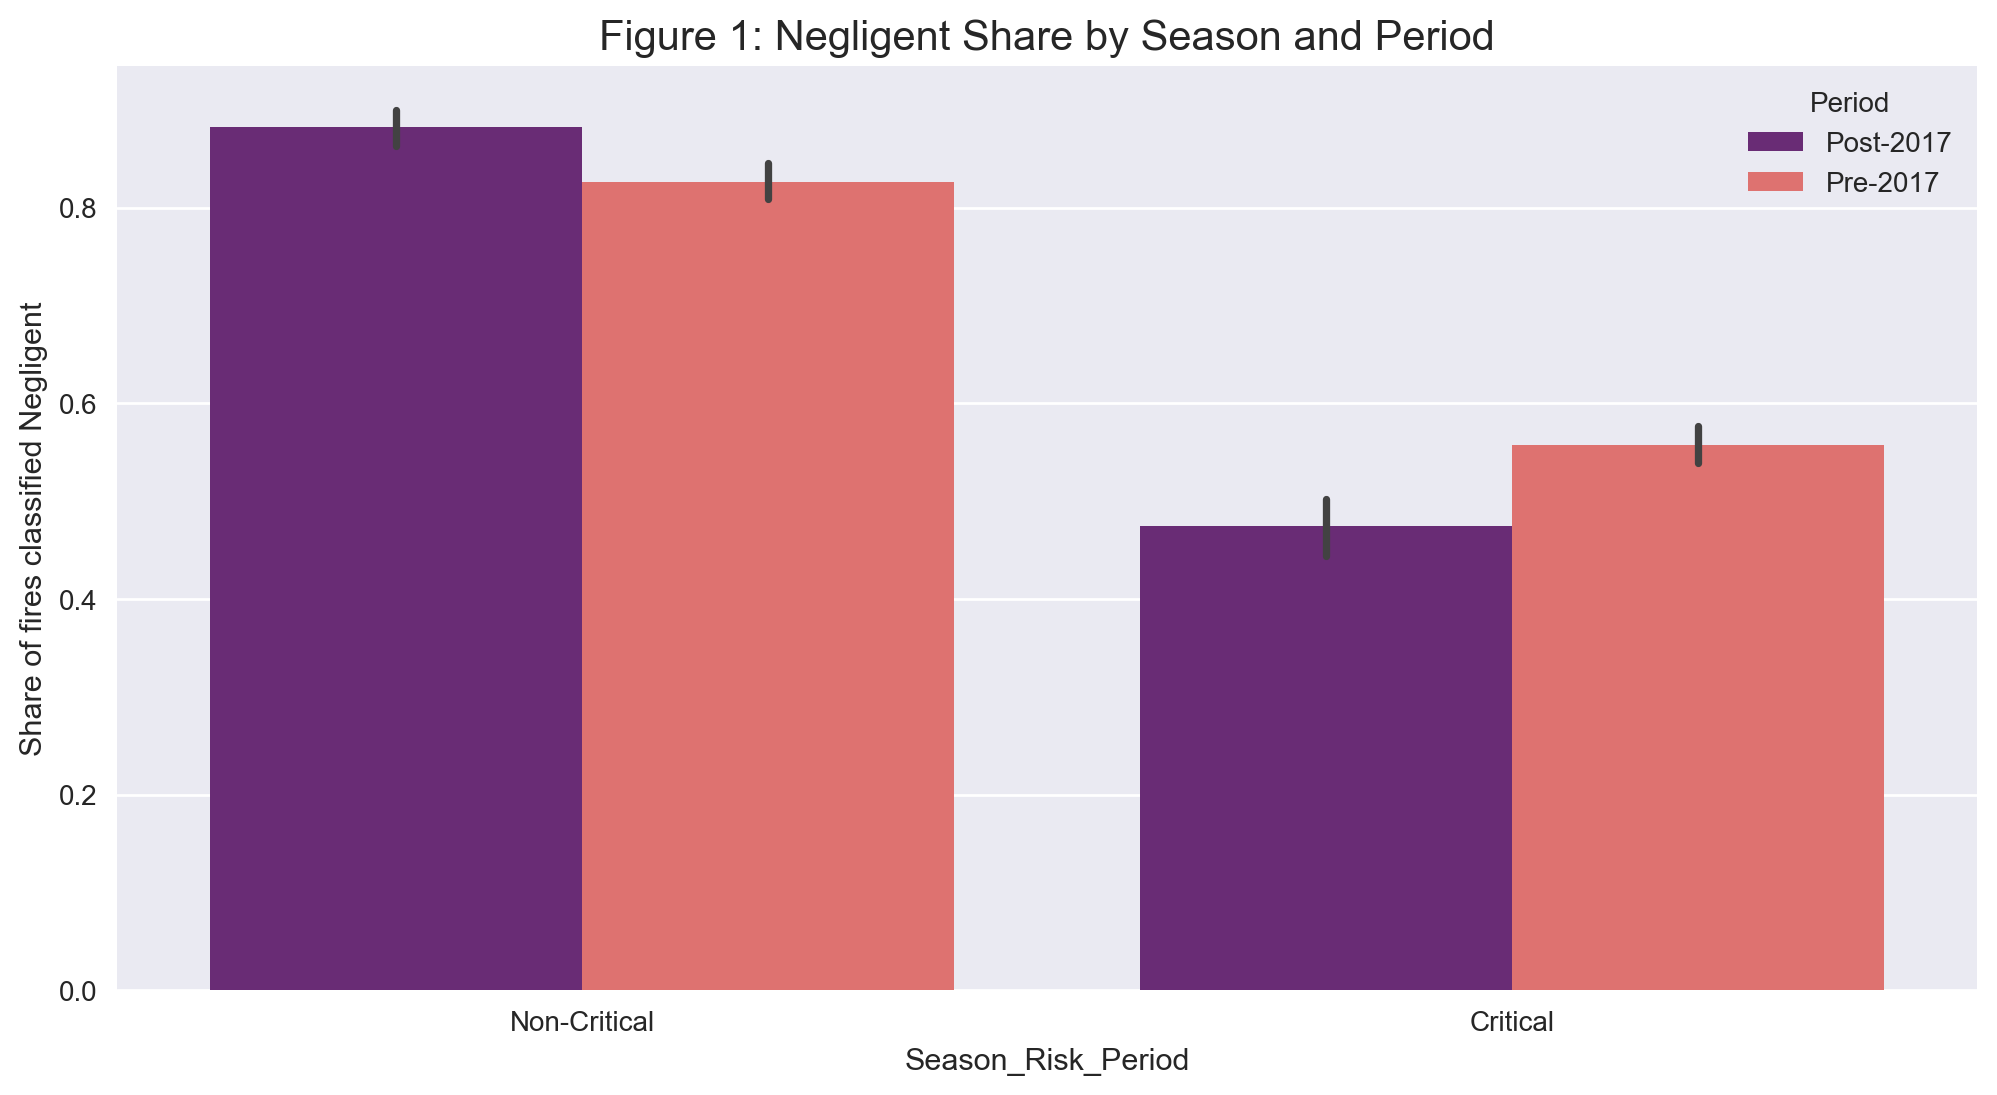

In [15]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=q1, x="Season_Risk_Period", y=(q1["Cause_Type"] == "Negligent").astype(int),
    hue="Period", palette="magma", errorbar="ci"
)
plt.title("Figure 1: Negligent Share by Season and Period", fontsize=15)
plt.ylabel("Share of fires classified Negligent")
plt.show()

Figure 1 shows the change in the proportion of negligent fires between the pre-2017 and post-2017 periods, split by season. 

The decline in fires seem to happen mainly in the **Critical** period. The error bars do not overlap, meaning this drop is likely statistically significant.

In the **Non-Critical** period, the share remains very high in both periods. The slight increase is small and the error bars overlap, suggesting there is no real change.

#### Checking negligence over time

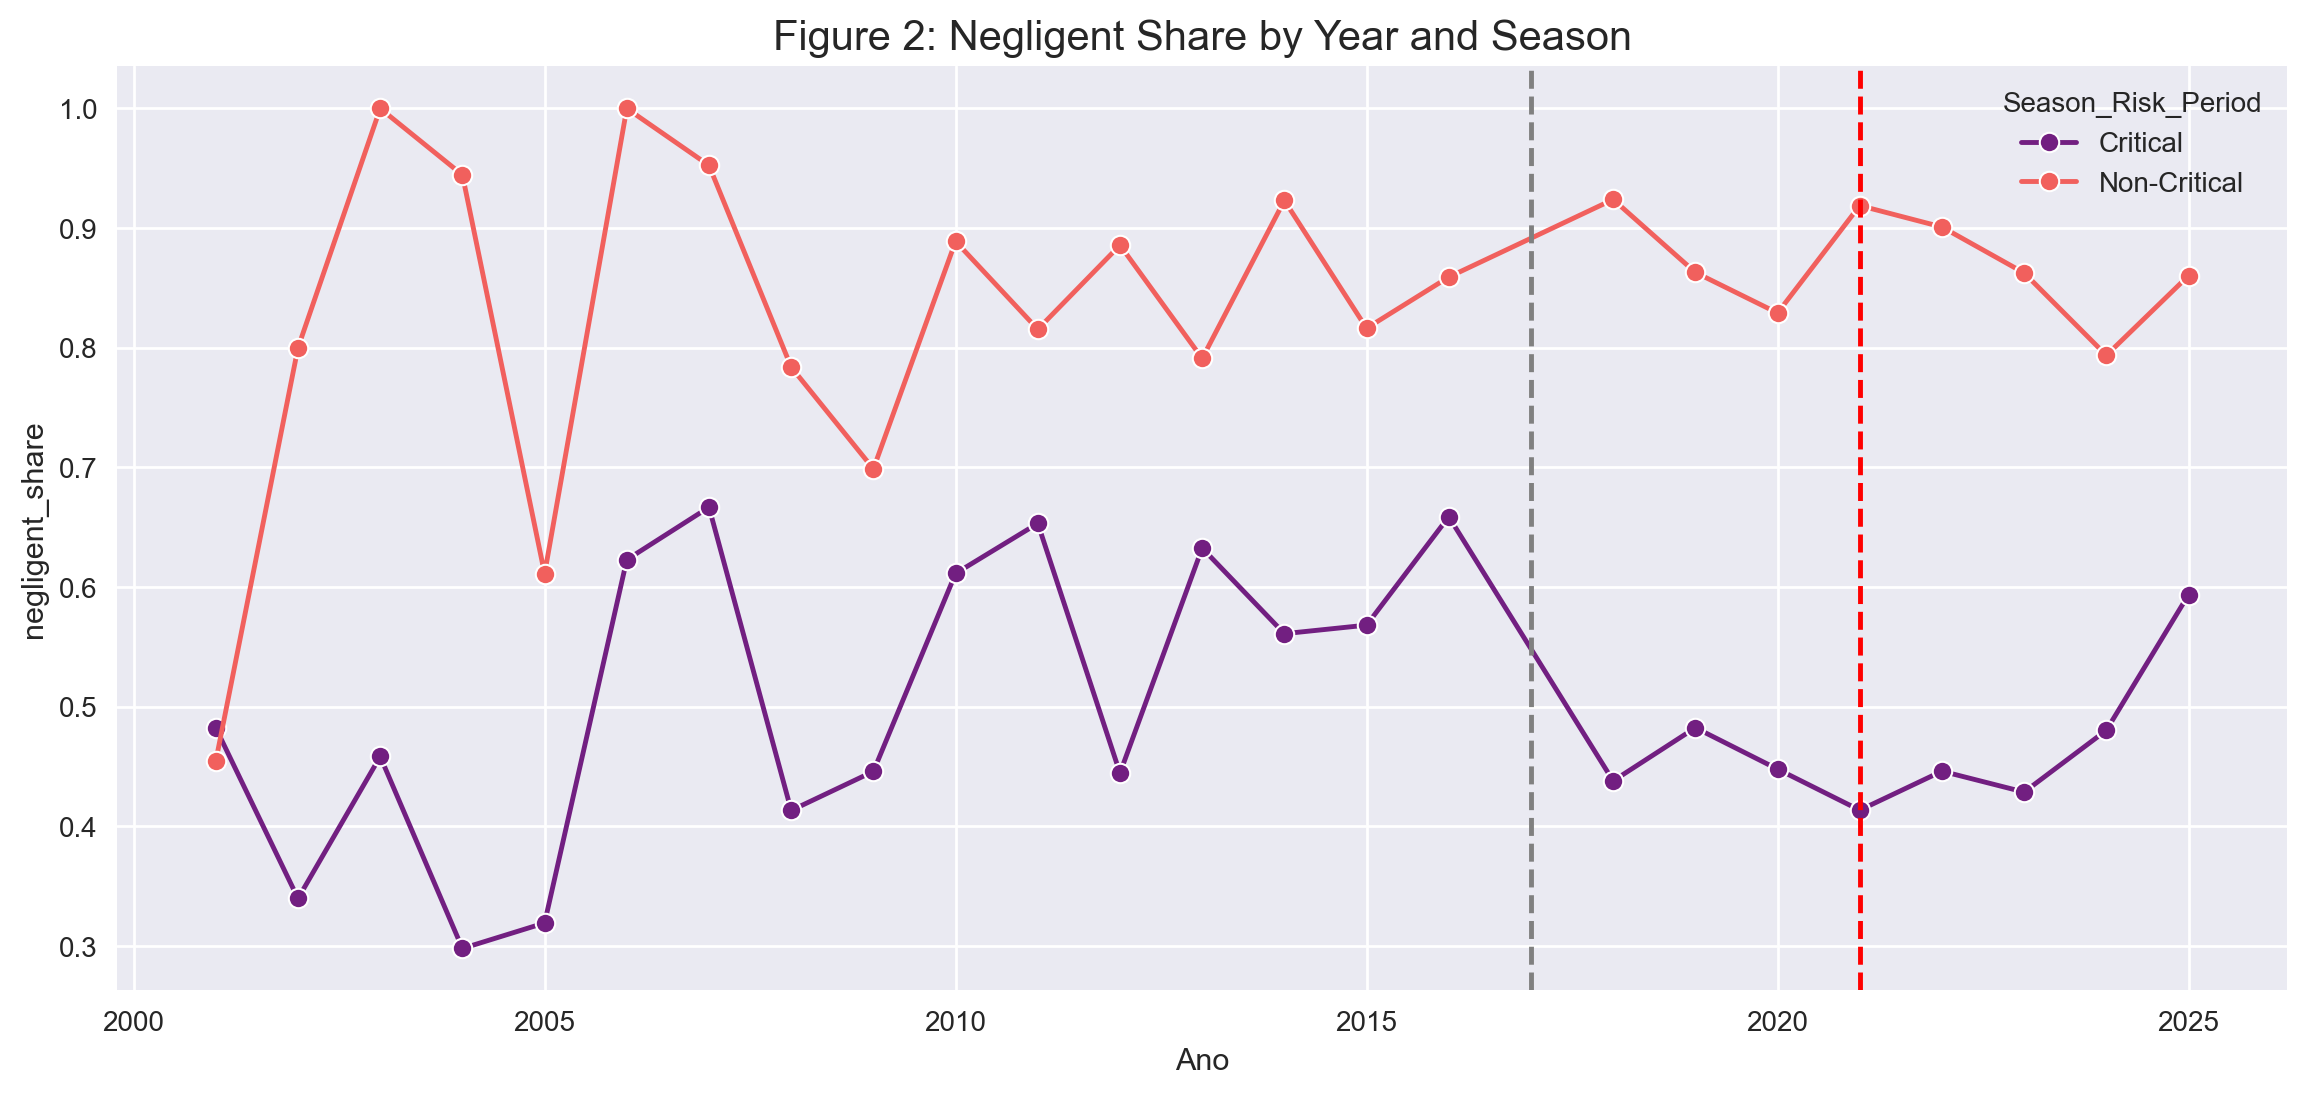

In [16]:
year_season = (
    q1.groupby(["Ano", "Season_Risk_Period"])["Cause_Type"]
      .apply(lambda s: (s == "Negligent").mean())
      .reset_index(name="negligent_share")
)

plt.figure(figsize=(14, 6))
sns.lineplot(data=year_season, x="Ano", y="negligent_share",
             hue="Season_Risk_Period", marker="o", palette="magma")
plt.axvline(2017, color="grey", linestyle="--")
plt.axvline(2021, color="red", linestyle="--")
plt.title("Figure 2: Negligent Share by Year and Season", fontsize=15)
plt.show()

#### Conclusions

To explore this question, we split the data into pre-2017 and post-2017 periods and compared the negligent share between critical and non-critical seasons. The visualisations and proportions showed a clear divergence between the seasons. In the critical period, the negligent share dropped from 55.7% to 47.4% after 2017. But, in the non-critical months, the share of negligent fires actually increased from 82.6% to 88.2%.

This means that the seasons do not behave in the same way, the reduction in negligent ignitions did not affect the whole year. It was entirely concentrated in the critical summer months.

Also, if the law implemented in 2021 actually deterred negligent ignitions, we would expect a sharp drop right after the red line in Figure 2. Instead, the non-critical line stays flat, and the critical line drops slightly in 2021 but climbs right back up by 2024/2025.

---

### Daily negligent wildfire ignitions across weekends and weekdays (Q2)

**Secondary Research Question 2:** *Did the mean number of daily negligent wildfire ignitions differ significantly between weekends and weekdays in the post-2017 period across the municipalities of Chaves, Montalegre, Ourém and Tomar?*

Before conducting inferential testing, we examine the sample distribution of daily negligent ignitions conditional on active fire days ($Y \ge 1$) across weekdays and weekends, contrasting the pre-2017 and post-2017 cohorts. **Methodological note on zero-area records ($0\text{ ha}$):** All validated negligent wildfire occurrences recorded in the SGIF database—including those with a final burnt area of $0\text{ ha}$ (such as immediate extinguishments)—are explicitly **retained** in the daily count aggregation (`Daily_Ignitions_Count`), as the research question evaluates ignition incidence rather than fire size. Because count variables present positive skewness, both robust measures (median, IQR) and parametric metrics (mean, standard deviation) are reported to fully assess central tendency and dispersion.

#### Data

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from scipy import stats
import seaborn as sns

# Configuração estética dos gráficos
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

# Carregar o dataset específico da Pergunta 2
processed_path = Path.cwd() / "01_dataset/processed"
q2 = pd.read_excel(processed_path / "q2_daily_ignitions.xlsx")

# Garantir tipos de dados corretos
q2["Date"] = pd.to_datetime(q2["Date"])
q2["Period"] = pd.Categorical(
    q2["Period"], categories=["Pre-2017", "Post-2017"], ordered=True
)
q2["Day_Type"] = pd.Categorical(
    q2["Day_Type"], categories=["Weekday", "Weekend"], ordered=True
)

q2.info()
q2.head()

<class 'pandas.DataFrame'>
RangeIndex: 2897 entries, 0 to 2896
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Concelho               2897 non-null   str           
 1   Date                   2897 non-null   datetime64[us]
 2   Period                 2897 non-null   category      
 3   Daily_Ignitions_Count  2897 non-null   int64         
 4   Day_Type               2897 non-null   category      
dtypes: category(2), datetime64[us](1), int64(1), str(1)
memory usage: 95.5 KB


,Concelho,Date,Period,Daily_Ignitions_Count,Day_Type
0,Chaves,2001-07-21,Pre-2017,1,Weekend
1,Chaves,2001-07-29,Pre-2017,1,Weekend
2,Chaves,2001-08-10,Pre-2017,1,Weekday
3,Chaves,2001-08-13,Pre-2017,1,Weekday
4,Chaves,2001-08-16,Pre-2017,1,Weekday


#### Descriptive statistics

In [ ]:
# Tabela com resumo estatístico por Período e Tipo de Dia
summary_stats = (
    q2.groupby(["Period", "Day_Type"], observed=False)["Daily_Ignitions_Count"]
    .agg(
        n="count",
        mean="mean",
        std="std",
        median="median",
        iqr=lambda x: x.quantile(0.75) - x.quantile(0.25),
        min="min",
        max="max",
    )
    .reset_index()
)

# Adicionar erro padrão da média (SEM)
summary_stats["sem"] = summary_stats["std"] / np.sqrt(summary_stats["n"])

print("Summary Statistics for Daily Negligent Ignitions:")
display(summary_stats.round(3))

Summary Statistics for Daily Negligent Ignitions:


,Period,Day_Type,n,mean,std,median,iqr,min,max,sem
0,Pre-2017,Weekday,1253,1.505,1.056,1.0,1.0,1,10,0.030
1,Pre-2017,Weekend,505,1.519,1.067,1.0,1.0,1,8,0.047
2,Post-2017,Weekday,802,1.455,1.161,1.0,0.0,1,11,0.041
3,Post-2017,Weekend,337,1.570,1.402,1.0,1.0,1,12,0.076


#### Distributions

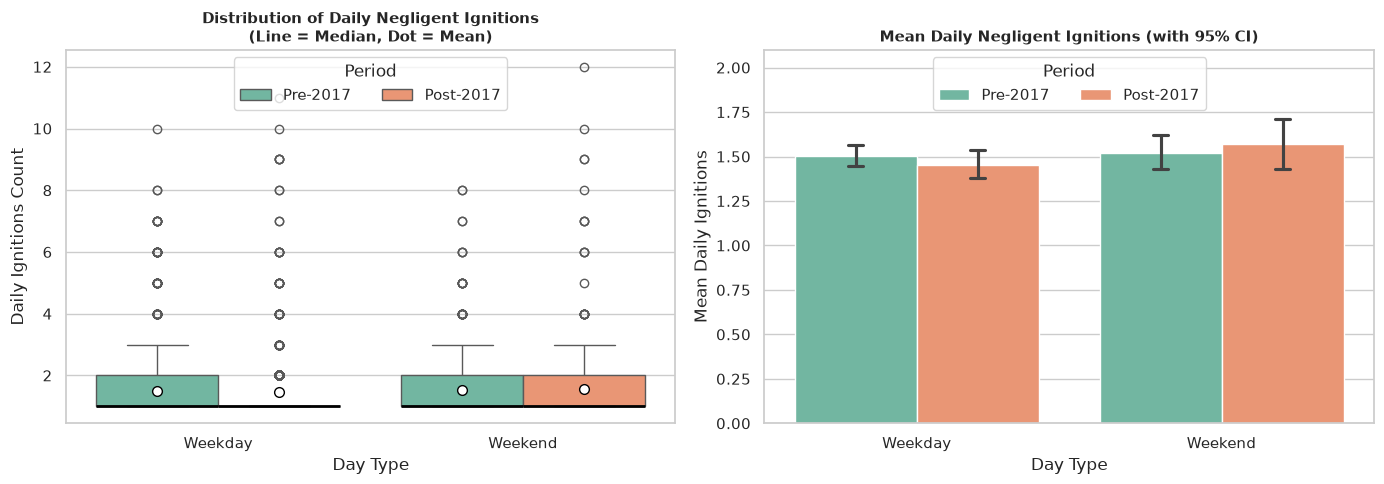

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Boxplot com legenda centrada no topo
sns.boxplot(
    data=q2,
    x="Day_Type",
    y="Daily_Ignitions_Count",
    hue="Period",
    palette="Set2",
    ax=axes[0],
    showmeans=True,
    meanprops={
        "marker": "o",
        "markerfacecolor": "white",
        "markeredgecolor": "black",
        "markersize": 7
    },
    medianprops={"color": "black", "linewidth": 2}
)
axes[0].set_title("Distribution of Daily Negligent Ignitions\n(Line = Median, Dot = Mean)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Day Type")
axes[0].set_ylabel("Daily Ignitions Count")
axes[0].legend(title="Period", loc="upper center", ncol=2)

# 2. Barplot de Médias com legenda centrada no topo
sns.barplot(
    data=q2,
    x="Day_Type",
    y="Daily_Ignitions_Count",
    hue="Period",
    palette="Set2",
    errorbar=("ci", 95),
    capsize=0.1,
    ax=axes[1]
)
axes[1].set_title("Mean Daily Negligent Ignitions (with 95% CI)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Day Type")
axes[1].set_ylabel("Mean Daily Ignitions")
axes[1].set_ylim(0, 2.1)
axes[1].legend(title="Period", loc="upper center", ncol=2)

plt.tight_layout()
plt.show()

---

### Burnt Area per Fire across Municipalities (Q3)

**What the ANOVA compares.** For strictly positive areas, the mean of ln(area) is the logarithm of the *geometric mean* of the area. Therefore, comparing means of ln(area) is equivalent to comparing geometric means (the "typical" fire) on the original scale, and differences become **ratios**. The ANOVA does **not** directly test equality of the *arithmetic* mean burnt area in hectares; the arithmetic means are reported only as descriptive statistics.

**Why the logarithm?** Burnt areas are extremely right-skewed (a few huge fires and many tiny ones). Sections 03–05 show that the classical ANOVA assumptions are not met on the original scale but are reasonably met on the log scale.

We describe the data before testing. Descriptive differences below are **not** evidence of significant differences. The original area (hectares) is used for the descriptive statistics; the **geometric mean** is the quantity that the ANOVA on ln(area) will compare, so it is shown next to the arithmetic mean and the median.

- **Arithmetic mean:** average area (very sensitive to huge fires). **Median:** the middle fire. **Geometric mean:** exp(mean of ln area), for fires with area > 0.  
- **Q1/Q3:** 25 % / 75 % of fires have an area below these values; **IQR** = Q3 − Q1.

In [ ]:
groups = {m: q4.loc[q4["Concelho"] == m, Y].to_numpy() for m in MUNICIPALITIES}                   # original scale (ha), n = 2,739
ln_groups = {m: q4_ln.loc[q4_ln["Concelho"] == m, "ln_area"].to_numpy() for m in MUNICIPALITIES}  # ln(ha), n = 2,738

def describe(a):
    a = pd.Series(a); q1, q3 = a.quantile(.25), a.quantile(.75); pos = a[a > 0]
    return pd.Series({"n": len(a), "arithmetic mean": a.mean(), "median": a.median(), "geometric mean": np.exp(np.log(pos).mean()),
                      "sd": a.std(ddof=1), "variance": a.var(ddof=1), "min": a.min(), "q1": q1, "q3": q3, "iqr": q3 - q1,
                      "p90": a.quantile(.90), "p99": a.quantile(.99), "max": a.max(),
                      "% zero": 100 * (a == 0).mean(), "% < 1 ha": 100 * (a < 1).mean()})

summary = pd.DataFrame({m: describe(groups[m]) for m in MUNICIPALITIES}).T
summary.loc["All"] = describe(q4[Y].to_numpy())
print("Burnt area per fire, original scale (hectares). Geometric mean computed for areas > 0.")
print(summary.round(3).to_string())

g = summary.loc[MUNICIPALITIES]
print()
print("Ranking by arithmetic mean:", " > ".join(g["arithmetic mean"].sort_values(ascending=False).index))
print("Ranking by median         :", " > ".join(g["median"].sort_values(ascending=False).index))
print("Ranking by geometric mean :", " > ".join(g["geometric mean"].sort_values(ascending=False).index))
print(f"Largest/smallest sample variance (original scale): {g['variance'].max() / g['variance'].min():.1f}")

# Influence of the largest fires on the arithmetic mean (descriptive)
rows = []
for m in MUNICIPALITIES:
    a = np.sort(groups[m])
    rows.append({"municipality": m, "arithmetic mean (ha)": a.mean(), "mean without its 5 largest fires (ha)": a[:-5].mean(),
                 "share of area in 5 largest fires (%)": 100 * a[-5:].sum() / a.sum(), "largest fire (ha)": a[-1]})
print()
print(pd.DataFrame(rows).set_index("municipality").round(2).to_string())

Burnt area per fire, original scale (hectares). Geometric mean computed for areas > 0.
                 n  arithmetic mean  median  geometric mean       sd   variance  min     q1     q3    iqr     p90      p99       max  % zero  % < 1 ha
Chaves       555.0           18.125   0.158           0.139  191.871  36814.377  0.0  0.010  0.962  0.952   3.000  311.852  3367.930   0.000    75.315
Montalegre  1146.0           13.682   0.772           0.505  130.046  16911.923  0.0  0.100  3.038  2.938  21.145  167.993  4147.733   0.000    66.492
Ourém        620.0           13.869   0.054           0.051  159.285  25371.664  0.0  0.012  0.196  0.183   1.117  212.112  2936.000   0.161    89.516
Tomar        418.0            3.172   0.045           0.041   35.486   1259.224  0.0  0.010  0.202  0.191   0.502   23.690   606.525   0.000    93.780
All         2739.0           13.021   0.162           0.158  143.072  20469.475  0.0  0.017  0.900  0.883   7.500  171.175  4147.733   0.037    77.656

Rankin

#### Figure 1 — Burnt area per fire by municipality

The boxes show the typical fire (median and quartiles) and the points show the extremes. The vertical axis is **logarithmic** (each gridline is ×10), because on the raw scale a few fires thousands of times larger than the rest would squash the boxes flat. The diamond is the **geometric mean**, the quantity compared by the ANOVA (it is not the arithmetic mean).

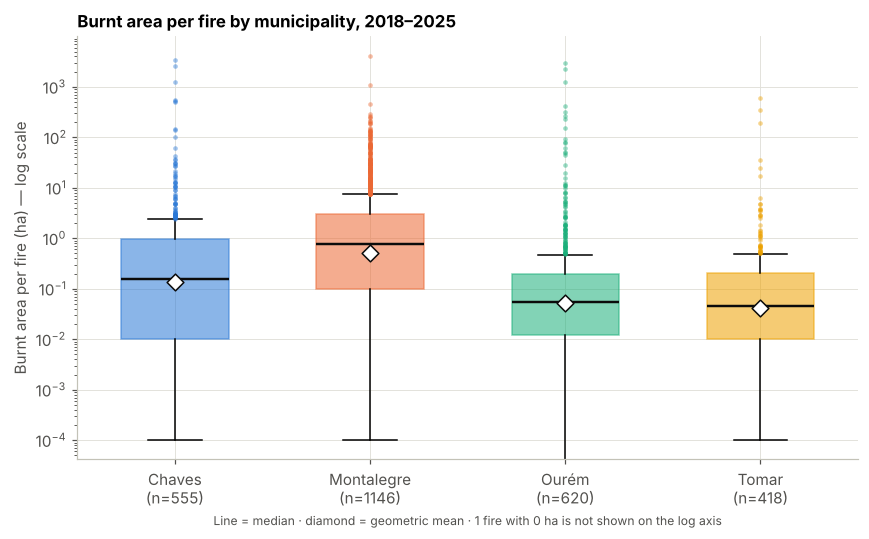

In [ ]:
labels_n = [f"{m}\n(n={len(groups[m])})" for m in MUNICIPALITIES]
fig, ax = plt.subplots(figsize=(8, 5))
bp = ax.boxplot([groups[m] for m in MUNICIPALITIES], patch_artist=True, widths=0.55,
                flierprops=dict(marker="o", markersize=3, alpha=.45, markeredgewidth=0),
                medianprops=dict(color="#0b0b0b", linewidth=1.6))
for patch, fl, m in zip(bp["boxes"], bp["fliers"], MUNICIPALITIES):
    patch.set(facecolor=COLORS[m], alpha=.55, edgecolor=COLORS[m]); fl.set(markerfacecolor=COLORS[m], markeredgecolor=COLORS[m])
ax.scatter(range(1, 5), [np.exp(ln_groups[m].mean()) for m in MUNICIPALITIES], marker="D", s=60,
           facecolor="white", edgecolor="#0b0b0b", zorder=4)
ax.set_xticks(range(1, 5)); ax.set_xticklabels(labels_n)
ax.set_yscale("log"); ax.set_ylabel("Burnt area per fire (ha) — log scale")
ax.set_title("Burnt area per fire by municipality, 2018–2025")
ax.set_xlabel(f"Line = median · diamond = geometric mean · {int((q4[Y] == 0).sum())} fire with 0 ha is not shown on the log axis", fontsize=8)
plt.tight_layout(); plt.show()

#### Figure 2 — How much do a few fires and a few years matter?

(a) Fires sorted from largest to smallest; the curve gives the cumulative share of total burnt area. (b) Total burnt area (hectares, original scale) by year and municipality.

Ano
2018     0.9
2019     5.2
2020    11.2
2021     6.2
2022    41.2
2023     5.6
2024     6.1
2025    23.6
Largest 1 % of fires hold 71.2 % of the total area ( 28 fires )


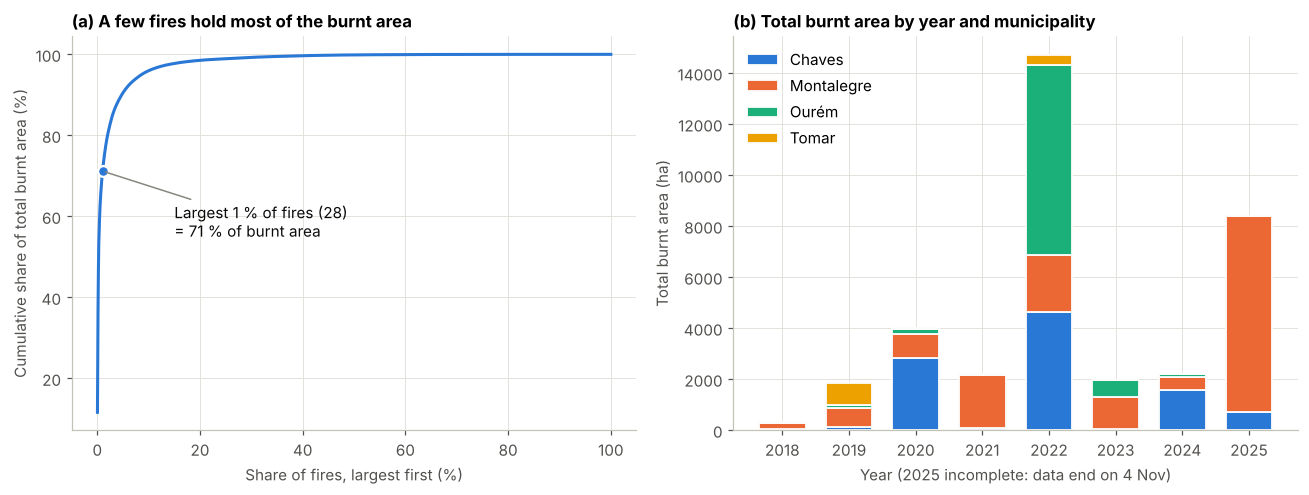

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

ax = axes[0]
a = np.sort(q4[Y].to_numpy())[::-1]
share_fires = np.arange(1, len(a) + 1) / len(a); share_area = np.cumsum(a) / a.sum()
ax.plot(100 * share_fires, 100 * share_area, color="#2a78d6", linewidth=2)
k_top = int(np.ceil(0.01 * len(a)))
ax.scatter([100 * k_top / len(a)], [100 * share_area[k_top - 1]], color="#2a78d6", s=50, zorder=3, edgecolor="#fcfcfb", linewidth=1.5)
ax.annotate(f"Largest 1 % of fires ({k_top})\n= {100 * share_area[k_top - 1]:.0f} % of burnt area", xy=(100 * k_top / len(a), 100 * share_area[k_top - 1]),
            xytext=(15, 55), arrowprops=dict(arrowstyle="-", color="#898781"), color="#0b0b0b")
ax.set_xlabel("Share of fires, largest first (%)"); ax.set_ylabel("Cumulative share of total burnt area (%)")
ax.set_title("(a) A few fires hold most of the burnt area")

ax = axes[1]
by_year = q4.pivot_table(index="Ano", columns="Concelho", values=Y, aggfunc="sum", observed=True)[MUNICIPALITIES]
bottom = np.zeros(len(by_year))
for m in MUNICIPALITIES:
    ax.bar(by_year.index, by_year[m], bottom=bottom, color=COLORS[m], label=m, edgecolor="#fcfcfb", linewidth=1.2, width=.7)
    bottom += by_year[m].to_numpy()
ax.set_ylabel("Total burnt area (ha)"); ax.set_xlabel("Year (2025 incomplete: data end on 4 Nov)")
ax.set_title("(b) Total burnt area by year and municipality"); ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

yr = by_year.sum(axis=1)
print((100 * yr / yr.sum()).round(1).rename("% of total burnt area").to_string())
print("Largest 1 % of fires hold", round(100 * share_area[k_top - 1], 1), "% of the total area (", k_top, "fires )")

#### Interpretation of the EDA (descriptive only)

- **Many small fires, a few giant ones.** 77.7 % of fires burn less than 1 ha, yet the 28 largest (1 %) account for 71.2 % of the burnt area. The overall arithmetic mean (13.0 ha) is about 80 times the median (0.16 ha).
- **Arithmetic mean, median and geometric mean rank the municipalities differently.** By arithmetic mean: Chaves (18.1) > Ourém (13.9) > Montalegre (13.7) > Tomar (3.2 ha). By median and by geometric mean: Montalegre > Chaves > Ourém > Tomar (geometric means ≈ 0.50, 0.14, 0.05 and 0.04 ha). The arithmetic means are driven by a handful of huge fires: the five largest fires hold 83 % (Chaves), 84 % (Ourém), 91 % (Tomar) and 40 % (Montalegre) of the area of each municipality.
- **A few years dominate:** 2022 holds 41.2 % and 2025 (incomplete) 23.6 % of the burnt area.
- **Spread.** On the original scale the sample variances differ by a factor of 29 between municipalities.
- No negative or missing areas were found, and the largest fires are internally consistent records.

---

### Burnt Area by Cause Type and Period (Q4)

In this section we address Q4, which asks whether the gap in final burnt area between intentional and negligent fires became smaller after 2017 in the four municipalities under study.

The burnt area is analysed on a log10 scale because it is extremely right-skewed, with most fires below 1 ha and a few above 1,000 ha. On this scale, the mean corresponds to the geometric mean, which describes the typical fire better than the arithmetic mean.

#### Data 

In [17]:
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

q4 = pd.read_excel(processed / "q4_burnt_area_cause_period.xlsx")

# fixed order of the factor levels for tables and plots
period_order = ["Pre-2017", "Post-2017"]
cause_order = ["Intentional", "Negligent"]
q4["Period"] = pd.Categorical(q4["Period"], categories=period_order, ordered=True)
q4["Cause_Type"] = pd.Categorical(q4["Cause_Type"], categories=cause_order, ordered=True)

pd.crosstab(q4["Cause_Type"], q4["Period"], margins=True)

Period,Pre-2017,Post-2017,All
Cause_Type,,,
Intentional,1381,789,2170
Negligent,2653,1696,4349
All,4034,2485,6519


#### Descriptive statistics

In [18]:
q4_desc = (
    q4.groupby(["Period", "Cause_Type"], observed=True)
      .agg(n=("Log_Total_Burnt_Area", "size"),
           mean_log=("Log_Total_Burnt_Area", "mean"),
           sd_log=("Log_Total_Burnt_Area", "std"),
           median_ha=("Total_Burnt_Area", "median"),
           mean_ha=("Total_Burnt_Area", "mean"))
)
# geometric mean in hectares (back-transformation of the log mean)
q4_desc["geom_mean_ha"] = 10 ** q4_desc["mean_log"]
q4_desc.round(3)

n  mean_log  sd_log  median_ha  mean_ha  \
Period    Cause_Type                                                
Pre-2017  Intentional  1381    -0.553   1.228      0.260   24.761   
          Negligent    2653    -0.395   1.109      0.500    8.622   
Post-2017 Intentional   789    -0.934   1.195      0.085   23.227   
          Negligent    1696    -0.634   1.170      0.290    8.726   

                       geom_mean_ha  
Period    Cause_Type                 
Pre-2017  Intentional         0.280  
          Negligent           0.403  
Post-2017 Intentional         0.116  
          Negligent           0.232

The design is unbalanced (from 789 to 2,653 fires per group), but every group is large. The table also shows why the log scale is needed. Intentional fires have a much higher arithmetic mean (around 23 to 25 ha vs 9 ha), but a lower median (0.26 vs 0.50 ha before 2017), because a few very large intentional fires inflate the mean. The geometric means agree with the medians.

#### Distribution of burnt area by group

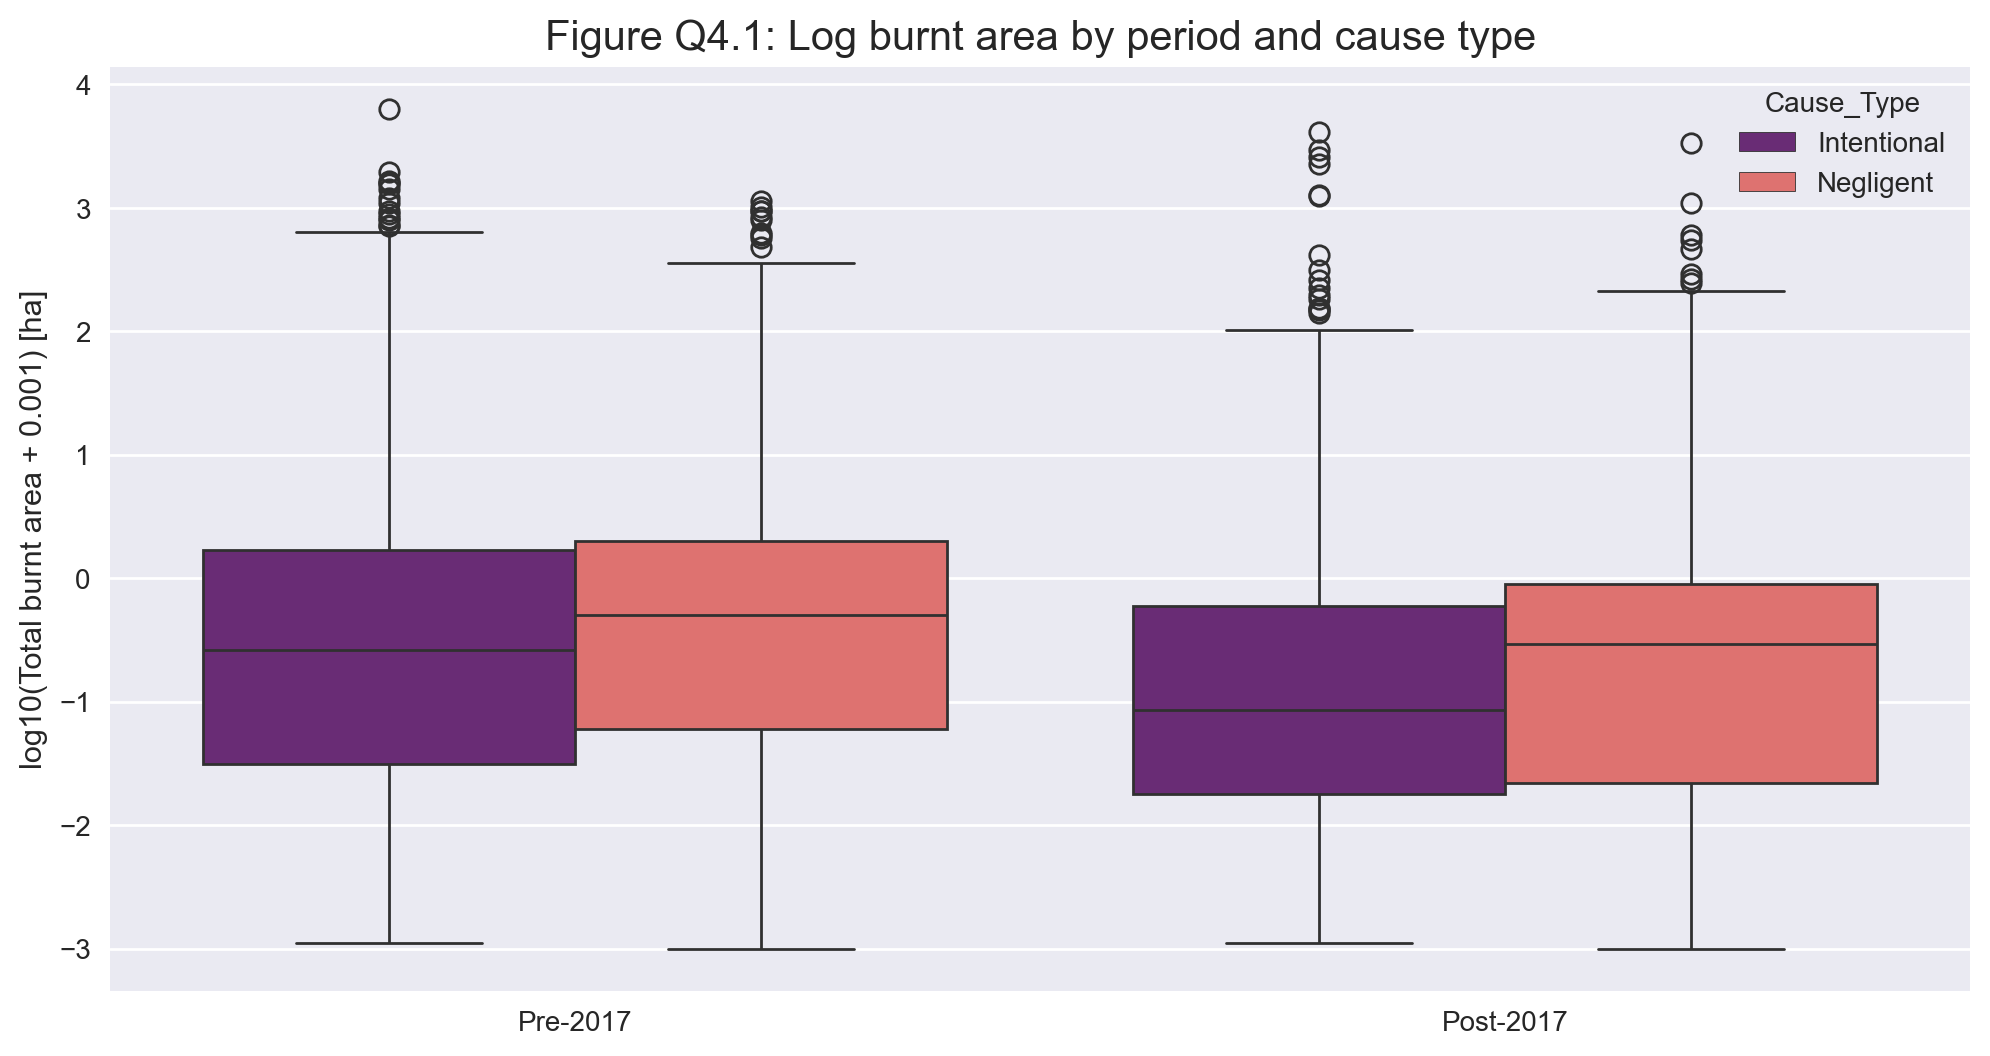

In [19]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=q4, x="Period", y="Log_Total_Burnt_Area", hue="Cause_Type",
            order=period_order, hue_order=cause_order, palette="magma", ax=ax)
ax.set_title("Figure Q4.1: Log burnt area by period and cause type", fontsize=15)
ax.set_ylabel("log10(Total burnt area + 0.001) [ha]")
ax.set_xlabel("")
plt.show()

In [20]:
# Numbers behind Figure Q4.1 (boxplot statistics on the log scale)
box_rows = []
for (cause, period), g in q4.groupby(["Cause_Type", "Period"], observed=True):
    x = g["Log_Total_Burnt_Area"]
    area = g["Total_Burnt_Area"]
    q1, med, q3 = x.quantile([0.25, 0.5, 0.75])
    iqr = q3 - q1
    box_rows.append({
        "Cause_Type": cause,
        "Period": period,
        "min": x.min(),
        "lower_whisker": x[x >= q1 - 1.5 * iqr].min(),
        "Q1": q1,
        "median": med,
        "Q3": q3,
        "upper_whisker": x[x <= q3 + 1.5 * iqr].max(),
        "max": x.max(),
        "n_outliers_upper": (x > q3 + 1.5 * iqr).sum(),
        "n_outliers_lower": (x < q1 - 1.5 * iqr).sum(),
        "n_0_ha": (area == 0).sum(),
        "n_0.01_ha": (area == 0.01).sum(),
    })
pd.DataFrame(box_rows).round(3)

,Cause_Type,Period,min,lower_whisker,Q1,median,Q3,upper_whisker,max,n_outliers_upper,n_outliers_lower,n_0_ha,n_0.01_ha
0,Intentional,Pre-2017,-2.959,-2.959,-1.509,-0.583,0.231,2.801,3.805,14,0,0,76
1,Intentional,Post-2017,-2.959,-2.959,-1.745,-1.066,-0.221,2.008,3.618,16,0,0,32
2,Negligent,Pre-2017,-3.000,-3.000,-1.223,-0.300,0.301,2.556,3.060,10,0,2,268
3,Negligent,Post-2017,-3.000,-3.000,-1.658,-0.536,-0.045,2.324,3.527,8,0,1,229


In [21]:
# Most frequent burnt area values (in ha)
q4["Total_Burnt_Area"].value_counts().head(6)

Total_Burnt_Area
0.01    605
0.50    442
1.00    375
2.00    227
0.10    193
1.50    166
Name: count, dtype: int64

Figure Q4.1 shows that the four distributions overlap heavily, as expected for a variable with high natural variability. Even so, the median of negligent fires is higher than that of intentional fires in both periods (-0.30 vs -0.58 before 2017 and -0.54 vs -1.07 after 2017), and all medians are lower after 2017. The lower whiskers reach about -3 because of very small fires (0.0001 ha or 0 ha). Areas are often recorded as rounded values, and 0.01 ha is the most frequent value (605 fires).

#### Interaction plot 

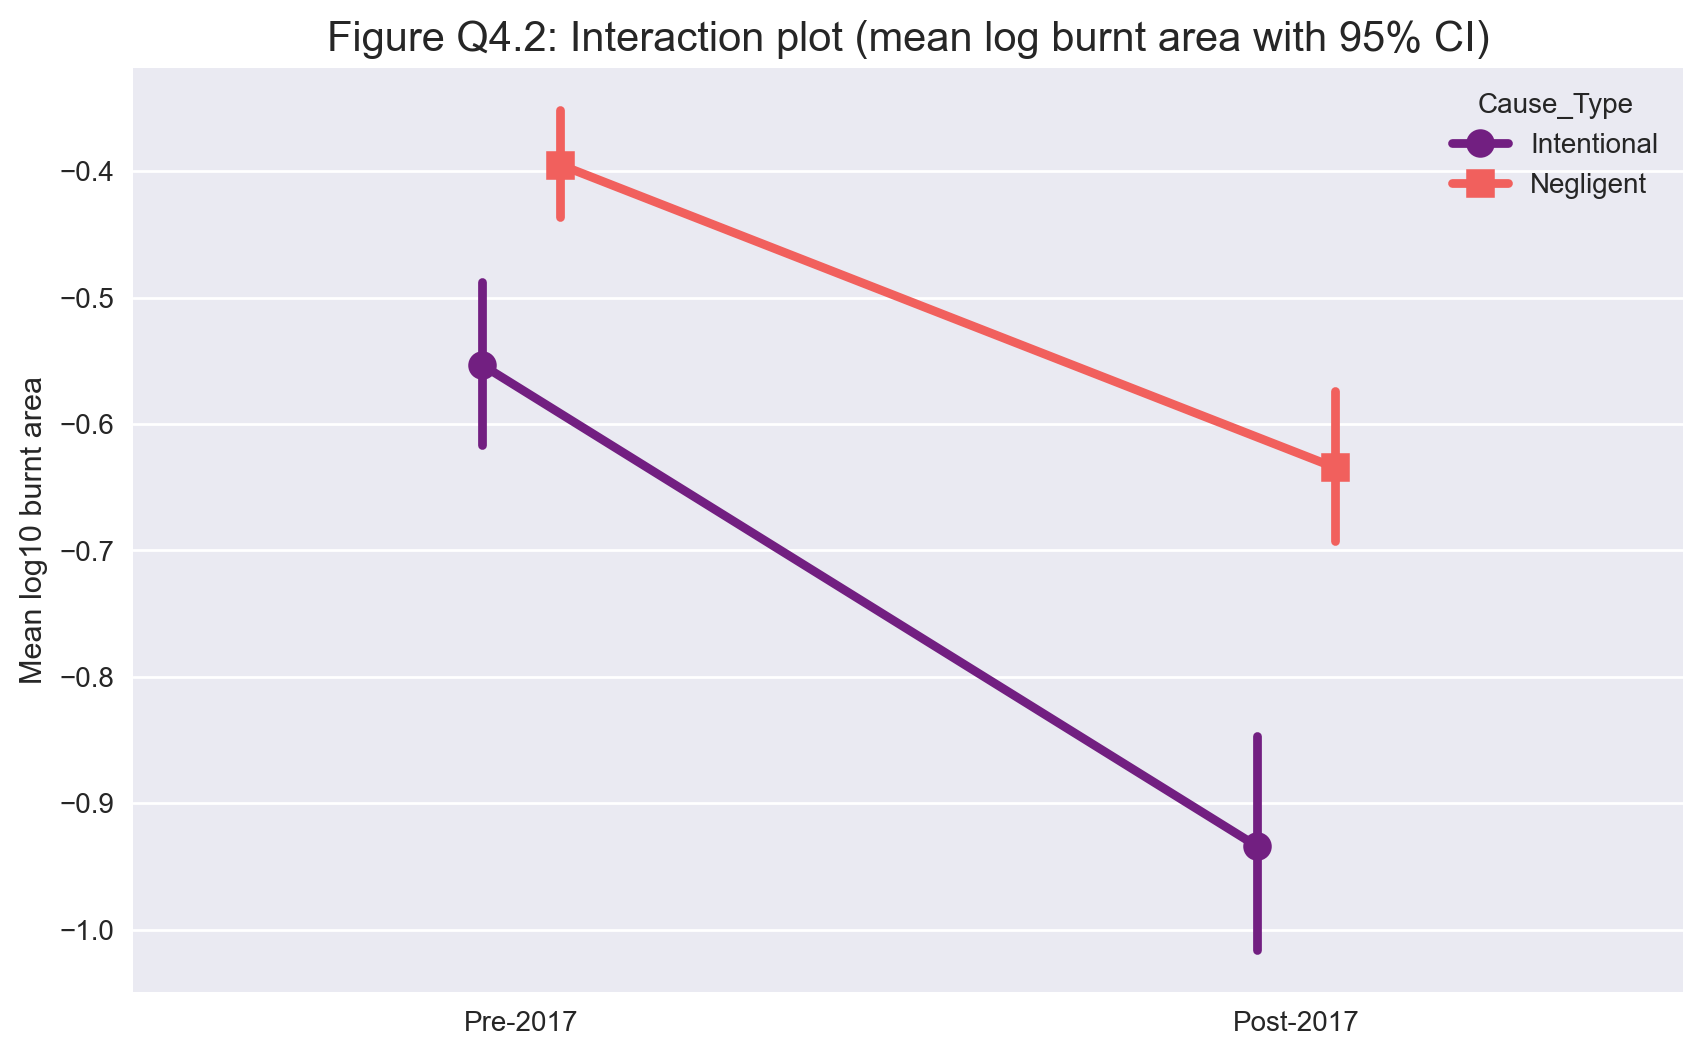

In [22]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.pointplot(data=q4, x="Period", y="Log_Total_Burnt_Area", hue="Cause_Type",
              order=period_order, hue_order=cause_order, palette="magma",
              errorbar=("ci", 95), dodge=0.1, markers=["o", "s"], ax=ax)
ax.set_title("Figure Q4.2: Interaction plot (mean log burnt area with 95% CI)", fontsize=15)
ax.set_ylabel("Mean log10 burnt area")
ax.set_xlabel("")
plt.show()

In [23]:
# Numbers behind Figure Q4.2
q4_means = (
    q4.groupby(["Period", "Cause_Type"], observed=True)["Log_Total_Burnt_Area"]
      .agg(n="size", mean="mean", sd="std")
)
q4_means["se"] = q4_means["sd"] / np.sqrt(q4_means["n"])
t_crit = stats.t.ppf(0.975, q4_means["n"] - 1)
q4_means["ci_low"] = q4_means["mean"] - t_crit * q4_means["se"]
q4_means["ci_high"] = q4_means["mean"] + t_crit * q4_means["se"]
display(q4_means.round(3))

m = q4_means["mean"].unstack()
drop = m.loc["Pre-2017"] - m.loc["Post-2017"]
gap = m["Negligent"] - m["Intentional"]
print("Drop after 2017 (log units):")
print(drop.round(3))
print("\nGap Negligent - Intentional (log units):")
print(gap.round(3))
print(f"\nChange in the gap: {gap['Post-2017'] - gap['Pre-2017']:.3f}")

n   mean     sd     se  ci_low  ci_high
Period    Cause_Type                                             
Pre-2017  Intentional  1381 -0.553  1.228  0.033  -0.618   -0.488
          Negligent    2653 -0.395  1.109  0.022  -0.437   -0.352
Post-2017 Intentional   789 -0.934  1.195  0.043  -1.018   -0.851
          Negligent    1696 -0.634  1.170  0.028  -0.690   -0.579

Drop after 2017 (log units):
Cause_Type
Intentional    0.381
Negligent      0.240
dtype: float64

Gap Negligent - Intentional (log units):
Period
Pre-2017     0.159
Post-2017    0.300
dtype: float64

Change in the gap: 0.141


Figure Q4.2 is the most direct visual answer to the research question. If the gap between causes had narrowed after 2017, the two lines would converge. Instead, they move slightly apart. The mean for intentional fires drops by 0.38 log units (from -0.55 to -0.93), while the mean for negligent fires drops by 0.24 (from -0.39 to -0.63). As a result, the gap between causes goes from 0.16 to 0.30 log units, an increase of 0.14.

#### Conclusions

The descriptive analysis suggests that the gap between causes did not narrow after 2017. In both periods, the typical negligent fire burnt a larger area than the typical intentional fire, and all groups had smaller fires after 2017. Intentional fires decreased more, so the two lines in Figure Q4.2 move slightly apart. Whether these differences are statistically significant is tested in Section 4.

---

## 4) Statistical Modelling

### Model Overview: Z-test for Proportions (Q1)

To determine if the change post-2017 was concentrated in the critical period (1st of june to 30th of september) or also affected the traditional months, we ran a two-proportion Z-test separately for the Critical and Non-Critical periods.

If the reduction in negligent causes was concentrated in the  critical period, we would expect a significant drop in the Critical period and no significant change (or an increase) in the Non-Critical period.

#### Terminology

* **$p_1$**: The proportion of negligent fires in the Pre-2017 period.
* **$p_2$**: The proportion of negligent fires in the Post-2017 period.
* **$n_1$**: The total number of human-caused fires in the Pre-2017 period.
* **$n_2$**: The total number of human-caused fires in the Post-2017 period.
* **$\alpha$**: The significance level, set at 0.05.

##### Hypothesis
* **$H_0$**: $p_1 = p_2$ (the proportion of negligent fires is the same before and after 2017).
* **$H_1$**: $p_1 \neq p_2$ (the proportion of negligent fires changed after 2017).

#### Methodology

We use a two-proportion Z-test for each season separately:

* **Critical Period:** Pre-2017 ($n_1 = 2531$) vs. Post-2017 ($n_2 = 1215$).
* **Non-Critical Period:** Pre-2017 ($n_1 = 1503$) vs. Post-2017 ($n_2 = 1270$).




#### Assumptions

1. **Independence:** The fires are independent observations.
2. **Large Sample Size:** The smallest cell count is 576 (Post-2017 Critical Negligent)

#### Z and p-value

In [24]:

import statsmodels.stats.proportion as smp

# Critical Period
z_crit, p_crit = smp.proportions_ztest([576, 1411], [1215, 2531])

# Non-Critical Period
z_non, p_non = smp.proportions_ztest([1120, 1242], [1270, 1503])

print(f"Critical Period: Z = {z_crit:.4f}, p-value = {p_crit:.4e}")
print(f"Non-Critical Period: Z = {z_non:.4f}, p-value = {p_non:.4e}")

Critical Period: Z = -4.7887, p-value = 1.6784e-06
Non-Critical Period: Z = 4.1013, p-value = 4.1085e-05


#### Conclusion

**Critical Period:**

Because the p-value is less than 0.05, we reject H₀. 

The Z-value of -4.7887 is negative, which tells us the direction of the change: the proportion of negligent fires in the critical period significantly decreased from 55.7% to 47.4% post-2017.

**Non-Critical Period:**

Because the p-value is less than 0.05, we also reject H₀. 

The Z-value of 4.1013 is positive, meaning the proportion of negligent fires in the non-critical period significantly increased from 82.6% to 88.2% post-2017.

**Overall Q1 Conclusion:**

The change in negligent causes was not uniform, so the reduction was not spread across the whole year. It was concentrated entirely in the critical summer period. The traditional burning months did not benefit from the same improvement. Instead, they saw a significant increase in negligent behaviour, meaning negligent fires remain a persistent challenge in the non-critical months.

---

### Model Overview: t-test for Mean (Q2)

### 4.1 Terminology & Hypothesis Formulation
We aim to test whether the mean number of daily negligent ignitions differs significantly between weekends and weekdays in the post-2017 period:

- **Parameters of Interest:**
  - $\mu_{\text{Weekend}}$: Population mean number of daily negligent ignitions on active weekend days in the post-2017 period ($n_1 = 337$).
  - $\mu_{\text{Weekday}}$: Population mean number of daily negligent ignitions on active weekdays in the post-2017 period ($n_2 = 802$).
- **Null Hypothesis ($H_0$):** $\mu_{\text{Weekend}} - \mu_{\text{Weekday}} = 0$ (There is no difference in the population mean daily negligent ignitions between weekends and weekdays).
- **Alternative Hypothesis ($H_1$):** $\mu_{\text{Weekend}} - \mu_{\text{Weekday}} \neq 0$ (Two-sided: the population mean daily negligent ignitions differ between weekends and weekdays).
- **Significance Level:** $\alpha = 0.05$.


### 4.2 Checking the Assumptions
A two-sample $t$-test requires three conditions:
1. **Independence:** Each observation represents a distinct municipal active fire day (`Concelho` $\times$ `Date`). While synoptic weather conditions can induce spatial/temporal clustering (discussed in the limitations at the end of the notebook), observations across weekdays and weekends are treated as independent samples.
2. **Normality:** Assessed below via histograms, Normal Q-Q plots, skewness, excess kurtosis, and the Shapiro-Wilk test within each group. Because daily ignition counts are discrete and strongly right-skewed ($Y \ge 1$, skewness $\approx 4$, excess kurtosis $\approx 20$), normality of the raw observations is clearly rejected ($p < 0.001$ in both groups). However, given the large sample sizes ($n_{\text{Weekend}} = 337 \ge 30$ and $n_{\text{Weekday}} = 802 \ge 30$), the sampling distribution of the sample means is **approximately normal by the Central Limit Theorem (CLT)**, although the strong positive skewness may slow the rate of convergence.
3. **Homoscedasticity (Equal Variances):** Evaluated via the sample variance ratio and both mean-centered (Levene) and median-centered (Brown-Forsythe) tests. Notice that the two tests may disagree because mean-centered Levene is sensitive to the heavy right tail ($p < 0.05$), whereas median-centered Brown-Forsythe is more robust to skewness ($p > 0.05$). Regardless of whether equal variances hold, **Welch's two-sample $t$-test** (`equal_var=False`) is used as the primary parametric test because it adjusts the degrees of freedom (Welch-Satterthwaite) and remains valid in both cases.

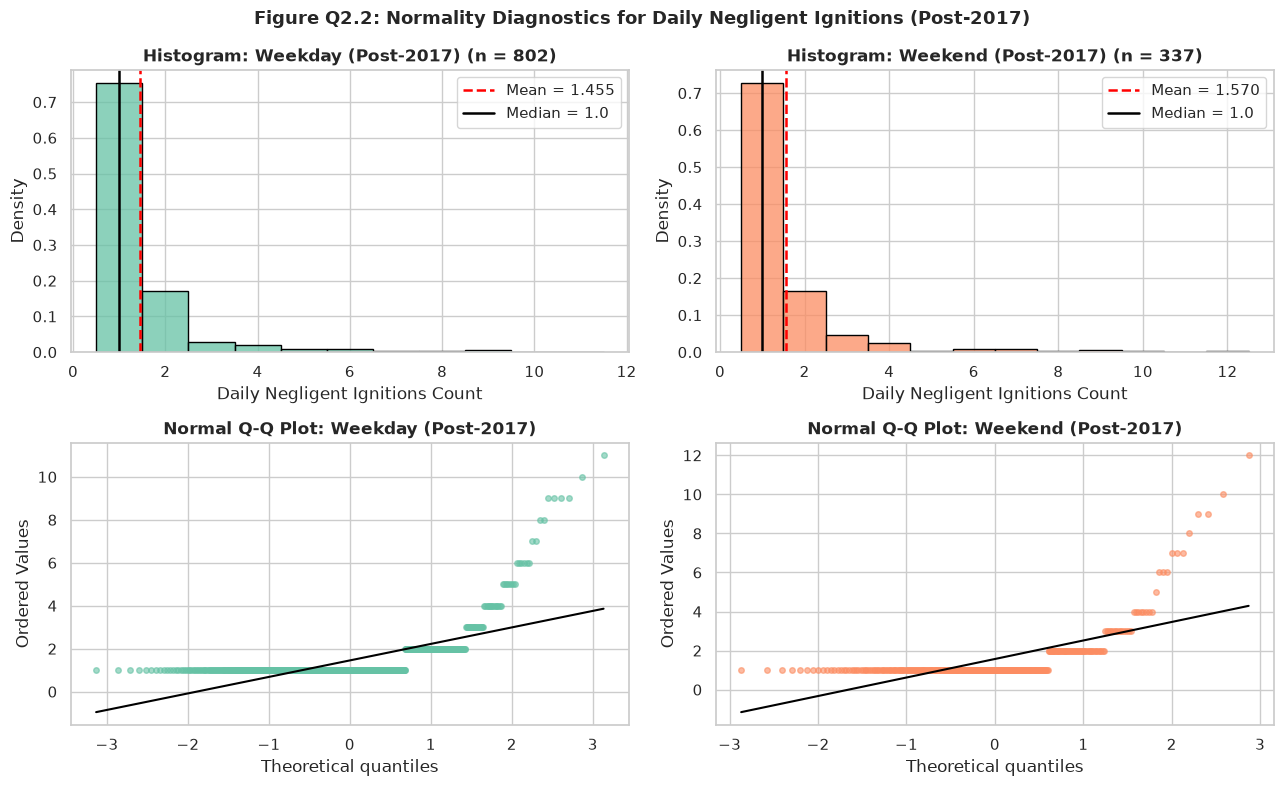

=== ASSUMPTION 1: NORMALITY & CLT DIAGNOSTICS ===


,Group (Post-2017),n,Mean,SD,Variance,Skewness,Excess_Kurtosis,Shapiro_W,Shapiro_p,CLT_Applies (n >= 30)
0,Weekday,802,1.4551,1.1606,1.3469,4.2565,22.3345,0.4379,< 0.001,True
1,Weekend,337,1.5697,1.4022,1.9661,4.0247,19.3698,0.4568,< 0.001,True



=== ASSUMPTION 2: HOMOSCEDASTICITY (EQUALITY OF VARIANCES) ===
Variance Ratio (max / min): 1.460 (SD Ratio: 1.208)
Levene's Test (mean-centered):   W = 4.8690, p-value = 0.0275
Brown-Forsythe (median-centered): W = 2.0377, p-value = 0.1537
Note: Mean-centered Levene and median-centered Brown-Forsythe can disagree due to strong right-skewness; Welch's t-test (equal_var=False) remains valid in both cases.


In [ ]:
# Filtrar para a análise do período pós-2017
post_data = q2[q2["Period"] == "Post-2017"].copy()

weekday_post = post_data[post_data["Day_Type"] == "Weekday"]["Daily_Ignitions_Count"]
weekend_post = post_data[post_data["Day_Type"] == "Weekend"]["Daily_Ignitions_Count"]

# 1. Diagnóstico Visual de Normalidade: Histogramas + Q-Q Plots (Post-2017)
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
groups_post = [("Weekday (Post-2017)", weekday_post, "#66c2a5"),
               ("Weekend (Post-2017)", weekend_post, "#fc8d62")]

for i, (label, serie, color) in enumerate(groups_post):
    # Histograma no topo
    sns.histplot(serie, discrete=True, stat="density", color=color, alpha=0.75, edgecolor="black", ax=axes[0, i])
    axes[0, i].axvline(serie.mean(), color="red", linestyle="--", linewidth=1.8, label=f"Mean = {serie.mean():.3f}")
    axes[0, i].axvline(serie.median(), color="black", linestyle="-", linewidth=1.8, label=f"Median = {serie.median():.1f}")
    axes[0, i].set_title(f"Histogram: {label} (n = {len(serie)})", fontweight="bold")
    axes[0, i].set_xlabel("Daily Negligent Ignitions Count")
    axes[0, i].set_ylabel("Density")
    axes[0, i].legend()

    # Normal Q-Q Plot em baixo
    stats.probplot(serie, dist="norm", plot=axes[1, i])
    axes[1, i].get_lines()[0].set_color(color)
    axes[1, i].get_lines()[0].set_alpha(0.6)
    axes[1, i].get_lines()[0].set_markersize(4)
    axes[1, i].get_lines()[1].set_color("black")
    axes[1, i].get_lines()[1].set_linewidth(1.5)
    axes[1, i].set_title(f"Normal Q-Q Plot: {label}", fontweight="bold")

fig.suptitle("Figure Q2.2: Normality Diagnostics for Daily Negligent Ignitions (Post-2017)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# 2. Tabela Resumo de Normalidade (Skewness, Kurtosis & Shapiro-Wilk) e Homocedasticidade (Levene)
norm_rows = []
for label, serie in [("Weekday", weekday_post), ("Weekend", weekend_post)]:
    sw_stat, sw_p = stats.shapiro(serie)
    norm_rows.append({
        "Group (Post-2017)": label,
        "n": len(serie),
        "Mean": round(serie.mean(), 4),
        "SD": round(serie.std(ddof=1), 4),
        "Variance": round(serie.var(ddof=1), 4),
        "Skewness": round(stats.skew(serie), 4),
        "Excess_Kurtosis": round(stats.kurtosis(serie), 4),
        "Shapiro_W": round(sw_stat, 4),
        "Shapiro_p": "< 0.001" if sw_p < 0.001 else f"{sw_p:.4f}",
        "CLT_Applies (n >= 30)": len(serie) >= 30
    })

norm_df = pd.DataFrame(norm_rows)
print("=== ASSUMPTION 1: NORMALITY & CLT DIAGNOSTICS ===")
display(norm_df)

# 3. Teste de Levene (mean) vs Brown-Forsythe (median) para Homocedasticidade
levene_stat, levene_p = stats.levene(weekday_post, weekend_post, center="mean")
bf_stat, bf_p = stats.levene(weekday_post, weekend_post, center="median")
var_ratio = max(weekend_post.var(ddof=1), weekday_post.var(ddof=1)) / min(weekend_post.var(ddof=1), weekday_post.var(ddof=1))

print("\n=== ASSUMPTION 2: HOMOSCEDASTICITY (EQUALITY OF VARIANCES) ===")
print(f"Variance Ratio (max / min): {var_ratio:.3f} (SD Ratio: {np.sqrt(var_ratio):.3f})")
print(f"Levene's Test (mean-centered):   W = {levene_stat:.4f}, p-value = {levene_p:.4f}")
print(f"Brown-Forsythe (median-centered): W = {bf_stat:.4f}, p-value = {bf_p:.4f}")
print("Note: Mean-centered Levene and median-centered Brown-Forsythe can disagree due to strong right-skewness; Welch's t-test (equal_var=False) remains valid in both cases.")

In [ ]:
# Execução do Teste t de Welch (equal_var=False)
t_stat, p_val = stats.ttest_ind(weekend_post, weekday_post, equal_var=False)

# Graus de liberdade aproximados de Welch-Satterthwaite
s1, s2 = np.var(weekend_post, ddof=1), np.var(weekday_post, ddof=1)
n1, n2 = len(weekend_post), len(weekday_post)
df_welch = ((s1 / n1 + s2 / n2) ** 2) / (
    ((s1 / n1) ** 2) / (n1 - 1) + ((s2 / n2) ** 2) / (n2 - 1)
)

# Valor crítico (two-sided, alpha = 0.05) e Intervalo de Confiança a 95%
alpha = 0.05
t_crit = stats.t.ppf(1 - alpha / 2, df=df_welch)
diff_mean = weekend_post.mean() - weekday_post.mean()
se_diff = np.sqrt(s1 / n1 + s2 / n2)
ci_low, ci_high = stats.t.interval(
    1 - alpha, df=df_welch, loc=diff_mean, scale=se_diff
)

print("=== WELCH'S TWO-SAMPLE T-TEST RESULTS (POST-2017) ===")
print(f"Mean Weekend: {weekend_post.mean():.3f} (SD = {weekend_post.std(ddof=1):.3f}, n = {n1})")
print(f"Mean Weekday: {weekday_post.mean():.3f} (SD = {weekday_post.std(ddof=1):.3f}, n = {n2})")
print(f"Difference in Means (Weekend - Weekday): {diff_mean:.3f} (SE = {se_diff:.4f})")
print(f"Welch t-statistic (t_obs): {t_stat:.4f}")
print(f"Degrees of Freedom (df): {df_welch:.2f}")
print(f"Critical Value (t_crit, alpha=0.05 two-sided): ±{t_crit:.4f}")
print(f"p-value: {p_val:.4f}")
print(f"95% Confidence Interval for Difference: [{ci_low:.3f}, {ci_high:.3f}]")
print(f"Decision: Fail to reject H0 (|t_obs| = {abs(t_stat):.4f} < t_crit = {t_crit:.4f} and p = {p_val:.4f} >= {alpha})")

=== WELCH'S TWO-SAMPLE T-TEST RESULTS (POST-2017) ===
Mean Weekend: 1.570 (SD = 1.402, n = 337)
Mean Weekday: 1.455 (SD = 1.161, n = 802)
Difference in Means (Weekend - Weekday): 0.115 (SE = 0.0867)
Welch t-statistic (t_obs): 1.3223
Degrees of Freedom (df): 538.57
Critical Value (t_crit, alpha=0.05 two-sided): ±1.9644
p-value: 0.1866
95% Confidence Interval for Difference: [-0.056, 0.285]
Decision: Fail to reject H0 (|t_obs| = 1.3223 < t_crit = 1.9644 and p = 0.1866 >= 0.05)


### 4.3 Robustness Check: Controlling for Municipality (Post-2017)

As shown in the table below, the four municipalities differ substantially in daily negligent ignition counts, with the weekend mean ranging from about $1.05$ ignitions/day in `Tomar` to $1.99$ ignitions/day in `Montalegre` (and the weekday mean ranging from $1.08$ in `Ourém` to $1.82$ in `Montalegre`). To verify that pooling the observations across `Chaves`, `Montalegre`, `Ourém` and `Tomar` does not mask a municipality-specific weekend effect (Simpson's paradox), we repeat Welch's two-sample $t$-test separately within each municipality and plot the 95% confidence intervals for the difference in means ($\mu_{\text{Weekend}} - \mu_{\text{Weekday}}$). Applying a Bonferroni correction across the $K = 4$ municipal tests ($\alpha_{\text{Bonf}} = 0.05 / 4 = 0.0125$) does not change the conclusion, as $p > 0.05$ in every municipality.

=== ROBUSTNESS CHECK: WELCH'S T-TEST BY MUNICIPALITY (Bonferroni alpha = 0.05/4 = 0.0125) ===


,Municipality,n_Weekend,n_Weekday,Mean_Weekend,Mean_Weekday,Diff (Wknd - Wkdy),SE,t_stat,df,p_value,CI_95_low,CI_95_high,Alpha_Threshold,Significant
0,Chaves,84,181,1.3690,1.2376,0.1315,0.0808,1.6263,131.5094,0.1063,-0.0285,0.2914,0.0125,False
1,Montalegre,153,363,1.9935,1.8237,0.1698,0.1763,0.9629,243.8556,0.3365,-0.1775,0.5170,0.0125,False
2,Ourém,44,131,1.1364,1.0840,0.0524,0.0587,0.8923,66.6711,0.3754,-0.0648,0.1696,0.0125,False
3,Tomar,56,127,1.0536,1.0945,-0.0409,0.0487,-0.8396,112.7996,0.4029,-0.1375,0.0556,0.0125,False
4,All (Pooled Post-2017),337,802,1.5697,1.4551,0.1146,0.0867,1.3223,538.5686,0.1866,-0.0557,0.2849,0.0500,False


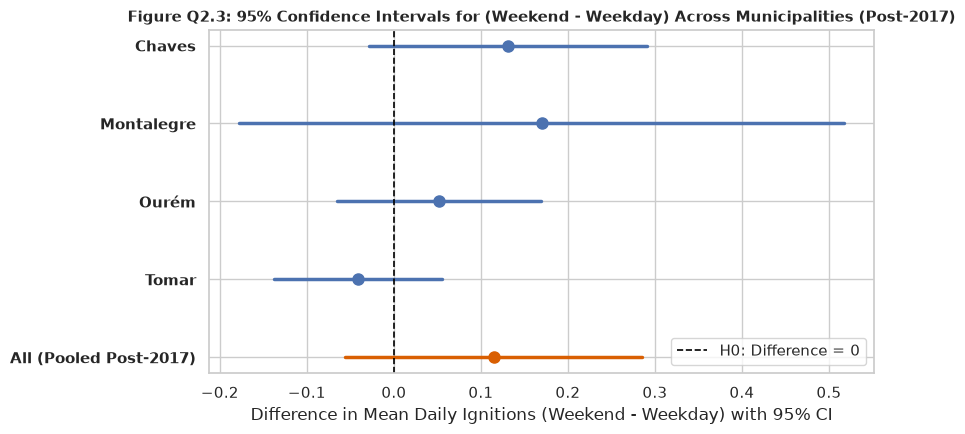

In [ ]:
# Robustness check: Welch's t-test por Concelho no período Post-2017
alpha_bonf_mun = 0.05 / 4  # Bonferroni correction for 4 municipalities (0.0125)
mun_rows = []
for mun in ["Chaves", "Montalegre", "Ourém", "Tomar"]:
    sub_m = post_data[post_data["Concelho"] == mun]
    wknd_m = sub_m[sub_m["Day_Type"] == "Weekend"]["Daily_Ignitions_Count"]
    wkdy_m = sub_m[sub_m["Day_Type"] == "Weekday"]["Daily_Ignitions_Count"]
    if len(wknd_m) >= 2 and len(wkdy_m) >= 2:
        t_m, p_m = stats.ttest_ind(wknd_m, wkdy_m, equal_var=False)
        v1_m, v2_m = wknd_m.var(ddof=1), wkdy_m.var(ddof=1)
        n1_m, n2_m = len(wknd_m), len(wkdy_m)
        se_m = np.sqrt(v1_m / n1_m + v2_m / n2_m)
        df_m = ((v1_m / n1_m + v2_m / n2_m) ** 2) / (((v1_m / n1_m) ** 2) / (n1_m - 1) + ((v2_m / n2_m) ** 2) / (n2_m - 1))
        diff_m = wknd_m.mean() - wkdy_m.mean()
        ci_l, ci_h = stats.t.interval(0.95, df=df_m, loc=diff_m, scale=se_m)
        mun_rows.append({
            "Municipality": mun,
            "n_Weekend": n1_m,
            "n_Weekday": n2_m,
            "Mean_Weekend": wknd_m.mean(),
            "Mean_Weekday": wkdy_m.mean(),
            "Diff (Wknd - Wkdy)": diff_m,
            "SE": se_m,
            "t_stat": t_m,
            "df": df_m,
            "p_value": p_m,
            "CI_95_low": ci_l,
            "CI_95_high": ci_h,
            "Alpha_Threshold": alpha_bonf_mun,
            "Significant": p_m < alpha_bonf_mun
        })

# Adicionar a linha Pooled (Global Post-2017) para comparação visual
mun_rows.append({
    "Municipality": "All (Pooled Post-2017)",
    "n_Weekend": n1,
    "n_Weekday": n2,
    "Mean_Weekend": weekend_post.mean(),
    "Mean_Weekday": weekday_post.mean(),
    "Diff (Wknd - Wkdy)": diff_mean,
    "SE": se_diff,
    "t_stat": t_stat,
    "df": df_welch,
    "p_value": p_val,
    "CI_95_low": ci_low,
    "CI_95_high": ci_high,
    "Alpha_Threshold": 0.05,
    "Significant": p_val < 0.05
})

mun_df = pd.DataFrame(mun_rows)
print(f"=== ROBUSTNESS CHECK: WELCH'S T-TEST BY MUNICIPALITY (Bonferroni alpha = 0.05/4 = {alpha_bonf_mun:.4f}) ===")
display(mun_df.round(4))

# Forest Plot dos Intervalos de Confiança a 95% para (mu_Weekend - mu_Weekday)
fig, ax = plt.subplots(figsize=(9, 4.5))
y_pos = np.arange(len(mun_df))
colors = ["#4c72b0"] * (len(mun_df) - 1) + ["#d95f02"]

for idx, row in mun_df.iterrows():
    ax.plot([row["CI_95_low"], row["CI_95_high"]], [idx, idx], color=colors[idx], linewidth=2.5)
    ax.plot(row["Diff (Wknd - Wkdy)"], idx, marker="o", markersize=8, color=colors[idx])

ax.axvline(0, color="black", linestyle="--", linewidth=1.2, label="H0: Difference = 0")
ax.set_yticks(y_pos)
ax.set_yticklabels(mun_df["Municipality"], fontweight="bold")
ax.invert_yaxis()
ax.set_xlabel("Difference in Mean Daily Ignitions (Weekend - Weekday) with 95% CI")
ax.set_title("Figure Q2.3: 95% Confidence Intervals for (Weekend - Weekday) Across Municipalities (Post-2017)", fontsize=11, fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [ ]:
# Complemento analítico: Comparar se a média nos fins de semana caiu de Pre-2017 para Post-2017
weekend_pre = q2[
    (q2["Period"] == "Pre-2017") & (q2["Day_Type"] == "Weekend")
]["Daily_Ignitions_Count"]

t_stat_evol, p_val_evol = stats.ttest_ind(
    weekend_pre, weekend_post, equal_var=False
)
print("=== WELCH'S T-TEST: WEEKENDS PRE-2017 VS POST-2017 ===")
print(
    f"Mean Weekend Pre-2017: {weekend_pre.mean():.3f} vs Post-2017: {weekend_post.mean():.3f}"
)
print(f"t-statistic: {t_stat_evol:.4f}, p-value: {p_val_evol:.4f}")

=== WELCH'S T-TEST: WEEKENDS PRE-2017 VS POST-2017 ===
Mean Weekend Pre-2017: 1.519 vs Post-2017: 1.570
t-statistic: -0.5662, p-value: 0.5715


## 5) Formulate Conclusions (Question 2)

### 5.1 Statistical Decision
- **Significance Level:** $\alpha = 0.05$.
- **Two-Sample Welch's t-test (Post-2017 Weekend vs. Weekday):**
  - Weekday: $\bar{x} = 1.455$ ($s = 1.161$, $\text{median} = 1.0$, $\text{IQR} = 0.0$, $n_{\text{Weekday}} = 802$)
  - Weekend: $\bar{x} = 1.570$ ($s = 1.402$, $\text{median} = 1.0$, $\text{IQR} = 1.0$, $n_{\text{Weekend}} = 337$)
  - Difference in sample means ($\bar{x}_{\text{Weekend}} - \bar{x}_{\text{Weekday}}$): $+0.115$ ignitions/day ($\text{SE} = 0.0867$).
  - Test Statistic & Critical Value: Welch's $t_{\text{obs}}(538.57) = 1.3223$, two-sided critical value $t_{\text{crit}} = \pm 1.9644$, $p\text{-value} = 0.1866$.
  - 95% Confidence Interval for $(\mu_{\text{Weekend}} - \mu_{\text{Weekday}})$: $[-0.056, \, 0.285]$.

Because $|t_{\text{obs}}| = 1.3223 < t_{\text{crit}} = 1.9644$ (falling outside the rejection region) and the $p\text{-value} = 0.1866 > \alpha = 0.05$, we **fail to reject the null hypothesis ($H_0$)** at the 5% significance level (the test is inconclusive). Consistently, the 95% confidence interval contains zero. Within the observed sample of active fire days, there is insufficient statistical evidence to claim that the population mean number of daily negligent ignitions differs between weekends and weekdays in the post-2017 period.

### 5.2 Contextual Discussion
1. **Weekend vs. Weekday Patterns:** While the sample mean is nominally higher on weekends by $0.115$ ignitions/day, this variation is fully compatible with random sampling variability under $H_0$. The median daily count remains stable at $1.0$ across both subsets, which **suggests** that the typical active fire day involves isolated single occurrences rather than systematic weekend clusters.
2. **Consistency Across Municipalities (Robustness Check):** When disaggregating the post-2017 analysis by municipality (`Chaves`, `Montalegre`, `Ourém`, and `Tomar`), all four 95% confidence intervals cross zero and every municipal $p\text{-value}$ exceeds both the nominal $\alpha = 0.05$ and the Bonferroni-adjusted threshold ($\alpha_{\text{Bonf}} = 0.0125$). This is **consistent with** the conclusion that the absence of a significant weekend effect holds across the individual municipalities rather than being an artifact of pooling.
3. **Temporal Consistency (Pre vs. Post on Weekends):** The complementary comparison of weekend ignitions between periods yielded $t(657.32) = -0.5662$ ($p = 0.5715$), failing to reveal a statistically detectable difference in mean daily intensity on active weekends between the pre-2017 and post-2017 timeframes.

---

### Model Overview: One-way ANOVA (Q3)

**What the ANOVA compares.** For strictly positive areas, the mean of ln(area) is the logarithm of the *geometric mean* of the area. Therefore, comparing means of ln(area) is equivalent to comparing geometric means (the "typical" fire) on the original scale, and differences become **ratios**. The ANOVA does **not** directly test equality of the *arithmetic* mean burnt area in hectares; the arithmetic means are reported only as descriptive statistics.

| Element | Definition |
|---|---|
| Unit of observation | One wildfire occurrence (one SGIF record) |
| Response variable | ln(`Total_Burnt_Area`): natural logarithm of the final burnt area in hectares |
| Factor | `Concelho` (municipality), 4 levels |
| Period | 2018–2025 (filtered with `Ano`; 2017 is excluded as a transition year) |
| Significance level | α = 0.05 |

**Hypotheses (on the log scale)**

- H₀: the population means of ln(burnt area) are equal in the four municipalities.
- H₁: at least one population mean of ln(burnt area) differs.

We describe the data before testing. Descriptive differences below are **not** evidence of significant differences. The original area (hectares) is used for the descriptive statistics; the **geometric mean** is the quantity that the ANOVA on ln(area) will compare, so it is shown next to the arithmetic mean and the median.

- **Arithmetic mean:** average area (very sensitive to huge fires). **Median:** the middle fire. **Geometric mean:** exp(mean of ln area), for fires with area > 0.  
- **Q1/Q3:** 25 % / 75 % of fires have an area below these values; **IQR** = Q3 − Q1.


#### Checking the assumptions

The classical one-way ANOVA model is yᵢⱼ = μᵢ + εᵢⱼ, where the errors εᵢⱼ are assumed to be **(1) independent**, **(2) normal** and **(3) of equal variance** in all groups. A **residual** is what is left after removing the group mean (eᵢⱼ = yᵢⱼ − ȳᵢ), so assumptions 2 and 3 are checked on residuals. In this section we check them on the **original scale (hectares)**; Section 05 repeats the checks on the log scale.

**Independence**

Independence means that knowing the burnt area of one fire tells us nothing about another. It is a property of how the data were generated and **cannot be proved by a statistical test**. We only look for *indications of possible clustering*; these are not proof of dependence (several fires on the same day in the same municipality may be unrelated events, and a fire near an earlier one may or may not be its continuation).

In [ ]:
d_ = q4.assign(Date_only=q4["DataHoraAlerta"].dt.date)
per_day = d_.groupby(["Concelho", "Date_only"], observed=True)["Codigo_SGIF"].transform("size")
print(f"(a) Fires on a day with >= 2 fires in the same municipality: {(per_day >= 2).sum()} ({100 * (per_day >= 2).mean():.1f} %)")
print(f"(b) Reignition records: {len(rk)} ({100 * len(rk) / len(q4):.1f} %); {linked} of them follow another fire in the same parish within 3 days (heuristic)")

ly = q4_ln["ln_area"]; ss_total = ((ly - ly.mean()) ** 2).sum()
eta_year = sum(len(x) * (x.mean() - ly.mean()) ** 2 for _, x in ly.groupby(q4_ln["Ano"])) / ss_total
eta_mun = sum(len(x) * (x.mean() - ly.mean()) ** 2 for _, x in ly.groupby(q4_ln["Concelho"], observed=True)) / ss_total
print(f"(c) Share of the variance of ln(area) associated with year: {eta_year:.3f}; with municipality: {eta_mun:.3f}")

(a) Fires on a day with >= 2 fires in the same municipality: 1513 (55.2 %)
(b) Reignition records: 130 (4.7 %); 90 of them follow another fire in the same parish within 3 days (heuristic)
(c) Share of the variance of ln(area) associated with year: 0.019; with municipality: 0.134


### 04.2 Normality of the residuals

A **Q-Q plot** shows each residual against the value it would have if the data were perfectly normal: points on the line mean normality, bent tails mean skewness or heavy tails. **Skewness** (0 = symmetric) and **excess kurtosis** (0 = normal tails) summarise the shape. The **Shapiro-Wilk test** (H₀: normal) is a complement only: in large samples it rejects even harmless departures, so the plots and the size of the departure matter more than the p-value.

                    n  skewness  excess kurtosis  Shapiro W  Shapiro p
Chaves            555     14.58            227.2    0.06717  1.624e-45
Montalegre       1146     28.66            894.1    0.06045  2.247e-59
Ourém             620     15.42              252     0.0601   1.42e-47
Tomar             418     14.38            221.3    0.06178  7.085e-41
Pooled residuals 2739     20.98              493    0.06671  7.273e-79


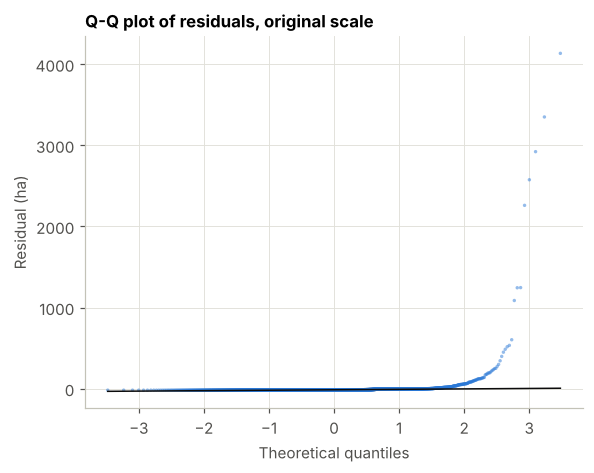

In [ ]:
resid_raw = np.concatenate([groups[m] - groups[m].mean() for m in MUNICIPALITIES])
fig, ax = plt.subplots(figsize=(5.5, 4.4))
qq_panel(ax, resid_raw, "#2a78d6", "Q-Q plot of residuals, original scale", ylabel="Residual (ha)")
plt.tight_layout(); plt.show()

rows = {}
for m in MUNICIPALITIES:
    a = groups[m]; sw = stats.shapiro(a)
    rows[m] = {"n": len(a), "skewness": stats.skew(a), "excess kurtosis": stats.kurtosis(a), "Shapiro W": sw.statistic, "Shapiro p": sw.pvalue}
sw_all = stats.shapiro(resid_raw)
rows["Pooled residuals"] = {"n": len(resid_raw), "skewness": stats.skew(resid_raw), "excess kurtosis": stats.kurtosis(resid_raw),
                            "Shapiro W": sw_all.statistic, "Shapiro p": sw_all.pvalue}
print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f"{v:.4g}"))

### 04.3 Homogeneity of variances

**Levene's test** (H₀: equal variances) compares how far observations are from their group centre; **Brown-Forsythe** is the version centred on the median, more robust to skewness. A non-significant result would not prove equal variances, and with thousands of observations a significant one can flag small differences, so the **ratio of variances** is also reported.

In [ ]:
var_tab = pd.DataFrame({"n": {m: len(groups[m]) for m in MUNICIPALITIES}, "variance": {m: groups[m].var(ddof=1) for m in MUNICIPALITIES},
                        "sd": {m: groups[m].std(ddof=1) for m in MUNICIPALITIES}})
print(var_tab.round(1).to_string())
print(f"Variance ratio (max/min): {var_tab['variance'].max() / var_tab['variance'].min():.1f}")
lev_mean = stats.levene(*groups.values(), center="mean"); lev_med = stats.levene(*groups.values(), center="median")
print(f"Levene (centre = mean)           : W = {lev_mean.statistic:.3f}, p = {lev_mean.pvalue:.4g}")
print(f"Brown-Forsythe (centre = median) : W = {lev_med.statistic:.3f}, p = {lev_med.pvalue:.4g}")

               n  variance     sd
Chaves       555   36814.4  191.9
Montalegre  1146   16911.9  130.0
Ourém        620   25371.7  159.3
Tomar        418    1259.2   35.5
Variance ratio (max/min): 29.2
Levene (centre = mean)           : W = 3.177, p = 0.02315
Brown-Forsythe (centre = median) : W = 0.906, p = 0.4372


### 04.4 Summary of the assumptions on the original scale

| Assumption | Evidence | Verdict |
|---|---|---|
| **Independence** | Cannot be verified from observational records. Indications of *possible* clustering: 55 % of fires occur on days with ≥ 2 fires in the same municipality; 90 of the 130 reignition records follow another fire in the same parish within 3 days; year is associated with 2 % of the variance of ln(area). None of this proves dependence. | Not verifiable; reported as a limitation |
| **Normality** | Q-Q plot bends sharply; skewness 21.0 and excess kurtosis 493 (pooled residuals); Shapiro-Wilk p < 10⁻⁴⁰ in every group | **Clearly violated** |
| **Equal variances** | Variance ratio 29.2 (SD ratio 5.4); Levene (mean) p = 0.023; Brown-Forsythe p = 0.437 | **Not supported** (the two tests disagree because they emphasise different parts of the distribution) |

On the original scale the classical ANOVA is therefore not appropriate. Section 05 examines whether a transformation solves the problem.

## 05 — Transformation and Method Selection

The problem is a very long right tail. A common remedy for positive, right-skewed data is the logarithm, which turns multiplicative differences into additive ones and compresses the huge fires. Because the ANOVA would then be computed on a **new scale**, its conclusions refer to ln(area), i.e. to geometric means and ratios (Section 01).

We compare three response scales using the diagnostics above: the original area, `log(1 + area)` and the natural logarithm `ln(area)` (the latter excludes the single 0 ha fire). Note that `log(1 + x)` is almost equal to `x` for areas below 1 ha, which are 78 % of the fires, so it is expected to remove the skewness only partly.

In [ ]:
def diagnostics(g, label):
    resid = np.concatenate([g[m] - g[m].mean() for m in MUNICIPALITIES]); var = np.array([g[m].var(ddof=1) for m in MUNICIPALITIES])
    return pd.Series({"n": sum(len(g[m]) for m in MUNICIPALITIES), "residual skewness": stats.skew(resid), "residual excess kurtosis": stats.kurtosis(resid),
                      "min Shapiro W (groups)": min(stats.shapiro(g[m]).statistic for m in MUNICIPALITIES),
                      "variance ratio (max/min)": var.max() / var.min(),
                      "Levene p (mean)": stats.levene(*g.values(), center="mean").pvalue,
                      "Brown-Forsythe p": stats.levene(*g.values(), center="median").pvalue}, name=label)

log1p_groups = {m: np.log1p(groups[m]) for m in MUNICIPALITIES}
diag = pd.DataFrame([diagnostics(groups, "original (ha)"), diagnostics(log1p_groups, "log(1 + area)"), diagnostics(ln_groups, "ln(area)")]).T
print(diag.to_string(float_format=lambda v: f"{v:.4g}"))

                          original (ha)  log(1 + area)  ln(area)
n                                  2739           2739      2738
residual skewness                 20.98          2.774    0.1287
residual excess kurtosis            493          9.991    0.2666
min Shapiro W (groups)           0.0601         0.3343     0.962
variance ratio (max/min)          29.24          4.443     1.316
Levene p (mean)                 0.02315      3.543e-73 0.0001075
Brown-Forsythe p                 0.4372       6.77e-44 0.0002396


### Figure 3 — Effect of the logarithmic transformation

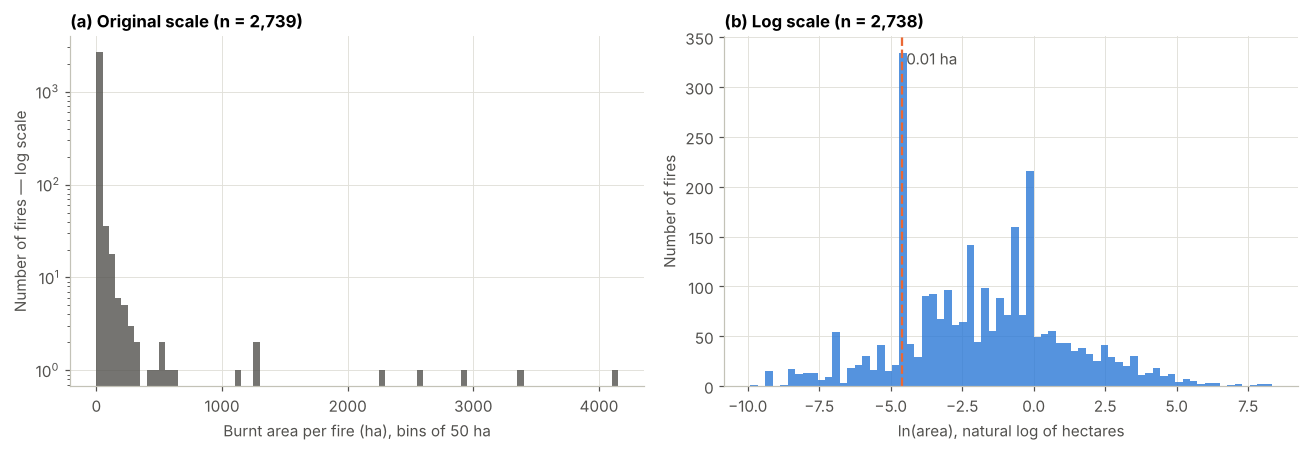

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].hist(q4[Y], bins=np.arange(0, q4[Y].max() + 50, 50), color="#52514e", alpha=.8)
axes[0].set_yscale("log"); axes[0].set_xlabel("Burnt area per fire (ha), bins of 50 ha"); axes[0].set_ylabel("Number of fires — log scale")
axes[0].set_title("(a) Original scale (n = 2,739)")
axes[1].hist(q4_ln["ln_area"], bins=70, color="#2a78d6", alpha=.8)
axes[1].axvline(np.log(0.01), color="#eb6834", linewidth=1.5, linestyle="--")
axes[1].text(np.log(0.01) + .15, axes[1].get_ylim()[1] * .92, "0.01 ha", color="#52514e")
axes[1].set_xlabel("ln(area), natural log of hectares"); axes[1].set_ylabel("Number of fires")
axes[1].set_title("(b) Log scale (n = 2,738)")
plt.tight_layout(); plt.show()

### Residual diagnostics on the log scale

We now inspect the residuals of ln(area) both pooled and **by municipality**, together with group sizes and spreads.

              n  sd of ln(area)  skewness  excess kurtosis  Shapiro W  Shapiro p
Chaves      555           2.712    0.3838           0.2596      0.962  8.617e-11
Montalegre 1146           2.813  -0.08395          -0.4723     0.9709  2.048e-14
Ourém       619           2.712    0.4091            1.438     0.9712  1.129e-09
Tomar       418           2.452   -0.0138           0.9545     0.9765  2.697e-06
Largest/smallest SD: 1.15 | largest/smallest variance: 1.32 | largest/smallest n: 2.74


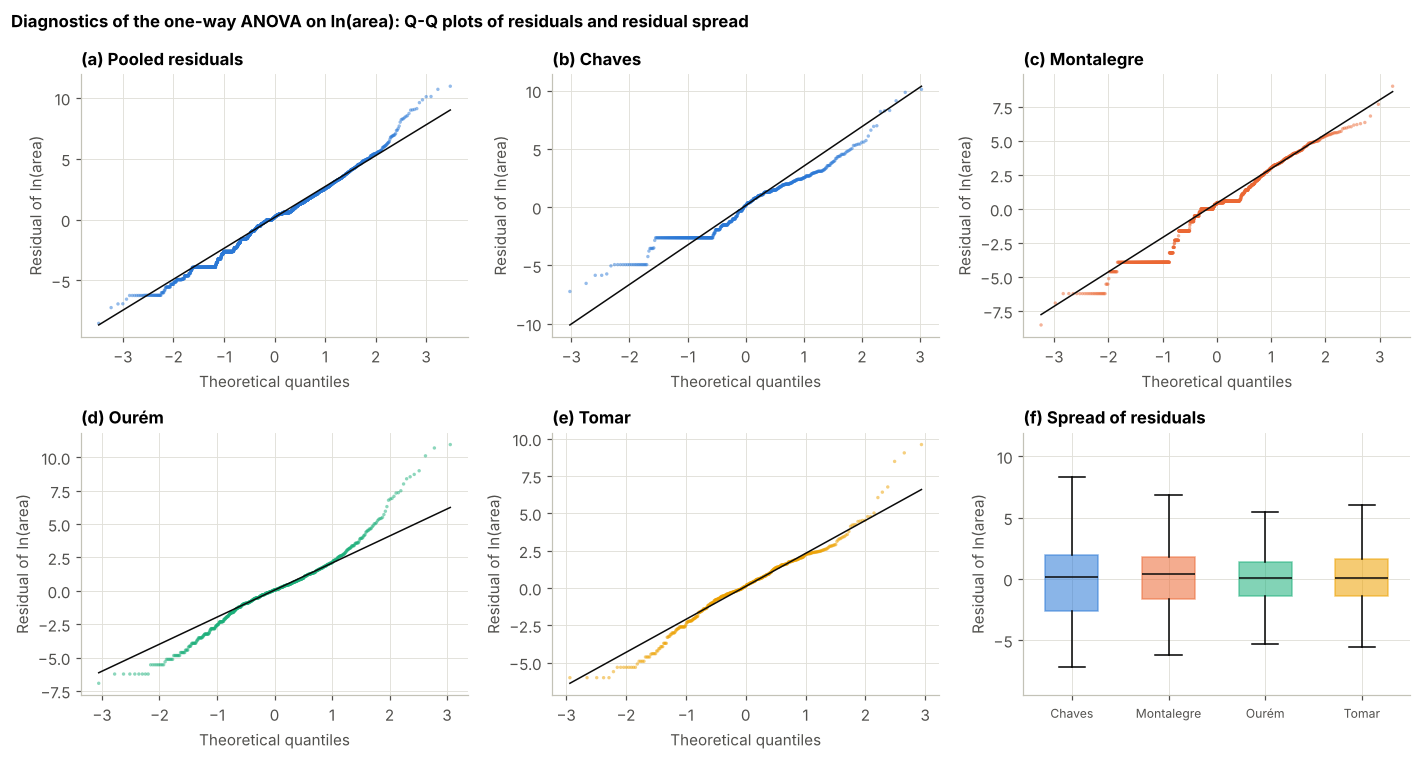

In [ ]:
rows = {}
for m in MUNICIPALITIES:
    x = ln_groups[m]; sw = stats.shapiro(x)
    rows[m] = {"n": len(x), "sd of ln(area)": x.std(ddof=1), "skewness": stats.skew(x), "excess kurtosis": stats.kurtosis(x),
               "Shapiro W": sw.statistic, "Shapiro p": sw.pvalue}
ln_tab = pd.DataFrame(rows).T
print(ln_tab.to_string(float_format=lambda v: f"{v:.4g}"))
sds = ln_tab["sd of ln(area)"]
print(f"Largest/smallest SD: {sds.max() / sds.min():.2f} | largest/smallest variance: {(sds.max() / sds.min()) ** 2:.2f} | largest/smallest n: {ln_tab['n'].max() / ln_tab['n'].min():.2f}")

resid_ln = {m: ln_groups[m] - ln_groups[m].mean() for m in MUNICIPALITIES}
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
qq_panel(axes[0, 0], np.concatenate(list(resid_ln.values())), "#2a78d6", "(a) Pooled residuals", ylabel="Residual of ln(area)")
for ax, m, tag in zip([axes[0, 1], axes[0, 2], axes[1, 0], axes[1, 1]], MUNICIPALITIES, "bcde"):
    qq_panel(ax, resid_ln[m], COLORS[m], f"({tag}) {m}", ylabel="Residual of ln(area)")
bp = axes[1, 2].boxplot([resid_ln[m] for m in MUNICIPALITIES], patch_artist=True, widths=.55, medianprops=dict(color="#0b0b0b"),
                        flierprops=dict(marker="o", markersize=2, alpha=.4, markeredgewidth=0))
for patch, m in zip(bp["boxes"], MUNICIPALITIES):
    patch.set(facecolor=COLORS[m], alpha=.55, edgecolor=COLORS[m])
axes[1, 2].set_xticks(range(1, 5)); axes[1, 2].set_xticklabels(MUNICIPALITIES, fontsize=8)
axes[1, 2].set_title("(f) Spread of residuals"); axes[1, 2].set_ylabel("Residual of ln(area)")
fig.suptitle("Diagnostics of the one-way ANOVA on ln(area): Q-Q plots of residuals and residual spread", x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

### Assessment and choice of method

| Response scale | Residual skewness | Excess kurtosis | Variance ratio | Assessment |
|---|---:|---:|---:|---|
| Original (ha) | 21.0 | 493 | 29.2 | Assumptions clearly not met |
| log(1 + area) | 2.8 | 10.0 | 4.4 | Improves, but still strongly skewed |
| **ln(area)** | **0.13** | **0.27** | **1.32** | Approximately symmetric, similar spreads |

- **Normality on the log scale.** In the centre, the Q-Q plots of the pooled residuals and of each municipality follow the reference line closely (group skewness between −0.08 and 0.41). The lower tail shows stair-steps caused by repeated recorded areas (probably rounding), and Ourém has a somewhat heavier upper tail (excess kurtosis 1.4). Shapiro-Wilk still rejects (W ≈ 0.96–0.98), as expected with 400–1,100 observations per group; the departures are moderate and much smaller than on the original scale (skewness 21, kurtosis 493).
- **Equal variances on the log scale.** The variance ratio is 1.32 (SD ratio 1.15). Levene and Brown-Forsythe remain significant (p ≈ 0.0001–0.0002), but with 2,738 observations such a small difference is detectable; it is not practically important. Because the groups with larger sizes (Montalegre, n = 1,146) also have the largest SD, the classical F-test tends to be, if anything, slightly conservative. Welch's ANOVA on the same response is nevertheless run as a sensitivity check in Section 08.
- **Remaining limits.** The concentration of recorded areas at 0.01 ha (possibly rounding or reporting conventions) creates a visible spike in Figure 3b, and independence cannot be verified (Section 04.1).
- **`log(1 + area)`** is not used because it does not remove the skewness.

**Decision.** The **primary analysis is the classical one-way ANOVA on ln(burnt area)**, with **Tukey HSD** for the pairwise comparisons. It answers the research question as formulated (differences in mean ln(area), i.e. in geometric means) and its assumptions are reasonably met. This choice was fixed from the diagnostics, before looking at any ANOVA p-value. Robustness is checked in Section 08 with Welch's ANOVA and Games-Howell on the same response, a rank-based Kruskal-Wallis test, and three alternative samples. The ANOVA does not make inferences about arithmetic means in hectares.

## 06 — One-way ANOVA (primary analysis)

**Idea.** Compare how far the municipality means are from each other (**between-group variation, SSB**) with how much the fires vary inside each municipality (**within-group variation, SSW**). Dividing each sum of squares by its degrees of freedom gives mean squares, and **F = MSB / MSW**. If H₀ were true, F would be close to 1; a large F means that the group means are further apart than the within-group noise explains. The **p-value** is the probability of an F at least this large if H₀ were true (and the assumptions held). A significant result says that *at least one* mean differs, not which one.

**Why not several t-tests?** With 4 groups there are 6 pairs; each test at α = 0.05 carries a 5 % false-positive risk, which accumulates to about 26 % across 6 tests. The ANOVA tests everything at once, and Tukey HSD controls the error rate across the pairs.

H₀: μ_Chaves = μ_Montalegre = μ_Ourém = μ_Tomar (means of ln area) · H₁: at least one differs · α = 0.05

In [ ]:
# ANOVA table computed by hand (every number is traceable), then cross-checked with scipy
N_ln = len(q4_ln); n_groups = len(ln_groups)
grand = q4_ln["ln_area"].mean()
ssb = sum(len(v) * (v.mean() - grand) ** 2 for v in ln_groups.values())
ssw = sum(((v - v.mean()) ** 2).sum() for v in ln_groups.values()); sst = ssb + ssw
df_b, df_w = n_groups - 1, N_ln - n_groups
msb, msw = ssb / df_b, ssw / df_w
F = msb / msw; p_anova = stats.f.sf(F, df_b, df_w)

F_scipy, p_scipy = stats.f_oneway(*ln_groups.values())
assert np.isclose(F, F_scipy) and np.isclose(p_anova, p_scipy), "manual ANOVA differs from scipy"

anova_tab = pd.DataFrame({"SS": [ssb, ssw, sst], "df": [df_b, df_w, N_ln - 1], "MS": [msb, msw, np.nan], "F": [F, np.nan, np.nan],
                          "p-value": [p_anova, np.nan, np.nan]}, index=["Between municipalities", "Within (residual)", "Total"])
print(anova_tab.to_string(float_format=lambda v: f"{v:.5g}"))
eta2 = ssb / sst; omega2 = (ssb - df_b * msw) / (sst + msw)
print(f"F({df_b}, {df_w}) = {F:.2f}, p = {p_anova:.3g}")
print(f"Effect size on the ln scale: eta^2 = {eta2:.3f}, omega^2 = {omega2:.3f} (benchmarks: 0.01 small, 0.06 medium, 0.14 large)")

                           SS    df     MS      F    p-value
Between municipalities 3110.6     3 1036.9 140.43 1.2661e-84
Within (residual)       20187  2734 7.3836    NaN        NaN
Total                   23297  2737    NaN    NaN        NaN
F(3, 2734) = 140.43, p = 1.27e-84
Effect size on the ln scale: eta^2 = 0.134, omega^2 = 0.133 (benchmarks: 0.01 small, 0.06 medium, 0.14 large)


In [ ]:
# Group estimates on the log scale and back-transformed to hectares (geometric means), with 95 % t-intervals
rows = []
for m in MUNICIPALITIES:
    v = ln_groups[m]; n = len(v); mean = v.mean(); se = v.std(ddof=1) / np.sqrt(n); t = stats.t.ppf(.975, n - 1)
    rows.append({"municipality": m, "n": n, "mean ln(area)": mean, "sd ln(area)": v.std(ddof=1), "geometric mean (ha)": np.exp(mean),
                 "95% CI low (ha)": np.exp(mean - t * se), "95% CI high (ha)": np.exp(mean + t * se)})
gm = pd.DataFrame(rows).set_index("municipality")
print(gm.round(3).to_string())

# Optional cross-check with statsmodels (runs only if the library is installed)
try:
    import statsmodels.api as sm
    from statsmodels.formula.api import ols
    fit = ols("ln_area ~ C(Concelho)", data=q4_ln.assign(Concelho=q4_ln["Concelho"].astype(str))).fit()
    tab = sm.stats.anova_lm(fit, typ=1)
    print("statsmodels F =", round(float(tab["F"].iloc[0]), 2), "| matches manual F:", bool(np.isclose(tab["F"].iloc[0], F)))
except Exception as err:
    print("statsmodels cross-check skipped:", type(err).__name__)

                 n  mean ln(area)  sd ln(area)  geometric mean (ha)  95% CI low (ha)  95% CI high (ha)
municipality                                                                                          
Chaves         555         -1.977        2.712                0.139            0.110             0.174
Montalegre    1146         -0.683        2.813                0.505            0.429             0.594
Ourém          619         -2.973        2.712                0.051            0.041             0.063
Tomar          418         -3.200        2.452                0.041            0.032             0.052
statsmodels cross-check skipped: ModuleNotFoundError


### Interpretation of the ANOVA

- **Decision.** F(3, 2734) = 140.4, p < 0.001. At α = 0.05 we **reject H₀**: there is strong evidence that the mean of ln(burnt area) is not the same in the four municipalities, i.e. that the geometric mean (typical) burnt area per fire differs between at least two of them.
- **Effect size.** η² = 0.134 (ω² = 0.133): about 13 % of the variation **of ln(burnt area)** in this model is associated with the municipality, a medium-to-large effect by conventional benchmarks. This is *not* the share of the variation of the area in hectares, and it is not a causal statement. Most of the variation (87 %) is between fires of the same municipality.
- **Geometric means** (exp of the mean of ln area, not arithmetic means and not medians): Montalegre ≈ 0.50 ha, Chaves ≈ 0.14 ha, Ourém ≈ 0.05 ha, Tomar ≈ 0.04 ha. They are close to, but not equal to, the sample medians.
- The ANOVA does not say which municipalities differ; that is the role of Section 07. The p-value assumes independent fires, which cannot be verified, so it should be read as strong but approximate evidence.

## 07 — Post-hoc Comparisons (Tukey HSD)

The ANOVA only says *whether* some mean differs. To see *which* municipalities differ we compare all 6 pairs with **Tukey HSD**, which adjusts the p-values so that the probability of **any** false positive stays at 5 % (the *family-wise error rate*). With unequal group sizes it is the Tukey-Kramer version (what `scipy.stats.tukey_hsd` computes). It is appropriate here because the primary ANOVA is the classical one on ln(area), with nearly equal variances.

The differences are in ln(area). Exponentiated, each difference is a **ratio of geometric means**: a ratio of 3 means that the typical fire in the first municipality is 3 times that of the second; a ratio of 1 means no difference. Pairs are ordered so that the municipality with the larger geometric mean comes first.

In [ ]:
tk = stats.tukey_hsd(*[ln_groups[m] for m in MUNICIPALITIES])
ci_tk = tk.confidence_interval(confidence_level=0.95)
order = sorted(range(4), key=lambda i: -ln_groups[MUNICIPALITIES[i]].mean())     # larger geometric mean first
means_ln = {m: ln_groups[m].mean() for m in MUNICIPALITIES}

rows = []
for x in range(4):
    for y in range(x + 1, 4):
        i, j = order[x], order[y]                                              # i has the larger mean
        a, b = MUNICIPALITIES[i], MUNICIPALITIES[j]; d_ln = means_ln[a] - means_ln[b]
        assert np.isclose(d_ln, tk.statistic[i, j]) and np.isclose(ci_tk.low[j, i], -ci_tk.high[i, j])
        rows.append({"comparison (first / second)": f"{a} / {b}", "difference in ln(area)": d_ln, "ratio of geometric means": np.exp(d_ln),
                     "95% CI ratio low": np.exp(ci_tk.low[i, j]), "95% CI ratio high": np.exp(ci_tk.high[i, j]),
                     "Tukey adj. p": tk.pvalue[i, j], "significant (0.05)": bool(tk.pvalue[i, j] < 0.05)})
posthoc = pd.DataFrame(rows).set_index("comparison (first / second)")
shown = posthoc.copy(); shown["Tukey adj. p"] = posthoc["Tukey adj. p"].map(lambda v: "< 0.0001" if v < 1e-4 else f"{v:.4f}")
print(shown.to_string(float_format=lambda v: f"{v:.4g}"))
primary_sig = {frozenset(c.split(" / ")) for c, r in posthoc.iterrows() if r["significant (0.05)"]}
print("Significant pairs:", len(primary_sig), "of 6")

                             difference in ln(area)  ratio of geometric means  95% CI ratio low  95% CI ratio high Tukey adj. p  significant (0.05)
comparison (first / second)                                                                                                                        
Montalegre / Chaves                           1.293                     3.645              2.54              5.232     < 0.0001                True
Montalegre / Ourém                            2.289                     9.868             6.965              13.98     < 0.0001                True
Montalegre / Tomar                            2.517                     12.39              8.31              18.46     < 0.0001                True
Chaves / Ourém                               0.9958                     2.707             1.799              4.072     < 0.0001                True
Chaves / Tomar                                1.223                     3.398             2.161              5.3

### Figure 4 — Pairwise ratios of geometric means

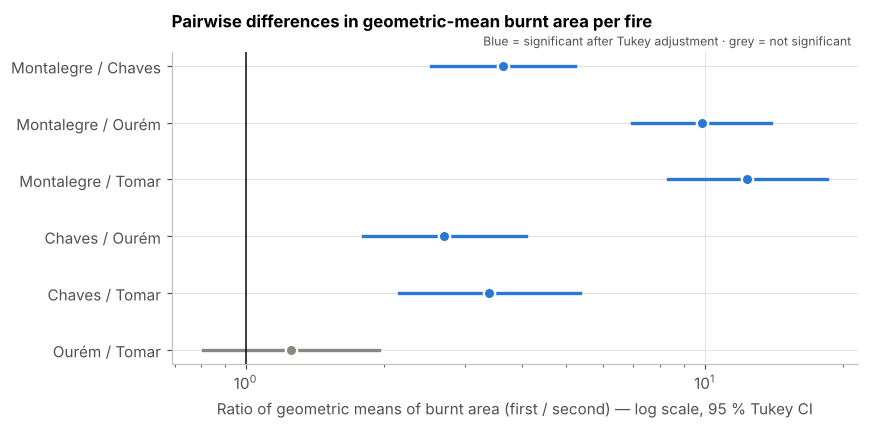

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
ypos = np.arange(len(posthoc))[::-1]
for y_, (name, r) in zip(ypos, posthoc.iterrows()):
    col = "#2a78d6" if r["significant (0.05)"] else "#898781"
    ax.plot([r["95% CI ratio low"], r["95% CI ratio high"]], [y_, y_], color=col, linewidth=2.2)
    ax.scatter(r["ratio of geometric means"], y_, s=55, color=col, zorder=3, edgecolor="#fcfcfb", linewidth=1.5)
ax.axvline(1, color="#0b0b0b", linewidth=1)
ax.set_xscale("log"); ax.set_yticks(ypos); ax.set_yticklabels(posthoc.index)
ax.set_xlabel("Ratio of geometric means of burnt area (first / second) — log scale, 95 % Tukey CI")
ax.set_title("Pairwise differences in geometric-mean burnt area per fire", pad=16)
ax.text(0.99, 1.02, "Blue = significant after Tukey adjustment · grey = not significant", transform=ax.transAxes, ha="right", fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()

### Interpretation of the post-hoc comparisons

At a family-wise level of 5 %:

- **Montalegre** has a larger geometric-mean burnt area than each of the other three municipalities: about 3.6 times Chaves, 9.9 times Ourém and 12.4 times Tomar (adjusted p < 0.0001).
- **Chaves** is larger than Ourém (≈ 2.7 times) and Tomar (≈ 3.4 times) (adjusted p < 0.0001).
- **Ourém and Tomar do not differ significantly** (ratio 1.26, 95 % CI 0.81–1.95, adjusted p = 0.55). Failing to detect a difference is not evidence that they are equal; the interval is compatible with ratios from about 0.8 to 2.
- All 6 pairs were compared, and the confidence intervals are on the ratio scale (log differences exponentiated), not in hectares.
- **Statistical vs. practical importance.** The geometric means are all below 1 ha, so a ratio of 10 (e.g., 0.50 ha vs 0.05 ha) is statistically strong but small in absolute hectares; the total burnt area is determined by rare extreme fires, which the logarithm deliberately down-weights.

## 08 — Selected Robustness Checks

To see whether the conclusion depends on the choices made along the way, we repeated the analysis changing one of them at a time. We only kept the checks that are relevant to Q4, and all of them use the same response variable, ln(area):

1. **Welch's ANOVA and Games-Howell comparisons.** These do not require equal variances, so they show whether the result depends on that assumption.
2. **Kruskal-Wallis test.** It is based on ranks and is therefore unaffected by monotone transformations such as the logarithm, so it shows whether the result depends on normality. It compares distributions, not means.
3. **Excluding 2025,** which is an incomplete year.
4. **Human-related fires only** (intentional and negligent), which connects Q4 to the theme of the project.
5. **Excluding the 28 largest fires** (1 % of the sample), as an exploratory check on whether a few extreme fires drive the result.

Permutation tests were not used. Permuting the municipality labels tests the stronger hypothesis that the whole distributions are identical, which is hard to justify when the groups have different variances and shapes. Welch's ANOVA is implemented below and was validated against the Welch t-test, since for two groups F equals t².

In [ ]:
def welch_anova(samples):
    # Welch (1951) one-way ANOVA for unequal variances; returns F, df1, df2, p
    n = np.array([len(x) for x in samples]); m = np.array([x.mean() for x in samples]); v = np.array([x.var(ddof=1) for x in samples])
    kk = len(samples); w = n / v; W = w.sum(); mw = (w * m).sum() / W
    A = (w * (m - mw) ** 2).sum() / (kk - 1); lam = ((1 - w / W) ** 2 / (n - 1)).sum()
    B = 1 + 2 * (kk - 2) / (kk ** 2 - 1) * lam
    Fw = A / B; df2 = (kk ** 2 - 1) / (3 * lam)
    return Fw, kk - 1, df2, stats.f.sf(Fw, kk - 1, df2)

def games_howell(samples):
    # Games-Howell adjusted p-values for all pairs (unequal variances); returns a symmetric matrix
    kk = len(samples); P = np.ones((kk, kk))
    for i in range(kk):
        for j in range(i + 1, kk):
            a, b = samples[i], samples[j]; va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
            df_ = (va + vb) ** 2 / (va ** 2 / (len(a) - 1) + vb ** 2 / (len(b) - 1))
            q_ = abs(a.mean() - b.mean()) / np.sqrt((va + vb) / 2)
            P[i, j] = P[j, i] = stats.studentized_range.sf(q_, kk, df_)
    return P

# Validation: with two groups, Welch's F equals the square of the Welch t statistic
t_chk = stats.ttest_ind(ln_groups["Chaves"], ln_groups["Montalegre"], equal_var=False)
F_chk, _, df_chk, _ = welch_anova([ln_groups["Chaves"], ln_groups["Montalegre"]])
assert np.isclose(F_chk, t_chk.statistic ** 2) and np.isclose(df_chk, t_chk.df), "Welch implementation check failed"

def ln_samples(df):
    dd = df[df[Y] > 0]
    return [np.log(dd.loc[dd["Concelho"] == m, Y].to_numpy()) for m in MUNICIPALITIES]

def sig_set(P):
    return {frozenset((MUNICIPALITIES[i], MUNICIPALITIES[j])) for i in range(4) for j in range(i + 1, 4) if P[i, j] < 0.05}

def pattern(sig):
    return "same pairs as primary" if sig == primary_sig else "DIFFERS: " + str(sorted(tuple(sorted(s)) for s in sig ^ primary_sig))

def classical(samples):
    F_, p_ = stats.f_oneway(*samples); allv = np.concatenate(samples); gm_ = allv.mean()
    return F_, p_, sum(len(x) * (x.mean() - gm_) ** 2 for x in samples) / ((allv - gm_) ** 2).sum()

rows = []
S_all = ln_samples(q4)
F1, p1, e1 = classical(S_all); assert np.isclose(F1, F)
rows.append({"analysis": "Primary: classical ANOVA + Tukey, all fires", "n": sum(map(len, S_all)), "statistic": f"F = {F1:.1f}", "p-value": p1, "eta^2": e1,
             "pairwise pattern": pattern(sig_set(tk.pvalue))})
Fw, d1, d2, pw = welch_anova(S_all)
rows.append({"analysis": "Welch ANOVA + Games-Howell, all fires", "n": sum(map(len, S_all)), "statistic": f"F = {Fw:.1f}", "p-value": pw, "eta^2": np.nan,
             "pairwise pattern": pattern(sig_set(games_howell(S_all)))})
H, pH = stats.kruskal(*[groups[m] for m in MUNICIPALITIES])
rows.append({"analysis": "Kruskal-Wallis (ranks), all fires", "n": len(q4), "statistic": f"H = {H:.1f}", "p-value": pH, "eta^2": np.nan, "pairwise pattern": "not applicable"})
top28 = q4.nlargest(28, Y).index
for label, df_ in [("Classical ANOVA + Tukey, excluding 2025", sample_no_2025), ("Classical ANOVA + Tukey, human-related fires only", sample_human),
                   ("Classical ANOVA + Tukey, excluding the 28 largest fires", q4.drop(top28))]:
    S = ln_samples(df_); F_, p_, e_ = classical(S)
    rows.append({"analysis": label, "n": sum(map(len, S)), "statistic": f"F = {F_:.1f}", "p-value": p_, "eta^2": e_,
                 "pairwise pattern": pattern(sig_set(stats.tukey_hsd(*S).pvalue))})

robust = pd.DataFrame(rows).set_index("analysis")
robust["p-value"] = robust["p-value"].map(lambda v: "< 0.0001" if v < 1e-4 else f"{v:.4f}")
print(robust.to_string(float_format=lambda v: f"{v:.3f}"))
print()
print(f"Welch on ln(area): F({d1}, {d2:.0f}) = {Fw:.2f}")

                                                            n  statistic   p-value  eta^2       pairwise pattern
analysis                                                                                                        
Primary: classical ANOVA + Tukey, all fires              2738  F = 140.4  < 0.0001  0.134  same pairs as primary
Welch ANOVA + Games-Howell, all fires                    2738  F = 142.8  < 0.0001    NaN  same pairs as primary
Kruskal-Wallis (ranks), all fires                        2739  H = 376.0  < 0.0001    NaN         not applicable
Classical ANOVA + Tukey, excluding 2025                  2418  F = 110.5  < 0.0001  0.121  same pairs as primary
Classical ANOVA + Tukey, human-related fires only        2484  F = 135.0  < 0.0001  0.140  same pairs as primary
Classical ANOVA + Tukey, excluding the 28 largest fires  2710  F = 154.7  < 0.0001  0.146  same pairs as primary

Welch on ln(area): F(3, 1238) = 142.82


### Interpretation of the robustness checks

- **Equal variances.** Welch's ANOVA on ln(area) leads to the same conclusion as the classical ANOVA (F(3, 1238) = 142.8, p < 0.0001), and the Games-Howell comparisons identify the same pairs as Tukey HSD. The main result therefore does not depend on the assumption of equal variances.
- **Normality.** The Kruskal-Wallis test, which is based on ranks and is not affected by the logarithmic transformation, also rejects the equality of the distributions (H = 376.0, p < 0.0001). It does not compare means, but it indicates that the conclusion does not rest on the normality assumption.
- **Incomplete 2025, human-related fires only and the 28 largest fires.** In all three cases the ANOVA remains highly significant (F between 110 and 155, p < 0.0001), the same five pairs differ, and Ourém and Tomar still cannot be distinguished. The value of η² stays between 0.12 and 0.15. The result is thus not driven by 2025, by non-human causes or by a few extreme fires; on the log scale, the largest fires have limited leverage.
- These checks concern the sensitivity of the **log-scale** conclusion only. None of them is an inference about arithmetic mean burnt areas in hectares which, as shown in Section 03, are dominated by a small number of very large fires.

In [ ]:
# Numbers quoted in the conclusion, taken from the objects computed above (traceability check)
print(f"n = {len(q4)} fires; ANOVA sample n = {len(q4_ln)}")
print(f"ANOVA on ln(area): F({df_b}, {df_w}) = {F:.1f}, p = {p_anova:.2g}, eta^2 = {eta2:.3f}")
print("Geometric means (ha):", gm["geometric mean (ha)"].round(2).to_dict())
print(posthoc[["ratio of geometric means", "95% CI ratio low", "95% CI ratio high"]].round(2).to_string())
print("Ourem/Tomar adjusted p =", round(float(posthoc.loc["Ourém / Tomar", "Tukey adj. p"]), 2))
print(f"Welch on ln(area): F({d1}, {d2:.0f}) = {Fw:.1f}; Kruskal-Wallis H = {H:.1f}")

n = 2739 fires; ANOVA sample n = 2738
ANOVA on ln(area): F(3, 2734) = 140.4, p = 1.3e-84, eta^2 = 0.134
Geometric means (ha): {'Chaves': 0.14, 'Montalegre': 0.5, 'Ourém': 0.05, 'Tomar': 0.04}
                             ratio of geometric means  95% CI ratio low  95% CI ratio high
comparison (first / second)                                                               
Montalegre / Chaves                              3.65              2.54               5.23
Montalegre / Ourém                               9.87              6.96              13.98
Montalegre / Tomar                              12.39              8.31              18.46
Chaves / Ourém                                   2.71              1.80               4.07
Chaves / Tomar                                   3.40              2.16               5.34
Ourém / Tomar                                    1.26              0.81               1.95
Ourem/Tomar adjusted p = 0.55
Welch on ln(area): F(3, 1238) = 142.8; Kruskal-Wal

## 09 — Discussion and Conclusion


### Research question
Does the mean log-transformed burnt area per fire differ significantly across Chaves, Montalegre, Ourém and Tomar during 2018–2025?

### Methods
We analysed all valid wildfire records from the ICNF/SGIF database for 2018–2025 in the four municipalities (n = 2,739; Chaves 555, Montalegre 1,146, Ourém 620, Tomar 418), regardless of cause, without removing extreme observations (the largest fires are internally consistent records of real events). Descriptive statistics use the original burnt area in hectares. The response variable of the ANOVA was the natural logarithm of the final burnt area, ln(`Total_Burnt_Area`); the single fire with 0 ha, for which the logarithm is undefined, was left out of this analysis (n = 2,738). The factor was the municipality, and α = 0.05. The null hypothesis was that the population means of ln(burnt area) are equal in the four municipalities, and the alternative that at least one differs. For strictly positive areas, the mean of ln(area) corresponds to the logarithm of the geometric mean, so the analysis compares geometric means (the typical fire) and expresses differences as ratios; it does not test the equality of arithmetic mean burnt areas in hectares.

The logarithm was used because the burnt area is extremely right-skewed: 78 % of the fires burnt less than 1 ha, while the largest 1 % (28 fires) account for 71 % of the total burnt area. On the original scale the assumptions of the classical one-way ANOVA were clearly violated (residual skewness 21.0, excess kurtosis 493, ratio of the largest to the smallest variance 29.2). On the log scale the residuals were approximately symmetric (skewness 0.13, excess kurtosis 0.27) and the variances similar (ratio 1.32; standard deviations differing by 15 %), although the Shapiro-Wilk, Levene and Brown-Forsythe tests still rejected their null hypotheses, which is expected with more than 2,700 observations and corresponds to small departures. Independence of the records cannot be verified from observational data. We therefore used a classical one-way ANOVA on ln(area) as the primary analysis, followed by Tukey HSD for pairwise comparisons, and checked robustness with Welch's ANOVA and Games-Howell comparisons, the Kruskal-Wallis test, and repetitions excluding 2025 (incomplete year), keeping only human-related fires (intentional or negligent), and excluding the 28 largest fires.

### Results
Descriptively (original scale), the arithmetic mean burnt area per fire was 18.1 ha in Chaves, 13.9 ha in Ourém, 13.7 ha in Montalegre and 3.2 ha in Tomar, whereas the medians were 0.77, 0.16, 0.054 and 0.045 ha in Montalegre, Chaves, Ourém and Tomar, respectively. The arithmetic means are dominated by a few very large fires: the five largest fires of each municipality account for 83 % (Chaves), 84 % (Ourém), 91 % (Tomar) and 40 % (Montalegre) of its burnt area.

The ANOVA rejected the null hypothesis, F(3, 2734) = 140.4, p < 0.001, η² = 0.13: about 13 % of the variation of ln(burnt area) is associated with the municipality. The geometric mean burnt area was 0.50 ha in Montalegre, 0.14 ha in Chaves, 0.05 ha in Ourém and 0.04 ha in Tomar. According to Tukey HSD, the geometric mean in Montalegre was larger than in Chaves (ratio 3.6, 95 % CI 2.5–5.2), Ourém (9.9, 7.0–14.0) and Tomar (12.4, 8.3–18.5), and that of Chaves was larger than in Ourém (2.7, 1.8–4.1) and Tomar (3.4, 2.2–5.3), all with adjusted p < 0.0001. Ourém and Tomar did not differ significantly (ratio 1.26, 95 % CI 0.81–1.95, adjusted p = 0.55). The same conclusions were obtained with Welch's ANOVA (F(3, 1238) = 142.8, p < 0.0001) and Games-Howell comparisons, with the Kruskal-Wallis test (H = 376.0, p < 0.0001), and when excluding 2025, restricting to human-related fires or excluding the 28 largest fires (F between 110 and 155, p < 0.0001, the same five pairs differing in all cases).

### Conclusion
We reject the null hypothesis: the mean of the log-transformed burnt area per fire, differed significantly across the four municipalities in 2018–2025. It was largest in Montalegre, followed by Chaves, while Ourém and Tomar had the smallest values and could not be distinguished from each other. This result is stable across the robustness checks. It concerns the typical fire and should not be read as a comparison of arithmetic mean burnt areas in hectares: on that scale the descriptive ranking is different (Chaves has the highest mean) because a handful of very large fires dominate the means, and no inference about arithmetic means was made. Differences in the typical fire are also small in absolute terms (geometric means below 1 ha), whereas the total burnt area is determined by rare extreme fires.

### Limitations
This is an observational study, so the differences cannot be attributed to wildfire policies, the events of 2017 or any other cause; the municipalities differ in vegetation, terrain, weather and land use, and the comparison is unadjusted. The independence of the records cannot be verified: there are indications of possible clustering (55 % of the fires occurred on days with at least two fires in the same municipality, and most of the 130 reignition records followed another fire in the same parish within three days), but these do not prove dependence, so the p-values should be interpreted as approximate. Some deviations from normality and equal variances remain on the log scale, although they are small. One fire with 0 ha was excluded from the ANOVA, a noticeable share of the recorded areas is exactly 0.01 ha (possibly reflecting rounding or reporting conventions), 2025 is incomplete, and the post-2017 period mixes years before and after the 2021 law. Finally, Q4 alone does not answer the main research question of the project on response times and burnt areas before and after 2017.

---

### Model Overview: Two-way ANOVA (Q4)

A two-way ANOVA was chosen because the response variable (`Log_Total_Burnt_Area`) is quantitative and there are two qualitative factors with two levels each, `Cause_Type` (Intentional, Negligent) and `Period` (Pre-2017, Post-2017). This design gives four groups and allows us to test the effect of the cause, the effect of the period and the interaction between them. The research question is answered by the interaction term.

##### Hypothesis
(significance level α = 0.05)

| Effect | H₀ | H₁ |
|---|---|---|
| Cause_Type | The mean log burnt area is the same for intentional and negligent fires | The means differ |
| Period | The mean log burnt area is the same before and after 2017 | The means differ |
| Interaction | The difference between causes is the same in both periods | The difference between causes changes from one period to the other |

#### Checking the assumptions

ANOVA requires three conditions. The observations must be independent, the data within each group must be approximately normal, and the variability must be similar across groups.

Independence is reasonable because each row corresponds to a different fire. The other two conditions are checked below for each of the four Cause_Type x Period groups, using histograms and normal probability plots (Q-Q plots) for normality and comparing the standard deviations of the groups for constant variance.

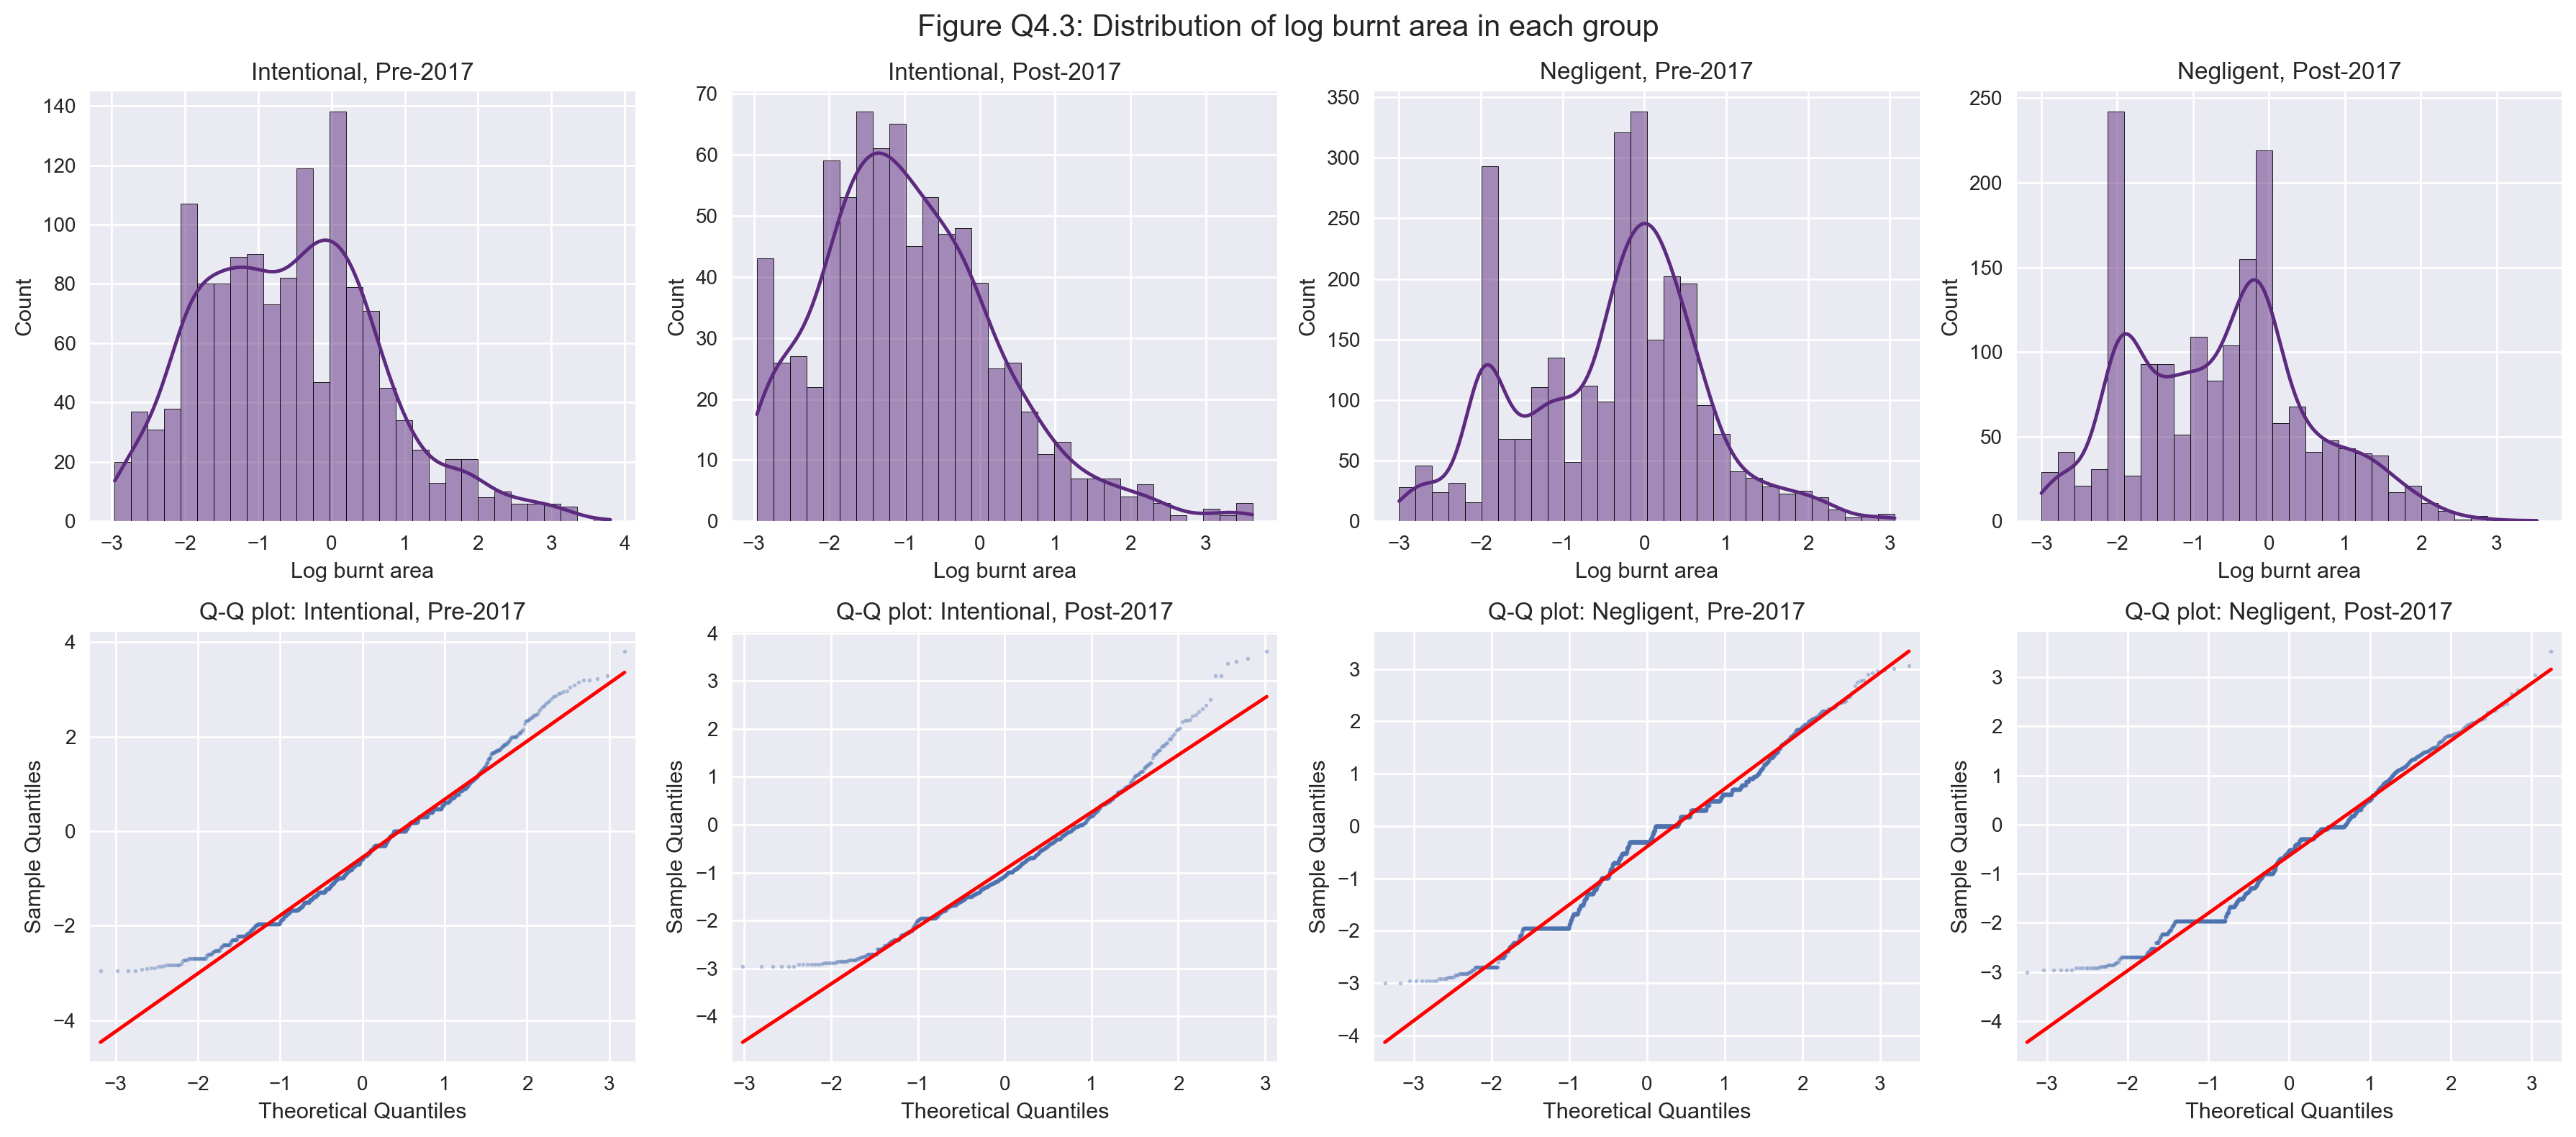

    Cause_Type     Period  Log_Total_Burnt_Area
0  Intentional   Pre-2017                 1.228
1  Intentional  Post-2017                 1.195
2    Negligent   Pre-2017                 1.109
3    Negligent  Post-2017                 1.170

Largest SD / smallest SD: 1.11
Levene test: W = 11.00, p = 3.33e-07


In [25]:
# Normality within each group
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for i, ((cause, period), g) in enumerate(q4.groupby(["Cause_Type", "Period"], observed=True)):
    x = g["Log_Total_Burnt_Area"]
    sns.histplot(x, bins=30, kde=True, color="#5c2a7e", ax=axes[0, i])
    axes[0, i].set_title(f"{cause}, {period}")
    axes[0, i].set_xlabel("Log burnt area")
    sm.qqplot(x, line="s", ax=axes[1, i], markersize=2, alpha=0.4)
    axes[1, i].set_title(f"Q-Q plot: {cause}, {period}")
fig.suptitle("Figure Q4.3: Distribution of log burnt area in each group", fontsize=15)
plt.tight_layout()
plt.show()

# Constant variance: standard deviation of each group
sd_q4 = q4.groupby(["Cause_Type", "Period"], observed=True)["Log_Total_Burnt_Area"].std()
print(sd_q4.round(3).reset_index())
print(f"\nLargest SD / smallest SD: {sd_q4.max() / sd_q4.min():.2f}")

# Complementary test for equal variances (Levene, median-centred)
groups_q4 = [g["Log_Total_Burnt_Area"].values
             for _, g in q4.groupby(["Cause_Type", "Period"], observed=True)]
lev = stats.levene(*groups_q4, center="median")
print(f"Levene test: W = {lev.statistic:.2f}, p = {lev.pvalue:.2e}")

**Normality.** On the log scale, the distributions are much closer to symmetric than the original data, but they are not normal. The intentional groups have a longer right tail, which corresponds to a small number of very large fires. The negligent groups show two peaks (at about -2 and 0) caused by the many fires recorded with exactly 0.01 ha and 1 ha. These peaks reflect the rounding of the recorded areas and also explain the horizontal steps in the Q-Q plots. There are no extreme outliers. Since ANOVA compares means and every group has at least 789 observations, the sampling distribution of each mean is approximately normal by the Central Limit Theorem, so this departure is not a concern. Robustness checks that do not rely on this assumption are presented together with the ANOVA results.

**Constant variance.** The standard deviations range from 1.11 to 1.23, and the largest is only 1.11 times the smallest(ratio 1.11), so the variability is very similar across groups. The Levene test rejects equal variances (p < 0.001), but with more than 6,500 observations it detects differences too small to matter in practice. The condition of constant variance is considered satisfied.

#### Two-way ANOVA

The model includes the two main effects (Cause_Type and Period) and their interaction. Because the groups have different sizes, Type III sums of squares are used, so that each effect is tested after accounting for the others. Sum-to-zero coding is used so that each main effect is tested as an average across the levels of the other factor.

The effect size of each term is measured with partial eta squared (partial η²), which is the proportion of variability explained by the effect after removing the variability explained by the other effects. The usual reference values are 0.01 (small), 0.06 (medium) and 0.14 (large).

In [26]:
model_q4 = smf.ols(
    "Log_Total_Burnt_Area ~ C(Cause_Type, Sum) * C(Period, Sum)", data=q4
).fit()

anova_q4 = sm.stats.anova_lm(model_q4, typ=3)
ss_res = anova_q4.loc["Residual", "sum_sq"]
anova_q4["partial_eta_sq"] = anova_q4["sum_sq"] / (anova_q4["sum_sq"] + ss_res)
anova_q4.loc[["Intercept", "Residual"], "partial_eta_sq"] = np.nan
anova_q4.index = ["Intercept", "Cause_Type", "Period", "Cause_Type x Period", "Residual"]
anova_q4.round(4)

,sum_sq,df,F,PR(>F),partial_eta_sq
Intercept,2140.5659,1.0,1587.4279,0.0000,NaN
Cause_Type,71.0569,1.0,52.6953,0.0000,0.0080
Period,130.1719,1.0,96.5346,0.0000,0.0146
Cause_Type x Period,6.7470,1.0,5.0036,0.0253,0.0008
Residual,8785.1466,6515.0,NaN,NaN,NaN


To check that the conclusions do not depend on the assumptions that were not fully met, the analysis is repeated in two ways. The first is an ANOVA with heteroscedasticity-consistent standard errors (HC3), which does not assume equal variances. The second is a non-parametric Kruskal-Wallis test applied to the four groups, which does not assume normality.

In [27]:
# Robustness check 1: ANOVA with heteroscedasticity-consistent errors (HC3)
anova_q4_hc3 = sm.stats.anova_lm(model_q4, typ=3, robust="hc3")
anova_q4_hc3.index = ["Intercept", "Cause_Type", "Period", "Cause_Type x Period", "Residual"]
print(anova_q4_hc3[["F", "PR(>F)"]].round(4))

# Robustness check 2: Kruskal-Wallis across the four Cause_Type x Period groups
kw = stats.kruskal(*groups_q4)
print(f"\nKruskal-Wallis: H = {kw.statistic:.2f}, p = {kw.pvalue:.2e}")

                             F  PR(>F)
Intercept            1516.7840  0.0000
Cause_Type             50.3503  0.0000
Period                 92.2386  0.0000
Cause_Type x Period     4.7809  0.0288
Residual                   NaN     NaN

Kruskal-Wallis: H = 181.03, p = 5.29e-39


All three effects are significant at α = 0.05.

- **Cause_Type** (F(1, 6515) = 52.70, p < 0.001). Negligent fires have a larger typical burnt area.
- **Period** (F(1, 6515) = 96.53, p < 0.001). The mean log burnt area is lower after 2017.
- **Interaction** (F(1, 6515) = 5.00, p = 0.025). The difference between causes changes between periods.

The HC3 version gives the same conclusions (interaction p = 0.029), and the Kruskal-Wallis test confirms that the four groups differ (p < 0.001), although it cannot test the interaction separately.

The effect sizes are small. Only Period reaches a small effect (partial η² = 0.015), Cause_Type is below this threshold (0.008) and the interaction is negligible (0.0008). The interaction is statistically significant because the large sample can detect very small differences, but its practical relevance is very limited. In other words, the difference between causes did change between periods, but by an amount that is small compared with the natural variation in burnt area from fire to fire.

#### Post-hoc analysis

Since the interaction is significant, the main effects alone do not fully describe the results. The analysis is therefore completed in two steps. First, the two causes are compared within each period (simple effects), which shows how the difference between causes behaves before and after 2017. Second, all four groups are compared pairwise, which shows how each cause changed between periods.

In [28]:
# Simple effects: Negligent vs Intentional within each period (Welch t-test)
rows = []
for p in period_order:
    sub = q4[q4["Period"] == p]
    neg = sub.loc[sub["Cause_Type"] == "Negligent", "Log_Total_Burnt_Area"]
    inten = sub.loc[sub["Cause_Type"] == "Intentional", "Log_Total_Burnt_Area"]
    t = stats.ttest_ind(neg, inten, equal_var=False)
    diff = neg.mean() - inten.mean()
    rows.append({"Period": p, "diff_log (Neg - Int)": diff,
                 "ratio_geom_means": 10 ** diff, "t": t.statistic, "p_value": t.pvalue})
pd.DataFrame(rows).round(4)

,Period,diff_log (Neg - Int),ratio_geom_means,t,p_value
0,Pre-2017,0.1586,1.4408,4.0218,0.0001
1,Post-2017,0.2999,1.9947,5.8631,0.0000


In both periods, negligent fires have a significantly larger mean log burnt area (Bonferroni α = 0.025, both p < 0.001). The typical negligent fire was about 1.4 times larger than the intentional one before 2017 and about 2.0 times larger after.

In [29]:
# Pairwise comparisons with Bonferroni correction (OpenIntro, section 7.5)
from itertools import combinations

group_stats = q4.groupby("Cause_Type_Period")["Log_Total_Burnt_Area"].agg(["size", "mean"])
mse = model_q4.mse_resid          # pooled variance from the ANOVA
df_resid = model_q4.df_resid      # 6515
K = 6                             # number of pairwise comparisons
alpha_bonf = 0.05 / K

pairs = []
for g1, g2 in combinations(group_stats.index, 2):
    n1, m1 = group_stats.loc[g1]
    n2, m2 = group_stats.loc[g2]
    diff = m1 - m2
    se = np.sqrt(mse / n1 + mse / n2)
    t_stat = diff / se
    p_val = 2 * stats.t.sf(abs(t_stat), df_resid)
    pairs.append({"group1": g1, "group2": g2, "diff": diff, "t": t_stat,
                  "p_value": p_val, "significant": p_val < alpha_bonf})

print(f"Bonferroni significance level: 0.05 / {K} = {alpha_bonf:.4f}")
pd.DataFrame(pairs).round(4)

Bonferroni significance level: 0.05 / 6 = 0.0083


,group1,group2,diff,t,p_value,significant
0,Intentional_Post-2017,Intentional_Pre-2017,-0.3809,-7.3503,0.0000,True
1,Intentional_Post-2017,Negligent_Post-2017,-0.2999,-5.9925,0.0000,True
2,Intentional_Post-2017,Negligent_Pre-2017,-0.5395,-11.4571,0.0000,True
3,Intentional_Pre-2017,Negligent_Post-2017,0.0810,1.9252,0.0542,False
4,Intentional_Pre-2017,Negligent_Pre-2017,-0.1586,-4.1160,0.0000,True
5,Negligent_Post-2017,Negligent_Pre-2017,-0.2396,-6.6376,0.0000,True


Six pairwise comparisons were performed using the pooled standard deviation from the ANOVA and a Bonferroni-corrected significance level of 0.05 / 6 ≈ 0.0083. Five of the six pairs differ significantly. The only exception is intentional fires before 2017 vs negligent fires after 2017 (p = 0.054). Both causes decreased after 2017, but intentional fires decreased more, which moved the two causes further apart.

#### Robustness check: controlling for municipality

The four municipalities differ in typical fire size. Fires in Montalegre and Chaves are larger (geometric means of 0.68 ha and 0.36 ha), while fires in Ourém and Tomar are much smaller (0.08 ha and 0.09 ha). The municipalities also do not contribute equally to each group. Ourém accounts for 46% of intentional fires after 2017, compared with 26% before, while Montalegre accounts for more than half of all negligent fires. A change in the mix of municipalities could therefore create an apparent interaction. To check this, Municipality (`Concelho`) was added to the model as a blocking factor.

In [30]:
# Typical burnt area in each municipality
mun_q4 = q4.groupby("Concelho").agg(
    n=("Log_Total_Burnt_Area", "size"),
    mean_log=("Log_Total_Burnt_Area", "mean"),
    median_ha=("Total_Burnt_Area", "median"),
)
mun_q4["geom_mean_ha"] = 10 ** mun_q4["mean_log"]
mun_q4.sort_values("mean_log", ascending=False).round(3)

,n,mean_log,median_ha,geom_mean_ha
Concelho,,,,
Montalegre,2684,-0.168,0.950,0.679
Chaves,1501,-0.445,0.500,0.359
Tomar,1134,-1.055,0.076,0.088
Ourém,1200,-1.090,0.064,0.081


In [31]:
pd.crosstab(q4["Cause_Type_Period"], q4["Concelho"], normalize="index").round(2)

Concelho,Chaves,Montalegre,Ourém,Tomar
Cause_Type_Period,,,,
Intentional_Post-2017,0.18,0.11,0.46,0.25
Intentional_Pre-2017,0.29,0.15,0.26,0.31
Negligent_Post-2017,0.20,0.57,0.11,0.12
Negligent_Pre-2017,0.23,0.54,0.11,0.12


In [32]:
model_q4_mun = smf.ols(
    "Log_Total_Burnt_Area ~ C(Concelho, Sum) + C(Cause_Type, Sum) * C(Period, Sum)",
    data=q4
).fit()
anova_q4_mun = sm.stats.anova_lm(model_q4_mun, typ=3)
anova_q4_mun.index = ["Intercept", "Municipality", "Cause_Type", "Period",
                      "Cause_Type x Period", "Residual"]
anova_q4_mun.round(4)

,sum_sq,df,F,PR(>F)
Intercept,2574.3631,1.0,2153.2091,0.0000
Municipality,999.4406,3.0,278.6456,0.0000
Cause_Type,35.2700,1.0,29.5000,0.0000
Period,90.8401,1.0,75.9791,0.0000
Cause_Type x Period,0.2044,1.0,0.1710,0.6793
Residual,7785.7060,6512.0,NaN,NaN


With municipality in the model, cause type and period remain significant (p < 0.001), but the interaction does not (F = 0.17, p = 0.68). The wider gap after 2017 can therefore be explained by a change in where fires occurred, mainly the larger share of intentional fires in Ourém, and not necessarily by a change in the relationship between cause and fire size.

#### Conclusions

The disparity in final burnt area between intentional and negligent fires did not narrow after 2017. The typical negligent fire was larger than the typical intentional fire in both periods, and the gap went from a ratio of about 1.4 to about 2.0. The two-way ANOVA found a significant interaction (p = 0.025), but with a negligible effect size, and this interaction is no longer significant when municipality is included in the model.

The most consistent result is the effect of the period, since fires of both causes became smaller after 2017. This effect holds in every version of the analysis. The cause type also has a stable effect, with negligent fires burning more area in a typical case, although intentional fires include the largest events, as shown by their much higher arithmetic mean.

For the four municipalities studied, there is no consistent evidence that the change between periods differed between the two causes. The reduction in fire size after 2017 was shared by both. Since this is an observational study, and the post-2017 period mixes years before and after the 2021 law, this reduction cannot be attributed to specific policy measures.

---

## 5) Look back and ahead

### Limitations of the Dataset

Four limitations affect interpretation and should be kept in mind when reading the results:

1. The Period split is set at 2017, but the law was only implemented in 2021. The post-2017 group therefore mixes years before and after the law took effect, so any change attributed to the post-2017 period cannot be separated from the effect of the law itself without a further split.

2. Initial_Response_Time and Fire_Duration depend on how consistently timestamps are recorded across municipalities. The alert source (FonteAlerta) also varies, and response time depends partly on who reported the fire. These differences may introduce variation between municipalities that is not caused by fire behaviour, which is relevant to the municipality comparison in Q4.

3. Burnt area appears to be estimated rather than measured for small fires, since rounded values such as 0.01, 0.5, 1 and 2 ha are much more frequent than intermediate values. This adds measurement error to the response variable of Q4 and explains why the log burnt area is not normally distributed.

4. The four municipalities contribute unequally to each group, and their share changed between periods. In Q4, this change in composition was enough to produce a significant interaction that disappeared once municipality was added to the model, so results based on the pooled data should be read with this in mind.

### Alternative Statistical Approaches

Looking back at our analysis for Q1, we used two separate Z-tests to evaluate the change in negligent causes for the critical and non-critical periods independently. While this answered our research question and showed that the reduction was concentrated in the summer months, a **Chi-Square Test of Independence** would have been a stronger statistical approach. 

If we had used a Chi-Square test on a 2x2x2 contingency table (Cause_Type vs. Period vs. Season), we could have directly tested for an **interaction effect**. This would mathematically prove whether the change in negligent proportions between pre-2017 and post-2017 was significantly *different* between the two seasons, rather than just proving that both changed individually. 

Looking ahead, applying a Chi-Square test or a Logistic Regression model with an interaction term (`Period * Season_Risk_Period`) would provide a more robust statistical confirmation that the policy effect was concentrated in the summer.


Looking back at Q4, municipality was only added as a robustness check. Since it explained much more variability than cause type or period, including it in the model from the start, for example with a three-way ANOVA (Cause_Type x Period x Municipality), would have been a more appropriate design. It would also show whether the change between periods differed between municipalities.

Looking ahead, the post-2017 period could be split into 2018-2020 and 2021-2025 to separate the years before and after the law. Since burnt area is skewed and contains many rounded values, a model for the median, such as quantile regression, would also be a useful alternative to the comparison of means.

## 6) Look Back and Ahead (Question 2)

### 6.1 Critical Limitations (Look Back)
1. **Truncated/Conditional Sampling on Active Ignition Days ($Y \ge 1$):**
   - The SGIF database only records days on which at least one fire occurred in a given municipality. Municipal days with zero ignitions ($0$ fires) are unobserved in this aggregated table. As a result, the test evaluates the *operational density of ignitions given that an event occurred*, rather than the unconditional daily risk or overall community fire incidence rate.
2. **Spatial and Temporal Dependency (Assumption of Independence):**
   - The two-sample t-test assumes mutually independent observations. In wildfire dynamics, ignitions occurring in neighboring municipalities (e.g., Chaves and Montalegre) or on consecutive calendar days are often subject to common synoptic meteorological systems (such as heat waves or dry winds), introducing potential unmodeled spatial and temporal autocorrelation.
3. **Distributional Shape and Discrete Nature:**
   - Daily counts are non-negative integers bounded at 1 with strong right skewness (skewness $\approx 4$, excess kurtosis $\approx 20$). Although the Central Limit Theorem provides asymptotic approximation for the distribution of the sample mean given the substantial sample sizes ($n_1 = 337, n_2 = 802$), strong skewness slows convergence, and count-based generalized linear models would account more naturally for discrete structures.
4. **Retention of Zero-Area Records ($0\text{ ha}$):**
   - In this analysis, occurrences with a recorded burnt area of $0\text{ ha}$ (such as immediate interventions extinguished before spreading) were **explicitly retained** when computing `Daily_Ignitions_Count`, assuming that any validated negligent record in SGIF represents an actual ignition occurrence regardless of final area burned. However, maintaining or excluding these minor records shifts daily event counts, underscoring the sensitivity of empirical metrics to institutional reporting thresholds.

### 6.2 Future Work (Look Ahead)
1. **Full Calendar Reconstruction and Hurdle Models:**
   - Construct an exhaustive daily panel grid (365 days $\times$ 25 years $\times$ 4 municipalities) and estimate a two-part Hurdle or Zero-Inflated Poisson / Negative Binomial model to simultaneously evaluate the probability of ignition occurrence ($P(Y > 0)$) and conditional count severity ($E[Y \mid Y > 0]$).
2. **Integration of Environmental Covariates:**
   - Control for daily meteorological hazard indicators (such as the Fire Weather Index, Drought Code, and wind speed) as interacting covariates to assess whether weekend differences emerge specifically under critical atmospheric thresholds.

---

# EXAM

---

# BENEDITA - SCRIPT

In [ ]:
import numpy as np
import pandas as pd
from scipy import stats

# ==============================================================================
# 0. CONFIGURAÇÕES RÁPIDAS (Alterar apenas estas variáveis no dia do exame)
# ==============================================================================
# Modo de entrada para 1.a e 1.b:
# False -> lê do ficheiro Excel FILE_SAMPLE (Exame 1 e Exame 2)
# True  -> usa os valores da tabela do enunciado abaixo (Exame 3: 2025/2026)
USE_SUMMARY_STATS = False

FILE_SAMPLE = "P1_sample.XLSX"  # Exame 1 e Exame 2
FILE_ALL = (
    "P1_all.XLSX"  # Exame 1 e Exame 2 | No Exame 3 mudar para "AmesHouse.xlsx"
)

COL_GROUP = "Neighborhood"
COL_RESPONSE = "SalePrice"

# Filtro opcional de outliers (No Exame 3, pôr FILTER_AREA_4000 = True)
FILTER_AREA_4000 = False

# Grupos:
# Exame 1: "BrDale", "NPkVill" | Exame 2: "NAmes", "Gilbert" | Exame 3: "CollgCr", "NAmes"
GROUP_1 = "NAmes"
GROUP_2 = "Gilbert"

# Se USE_SUMMARY_STATS = True, preencher com a tabela do enunciado (ex: Exame 3):
SUM_N1, SUM_M1, SUM_S1 = 9, 229640, 52236
SUM_N2, SUM_M2, SUM_S2 = 13, 195752, 30691

# Direção H1 para médias:
# "greater" (Exame 1 e 3) | "less" (Exame 2) | "two-sided"
ALTERNATIVE = "less"
ALPHA = 0.05

# Simulação (1.c / 1.b):
# Exame 1: [11, 28, 66] (10 reps) | Exame 2: [11, 33, 66] (20 reps) | Exame 3: [9, 29, 66] (20 reps)
SAMPLE_SIZES = [11, 33, 66]
N_REPEATS = 20

# --- Parâmetros Pergunta 2 ---
# Cenário A (Médias -> Exame 1: 6000 | Exame 3: 10000):
DELTA_TRUE_MEANS = 6000

# Cenário B (Proporções -> Exame 2: x=171, n=316, p0=0.50, p_alt=0.52):
PROP_X = 171
PROP_N = 171 + 80 + 65
PROP_P0 = 0.50
PROP_ALT = 0.52
PROP_ALTERNATIVE = "greater"

In [ ]:
# ==============================================================================
# CARREGAR E LIMPAR OS DADOS
# ==============================================================================
df_all = pd.read_excel(FILE_ALL)

# Detetar nomes exatos das colunas (caso tenham espaços, ex: 'Sale Price' ou 'Gr Liv Area')
col_grp = [c for c in df_all.columns if "neigh" in c.lower()][0]
col_rsp = [
    c for c in df_all.columns if "saleprice" in c.lower().replace(" ", "")
][0]

if FILTER_AREA_4000:
  col_area = [
      c for c in df_all.columns if "grlivarea" in c.lower().replace(" ", "")
  ][0]
  df_all = df_all[df_all[col_area] <= 4000].copy()

pop_g1 = df_all[df_all[col_grp] == GROUP_1][col_rsp].dropna()
pop_g2 = df_all[df_all[col_grp] == GROUP_2][col_rsp].dropna()

if USE_SUMMARY_STATS:
  n1, m1, s1 = SUM_N1, SUM_M1, SUM_S1
  n2, m2, s2 = SUM_N2, SUM_M2, SUM_S2
else:
  df_sample = pd.read_excel(FILE_SAMPLE)
  g1 = df_sample[df_sample[col_grp] == GROUP_1][col_rsp].dropna()
  g2 = df_sample[df_sample[col_grp] == GROUP_2][col_rsp].dropna()
  n1, m1, s1 = len(g1), g1.mean(), g1.std(ddof=1)
  n2, m2, s2 = len(g2), g2.mean(), g2.std(ddof=1)

In [ ]:
# ==============================================================================
# SECÇÃO 1: IC 95% PARA DIFERENÇA DE MÉDIAS (1.a de todos os exames)
# ==============================================================================
diff = m1 - m2
se_diff = np.sqrt(s1**2 / n1 + s2**2 / n2)
df_welch = (s1**2 / n1 + s2**2 / n2) ** 2 / (
    ((s1**2 / n1) ** 2 / (n1 - 1)) + ((s2**2 / n2) ** 2 / (n2 - 1))
)
ci_95 = stats.t.interval(1 - ALPHA, df=df_welch, loc=diff, scale=se_diff)

print(f"=== [SECÇÃO 1: IC 95% MÉDIAS (1.a)] ({GROUP_1} - {GROUP_2}) ===")
print(f"{GROUP_1:8s}: n1 = {n1}, Mean = {m1:,.2f}, SD = {s1:,.2f}")
print(f"{GROUP_2:8s}: n2 = {n2}, Mean = {m2:,.2f}, SD = {s2:,.2f}")
print(f"Difference ({GROUP_1} - {GROUP_2}): {diff:,.2f}")
print(f"SE = {se_diff:,.2f} | Welch df = {df_welch:.2f}")
print(f"95% Confidence Interval: [{ci_95[0]:,.2f}, {ci_95[1]:,.2f}]\n")

In [ ]:
# ==============================================================================
# SECÇÃO 2: TESTE DE HIPÓTESES WELCH PARA 2 MÉDIAS (1.b)
# ==============================================================================
t_stat = diff / se_diff
if ALTERNATIVE == "greater":
  p_val = stats.t.sf(t_stat, df=df_welch)
elif ALTERNATIVE == "less":
  p_val = stats.t.cdf(t_stat, df=df_welch)
else:
  p_val = 2 * stats.t.sf(abs(t_stat), df=df_welch)

print(f"=== [SECÇÃO 2: TESTE t WELCH (1.b)] (alternative='{ALTERNATIVE}') ===")
print(f"t-statistic = {t_stat:.4f} | p-value = {p_val:.4e}")
print(
    f"Decision: {'REJECT H0' if p_val < ALPHA else 'FAIL TO REJECT H0 (inconclusive)'}\n"
)


In [ ]:
# ==============================================================================
# SECÇÃO 3: SIMULAÇÃO DE AMOSTRAGENS REPETIDAS (1.c / 1.b)
# ==============================================================================
np.random.seed(42)
print(f"=== [SECÇÃO 3: SIMULAÇÃO (1.c)] ({N_REPEATS} pares) ===")
for n in SAMPLE_SIZES:
  widths = []
  rejections = 0
  for _ in range(N_REPEATS):
    s1_sim = pop_g1.sample(n=n, replace=False)
    s2_sim = pop_g2.sample(n=n, replace=False)

    se_s = np.sqrt(s1_sim.var(ddof=1) / n + s2_sim.var(ddof=1) / n)
    df_s = (s1_sim.var(ddof=1) / n + s2_sim.var(ddof=1) / n) ** 2 / (
        ((s1_sim.var(ddof=1) / n) ** 2 / (n - 1))
        + ((s2_sim.var(ddof=1) / n) ** 2 / (n - 1))
    )
    ci_s = stats.t.interval(
        1 - ALPHA, df=df_s, loc=(s1_sim.mean() - s2_sim.mean()), scale=se_s
    )
    widths.append(ci_s[1] - ci_s[0])

    _, p_s = stats.ttest_ind(
        s1_sim, s2_sim, equal_var=False, alternative=ALTERNATIVE
    )
    if p_s < ALPHA:
      rejections += 1

  print(
      f"n = {n:2d} | Mean CI Width = {np.mean(widths):,.2f} | Rejections = {rejections}/{N_REPEATS} ({100*rejections/N_REPEATS:.1f}%)"
  )

In [ ]:
# ==============================================================================
# SECÇÃO 4: PODER DO TESTE (POWER) PARA MÉDIAS (Exame 1 e Exame 3 -> 2.a)
# ==============================================================================
print(
    f"\n=== [SECÇÃO 4: POWER PARA MÉDIAS (2.a)] (Delta = {DELTA_TRUE_MEANS:,.2f}) ==="
)
# 4.1) Power para a amostra inicial (Exame 3 pede isto explicitamente)
ncp_init = DELTA_TRUE_MEANS / se_diff
if ALTERNATIVE == "two-sided":
  t_crit_i = stats.t.ppf(1 - ALPHA / 2, df=df_welch)
  pow_i = (
      1
      - stats.nct.cdf(t_crit_i, df=df_welch, nc=ncp_init)
      + stats.nct.cdf(-t_crit_i, df=df_welch, nc=ncp_init)
  )
else:
  t_crit_i = stats.t.ppf(1 - ALPHA, df=df_welch)
  pow_i = 1 - stats.nct.cdf(t_crit_i, df=df_welch, nc=ncp_init)
print(
    f"Initial (n1={n1}, n2={n2}) | SE = {se_diff:,.2f} | df = {df_welch:.2f} | Power = {pow_i:.4f} ({pow_i*100:.1f}%) | Beta = {(1-pow_i)*100:.1f}%"
)

# 4.2) Power para 1 par de amostras de cada tamanho n da simulação
for n in SAMPLE_SIZES:
  s1_p = pop_g1.sample(n=n, random_state=42, replace=False)
  s2_p = pop_g2.sample(n=n, random_state=42, replace=False)

  v1, v2 = s1_p.var(ddof=1), s2_p.var(ddof=1)
  se = np.sqrt(v1 / n + v2 / n)
  df = (v1 / n + v2 / n) ** 2 / (((v1 / n) ** 2) / (n - 1) + ((v2 / n) ** 2) / (n - 1))
  ncp = DELTA_TRUE_MEANS / se

  if ALTERNATIVE == "two-sided":
    t_crit = stats.t.ppf(1 - ALPHA / 2, df=df)
    power = (
        1
        - stats.nct.cdf(t_crit, df=df, nc=ncp)
        + stats.nct.cdf(-t_crit, df=df, nc=ncp)
    )
  else:
    t_crit = stats.t.ppf(1 - ALPHA, df=df)
    power = 1 - stats.nct.cdf(t_crit, df=df, nc=ncp)

  print(
      f"n = {n:2d} (per group)  | SE = {se:,.2f} | df = {df:.2f} | Power = {power:.4f} ({power*100:.1f}%) | Beta = {(1-power)*100:.1f}%"
  )

In [ ]:
# ==============================================================================
# SECÇÃO 5: TESTE Z & PODER DO TESTE PARA PROPORÇÕES (Exame 2 -> 2.a e 2.b)
# ==============================================================================
p_hat = PROP_X / PROP_N
se0 = np.sqrt(PROP_P0 * (1 - PROP_P0) / PROP_N)
z_stat = (p_hat - PROP_P0) / se0

if PROP_ALTERNATIVE == "greater":
  p_val_prop = stats.norm.sf(z_stat)
  z_crit = stats.norm.ppf(1 - ALPHA)
  p_crit = PROP_P0 + z_crit * se0
  se_alt = np.sqrt(PROP_ALT * (1 - PROP_ALT) / PROP_N)
  power_prop = stats.norm.sf((p_crit - PROP_ALT) / se_alt)
elif PROP_ALTERNATIVE == "less":
  p_val_prop = stats.norm.cdf(z_stat)
  z_crit = stats.norm.ppf(ALPHA)
  p_crit = PROP_P0 + z_crit * se0
  se_alt = np.sqrt(PROP_ALT * (1 - PROP_ALT) / PROP_N)
  power_prop = stats.norm.cdf((p_crit - PROP_ALT) / se_alt)
else:
  p_val_prop = 2 * stats.norm.sf(abs(z_stat))
  z_crit = stats.norm.ppf(1 - ALPHA / 2)
  p_crit_hi = PROP_P0 + z_crit * se0
  p_crit_lo = PROP_P0 - z_crit * se0
  se_alt = np.sqrt(PROP_ALT * (1 - PROP_ALT) / PROP_N)
  power_prop = stats.norm.sf((p_crit_hi - PROP_ALT) / se_alt) + stats.norm.cdf(
      (p_crit_lo - PROP_ALT) / se_alt
  )

print(f"\n=== [SECÇÃO 5: TESTE Z & POWER PROPORÇÕES (2.a e 2.b)] ===")
print(f"n = {PROP_N}, x = {PROP_X}, p_hat = {p_hat:.4f} ({p_hat*100:.2f}%)")
print(f"2.a) SE0 = {se0:.5f} | Z = {z_stat:.4f} | p-value = {p_val_prop:.4f}")
print(
    f"     Decision: {'REJECT H0' if p_val_prop < ALPHA else 'FAIL TO REJECT H0 (inconclusive)'}"
)
print(
    f"2.b) Power (at p = {PROP_ALT:.2f}) = {power_prop:.4f} ({power_prop*100:.2f}%) | Beta = {(1-power_prop)*100:.2f}%"
)

---

# BENEDITA - Exam toolkit
t-Tests (Two-Sample, Paired & One-Sample)

## 1. Settings (Change Only These Lines in the Exam)

In [ ]:
import numpy as np
import pandas as pd
from scipy import stats

# ===================== CHANGE ONLY THESE LINES =====================
df_exam = pd.read_excel("01_dataset/processed/q2_daily_ignitions.xlsx")  # filename (.xlsx or pd.read_csv for .csv)

# Optional filter: leave FILTER_COL = None by default so it uses the whole file!
# (Only set e.g. FILTER_COL = "Period" and FILTER_VAL = "Post-2017" if the exam asks to filter a subset)
FILTER_COL = None
FILTER_VAL = None

RESPONSE = "Daily_Ignitions_Count"   # numeric variable to compare
GROUP = "Day_Type"                   # categorical column with the 2 groups
GROUP_1 = "Weekend"                  # Group 1 name (mu_1)
GROUP_2 = "Weekday"                  # Group 2 name (mu_2)

ALTERNATIVE = "two-sided"            # "two-sided" (mu1 != mu2), "greater" (mu1 > mu2), or "less" (mu1 < mu2)
ALPHA = 0.05                         # significance level (0.05 = 5%)

# Random sampling settings:
# Leave n = None if the exam file is ALREADY the sample (e.g. P1_sample.xlsx)!
# Change n = 30 (or another number) if you need to draw a random sample from a full dataset.
n = None                             # None = use all rows | integer (e.g. 30) = draw random sample
n_type = "total"                     # "total" = n rows in total | "per_group" = n rows from EACH group
seed = 42                            # random seed for reproducibility
# ===================================================================

print("Columns in file:", list(df_exam.columns))
print("Unique groups in", GROUP, ":", df_exam[GROUP].dropna().unique())

Columns in file: ['Concelho', 'Date', 'Period', 'Daily_Ignitions_Count', 'Day_Type']
Unique groups in Day_Type : <ArrowStringArray>
['Weekend', 'Weekday']
Length: 2, dtype: str


## 2. Random Sample + Two-Sample t-Test (Welch & Student) + 95% CI

Sorteia `n` linhas **sem reposição** e calcula automaticamente:
- Estatísticas descritivas de cada grupo ($n$, média, desvio-padrão, mediana, IQR).
- **Teste de Levene** para igualdade de variâncias.
- **Welch's t-test** (`equal_var=False`, recomendado por defeito) e **Student's t-test** (`equal_var=True`, variâncias agrupadas $s_p$).
- Valor crítico $t_{\text{crit}}$, $p\text{-value}$ e **Intervalo de Confiança a $(1-\alpha)$** para $\mu_1 - \mu_2$.

In [ ]:
data_sub = df_exam.copy()
if FILTER_COL is not None:
    data_sub = data_sub[data_sub[FILTER_COL] == FILTER_VAL]

data_sub = data_sub[[GROUP, RESPONSE]].dropna()
data_sub = data_sub[data_sub[GROUP].isin([GROUP_1, GROUP_2])]

# Draw random sample (or keep full dataset if n is None)
if n is None:
    sample_df = data_sub.copy()
elif n_type == "total":
    sample_df = data_sub.sample(n=n, random_state=seed)
else:
    sample_df = data_sub.groupby(GROUP, observed=True).sample(n=n, random_state=seed)

g1 = sample_df[sample_df[GROUP] == GROUP_1][RESPONSE].to_numpy()
g2 = sample_df[sample_df[GROUP] == GROUP_2][RESPONSE].to_numpy()

n1, n2 = len(g1), len(g2)
m1, m2 = g1.mean(), g2.mean()
s1, s2 = g1.std(ddof=1), g2.std(ddof=1)
v1, v2 = g1.var(ddof=1), g2.var(ddof=1)
diff = m1 - m2

# 1. Levene's test for equality of variances
lev_stat, lev_p = stats.levene(g1, g2)

# 2. Welch's t-test (unequal variances)
se_welch = np.sqrt(v1 / n1 + v2 / n2)
t_welch, p_welch = stats.ttest_ind(g1, g2, equal_var=False, alternative=ALTERNATIVE)
df_welch = (v1 / n1 + v2 / n2) ** 2 / (((v1 / n1) ** 2) / (n1 - 1) + ((v2 / n2) ** 2) / (n2 - 1))
ci_welch = stats.t.interval(1 - ALPHA, df=df_welch, loc=diff, scale=se_welch)
t_crit_welch = stats.t.ppf(1 - ALPHA / 2, df=df_welch) if ALTERNATIVE == "two-sided" else stats.t.ppf(1 - ALPHA, df=df_welch)

# 3. Student's pooled t-test (equal variances)
df_pool = n1 + n2 - 2
sp = np.sqrt(((n1 - 1) * v1 + (n2 - 1) * v2) / df_pool)
se_pool = sp * np.sqrt(1 / n1 + 1 / n2)
t_pool, p_pool = stats.ttest_ind(g1, g2, equal_var=True, alternative=ALTERNATIVE)
ci_pool = stats.t.interval(1 - ALPHA, df=df_pool, loc=diff, scale=se_pool)
t_crit_pool = stats.t.ppf(1 - ALPHA / 2, df=df_pool) if ALTERNATIVE == "two-sided" else stats.t.ppf(1 - ALPHA, df=df_pool)

desc_table = pd.DataFrame({
    "Group": [GROUP_1, GROUP_2],
    "n": [n1, n2],
    "Mean": [m1, m2],
    "SD": [s1, s2],
    "Variance": [v1, v2],
    "Median": [np.median(g1), np.median(g2)],
    "IQR": [np.percentile(g1, 75) - np.percentile(g1, 25), np.percentile(g2, 75) - np.percentile(g2, 25)],
    "SEM": [s1 / np.sqrt(n1), s2 / np.sqrt(n2)]
})
print("=== DESCRIPTIVE SUMMARY ===")
print(desc_table.round(4).to_string(index=False))
print(f"\nDifference in sample means ({GROUP_1} - {GROUP_2}): {diff:.4f}")

print("\n=== WELCH'S T-TEST (equal_var=False — Default/Robust) ===")
print(f"t({df_welch:.2f}) = {t_welch:.4f} | SE = {se_welch:.4f} | critical t = ±{t_crit_welch:.4f} | p-value = {p_welch:.4f}")
print(f"{int((1-ALPHA)*100)}% CI for (mu1 - mu2): [{ci_welch[0]:.4f}, {ci_welch[1]:.4f}]")
print("Decision:", "REJECT H0" if p_welch < ALPHA else "DO NOT REJECT H0 (inconclusive)")

print("\n=== STUDENT'S POOLED T-TEST (equal_var=True — Equal Variances) ===")
print(f"Pooled SD (sp) = {sp:.4f} | SE = {se_pool:.4f}")
print(f"t({df_pool}) = {t_pool:.4f} | critical t = ±{t_crit_pool:.4f} | p-value = {p_pool:.4f}")
print(f"{int((1-ALPHA)*100)}% CI for (mu1 - mu2): [{ci_pool[0]:.4f}, {ci_pool[1]:.4f}]")

=== DESCRIPTIVE SUMMARY ===
  Group    n   Mean     SD  Variance  Median  IQR    SEM
Weekend  842 1.5392 1.2119    1.4687     1.0  1.0 0.0418
Weekday 2055 1.4856 1.0982    1.2061     1.0  1.0 0.0242

Difference in sample means (Weekend - Weekday): 0.0535

=== WELCH'S T-TEST (equal_var=False — Default/Robust) ===
t(1435.60) = 1.1090 | SE = 0.0483 | critical t = ±1.9616 | p-value = 0.2676
95% CI for (mu1 - mu2): [-0.0412, 0.1483]
Decision: DO NOT REJECT H0 (inconclusive)

=== STUDENT'S POOLED T-TEST (equal_var=True — Equal Variances) ===
Pooled SD (sp) = 1.1324 | SE = 0.0463
t(2895) = 1.1556 | critical t = ±1.9608 | p-value = 0.2479
95% CI for (mu1 - mu2): [-0.0373, 0.1444]


## 3. Assumptions Check (Normality & Homoscedasticity)

- **Independence:** Observações independentes dentro e entre grupos (discute-se pelo desenho do estudo).
- **Normality:** Teste de Shapiro-Wilk em cada grupo ($p > 0.05 \Rightarrow$ não se rejeita normalidade). Se $p < 0.05$, justifica-se sempre pelo **Teorema do Limite Central (CLT)** para amostras razoáveis ($n \ge 30$), que garante a normalidade assintótica das médias amostrais (**nunca usar testes não-paramétricos no exame**).
- **Homoscedasticity (Equal Variances):** Teste de Levene ($p < 0.05 \Rightarrow$ variâncias diferentes $\Rightarrow$ usar **Welch's t-test**, `equal_var=False`).

In [ ]:
for name, arr in [(GROUP_1, g1), (GROUP_2, g2)]:
    sw_p = stats.shapiro(arr).pvalue if len(arr) >= 3 else float("nan")
    skew_val = stats.skew(arr)
    print(f"{name} (n={len(arr)}): Skewness = {skew_val:.3f} | Shapiro-Wilk p = {sw_p:.4f} ({'Normal' if sw_p >= 0.05 else 'Non-normal — justify with Central Limit Theorem (CLT)'})")

var_ratio = max(v1, v2) / min(v1, v2) if min(v1, v2) > 0 else float("nan")
print(f"\nVariance ratio (max/min): {var_ratio:.2f}")
print(f"Levene's test for equal variances: W = {lev_stat:.4f}, p = {lev_p:.4f} -> {'Equal variances supported (Student or Welch t-test)' if lev_p >= 0.05 else 'Unequal variances (MUST use Welch t-test)'}")

Weekend (n=842): Skewness = 3.680 | Shapiro-Wilk p = 0.0000 (Non-normal — justify with Central Limit Theorem (CLT))
Weekday (n=2055): Skewness = 3.665 | Shapiro-Wilk p = 0.0000 (Non-normal — justify with Central Limit Theorem (CLT))

Variance ratio (max/min): 1.22
Levene's test for equal variances: W = 1.3355, p = 0.2479 -> Equal variances supported (Student or Welch t-test)


## 4. Repeated Random Samples: Effect of Sample Size ($n$) on Power / Rejection Rate

Esta célula sorteia `N_REPEATS` amostras para vários tamanhos `SIZES` (ex.: $n = 10, 30, 60, 150$) e calcula a percentagem de amostras em que $H_0$ é rejeitado e o erro-padrão médio.
- Com $n$ maior, o erro-padrão diminui ($\text{SE} \propto 1/\sqrt{n}$), os intervalos de confiança estreitam e a **potência do teste ($1-\beta$)** aumenta.

In [ ]:
# ===================== CHANGE HERE =====================
SIZES = [10, 30, 60, 150]   # sample sizes to compare
N_REPEATS = 30              # number of random samples for each size
# =======================================================

sim_rows = []
for sz in SIZES:
    rejections, valid = 0, 0
    p_list, se_list = [], []
    for r in range(N_REPEATS):
        if n_type == "total":
            if sz > len(data_sub):
                continue
            s = data_sub.sample(n=sz, random_state=r)
        else:
            min_grp = data_sub[GROUP].value_counts().min()
            if sz > min_grp:
                continue
            s = data_sub.groupby(GROUP, observed=True).sample(n=sz, random_state=r)
        a1 = s[s[GROUP] == GROUP_1][RESPONSE].to_numpy()
        a2 = s[s[GROUP] == GROUP_2][RESPONSE].to_numpy()
        if len(a1) < 2 or len(a2) < 2 or (a1.var(ddof=1) == 0 and a2.var(ddof=1) == 0):
            continue
        t_r, p_r = stats.ttest_ind(a1, a2, equal_var=False, alternative=ALTERNATIVE)
        se_r = np.sqrt(a1.var(ddof=1) / len(a1) + a2.var(ddof=1) / len(a2))
        valid += 1
        rejections += int(p_r < ALPHA)
        p_list.append(p_r)
        se_list.append(se_r)
    sim_rows.append({
        "n": sz,
        "n_type": n_type,
        "valid_samples": valid,
        "rejections": rejections,
        "rejection_rate (%)": round(100 * rejections / valid, 1) if valid else None,
        "mean_SE": round(float(np.mean(se_list)), 4) if se_list else None,
        "median_p_value": round(float(np.median(p_list)), 4) if p_list else None
    })

print(pd.DataFrame(sim_rows).to_string(index=False))

/home/benedita_acer2/.local/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:601: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


  n n_type  valid_samples  rejections  rejection_rate (%)  mean_SE  median_p_value
 10  total             25           0                 0.0   0.6918          0.3632
 30  total             30           1                 3.3   0.3739          0.5029
 60  total             30           2                 6.7   0.2706          0.4092
150  total             30           2                 6.7   0.1974          0.5888


## 5. Power & Minimum Sample Size Calculator (If Asked in the Exam)

Se uma pergunta do exame pedir:
1. Qual a **potência ($1-\beta$)** do teste para detetar uma diferença verdadeira $\Delta = |\mu_1 - \mu_2|$ com $n$ observações por grupo?
2. Qual o **tamanho de amostra mínimo ($n$ por grupo)** necessário para atingir $80\%$ (ou $90\%$) de potência?

In [ ]:
# ===================== CHANGE HERE =====================
DELTA_TRUE = 0.25          # hypothetical true difference between means |mu1 - mu2| to detect
SD_ESTIMATE = 1.25         # estimated standard deviation (e.g. pooled SD from sample)
N_PER_GROUP = 100          # sample size per group to check power
TARGET_POWER = 0.80        # desired power (e.g. 0.80 for 80%)
# =======================================================

# 1. Power for a given N_PER_GROUP
se_power = SD_ESTIMATE * np.sqrt(2 / N_PER_GROUP)
df_power = 2 * N_PER_GROUP - 2
t_crit_pow = stats.t.ppf(1 - ALPHA / 2, df=df_power)
ncp = DELTA_TRUE / se_power  # non-centrality parameter
power_val = 1 - stats.nct.cdf(t_crit_pow, df=df_power, nc=ncp) + stats.nct.cdf(-t_crit_pow, df=df_power, nc=ncp)
beta_val = 1 - power_val

# 2. Required N per group for TARGET_POWER (normal approximation + t refinement)
z_alpha = stats.norm.ppf(1 - ALPHA / 2)
z_beta = stats.norm.ppf(TARGET_POWER)
n_req = int(np.ceil(2 * (SD_ESTIMATE * (z_alpha + z_beta) / DELTA_TRUE) ** 2))

print(f"For Delta = {DELTA_TRUE}, SD = {SD_ESTIMATE}, n = {N_PER_GROUP} per group:")
print(f"  -> Statistical Power (1 - beta) = {power_val:.4f} ({power_val*100:.1f}%)")
print(f"  -> Type II Error probability (beta) = {beta_val:.4f} ({beta_val*100:.1f}%)")
print(f"\nMinimum sample size required for {TARGET_POWER*100:.0f}% power: n ≈ {n_req} per group ({2*n_req} total)")

For Delta = 0.25, SD = 1.25, n = 100 per group:
  -> Statistical Power (1 - beta) = 0.2906 (29.1%)
  -> Type II Error probability (beta) = 0.7094 (70.9%)

Minimum sample size required for 80% power: n ≈ 393 per group (786 total)


## 6. Bonus: One-Sample t-Test & Paired t-Test (Quick Snippets)

Caso no exame saia um **t-test para uma única média** ($H_0: \mu = \mu_0$) ou para **amostras emparelhadas** ($H_0: \mu_D = 0$, ex.: *Before vs. After* no mesmo município/indivíduo):

In [ ]:
# --- A) ONE-SAMPLE T-TEST (H0: mu = MU_0) ---
MU_0 = 1.50  # hypothesized population mean
t_1s, p_1s = stats.ttest_1samp(g1, popmean=MU_0, alternative="two-sided")
ci_1s = stats.t.interval(1 - ALPHA, df=len(g1)-1, loc=g1.mean(), scale=g1.std(ddof=1)/np.sqrt(len(g1)))
print(f"[One-Sample t-test] Mean = {g1.mean():.4f} vs mu_0 = {MU_0}: t({len(g1)-1}) = {t_1s:.4f}, p = {p_1s:.4f}, 95% CI = [{ci_1s[0]:.4f}, {ci_1s[1]:.4f}]")

# --- B) PAIRED T-TEST (H0: mu_diff = 0 on matched pairs) ---
# Example with equal-length paired arrays pair_1 and pair_2:
m_len = min(len(g1), len(g2))
pair_1, pair_2 = g1[:m_len], g2[:m_len]
d_pair = pair_1 - pair_2
t_pair, p_pair = stats.ttest_rel(pair_1, pair_2, alternative="two-sided")
ci_pair = stats.t.interval(1 - ALPHA, df=m_len-1, loc=d_pair.mean(), scale=d_pair.std(ddof=1)/np.sqrt(m_len))
print(f"[Paired t-test] Mean diff = {d_pair.mean():.4f}: t({m_len-1}) = {t_pair:.4f}, p = {p_pair:.4f}, 95% CI = [{ci_pair[0]:.4f}, {ci_pair[1]:.4f}]")

[One-Sample t-test] Mean = 1.5392 vs mu_0 = 1.5: t(841) = 0.9384, p = 0.3483, 95% CI = [1.4572, 1.6212]
[Paired t-test] Mean diff = 0.0914: t(841) = 1.7148, p = 0.0868, 95% CI = [-0.0132, 0.1961]


## 7. Exam Answer Template for Two-Sample t-Test (English — Fill in the Numbers)

**1. Terminology:**
- Let $\mu_1$ be the population mean of `[response]` in `[Group 1]` and $\mu_2$ be the population mean of `[response]` in `[Group 2]`.
- Sample sizes: $n_1 = \dots$ and $n_2 = \dots$ observations (drawn at random without replacement from `[dataset]`).
- Significance level: $\alpha = 0.05$.

**2. Hypotheses:**
- **$H_0$:** $\mu_1 - \mu_2 = 0$ (or $\mu_1 = \mu_2$ — the population means are equal in both groups).
- **$H_1$:** $\mu_1 - \mu_2 \neq 0$ (two-sided; or $\mu_1 > \mu_2$ / $\mu_1 < \mu_2$ if one-sided).

**3. Methodology & Assumptions:**
- We use a two-sample **Welch's t-test** (which does not assume equal variances across groups; Student's pooled t-test is also reported for comparison).
- **Assumptions:**
  1. *Independence:* Observations are independent within and between groups (discuss potential spatial/temporal clustering if observational).
  2. *Normality:* Shapiro-Wilk $p = \dots$ in Group 1 and $p = \dots$ in Group 2. With sample sizes $n_1, n_2 \ge 30$, the **Central Limit Theorem (CLT)** guarantees that the sampling distribution of the means is approximately normal even if the raw data are skewed.
  3. *Homoscedasticity:* Levene's test yields $W = \dots, p = \dots$ (variance ratio $= \dots$). Welch's t-test adjusts the degrees of freedom ($df = \dots$) to remain valid regardless of variance inequality.

**4. Test Statistic, p-value & Confidence Interval:**
- Sample means: $\bar{x}_1 = \dots$ ($s_1 = \dots$) and $\bar{x}_2 = \dots$ ($s_2 = \dots$), difference $\bar{x}_1 - \bar{x}_2 = \dots$.
- Welch's $t(\text{df} = \dots) = \dots$, $p\text{-value} = \dots$ (critical $t_{0.975} = \pm \dots$).
- 95% Confidence Interval for $(\mu_1 - \mu_2)$: $[\dots, \, \dots]$.

**5. Conclusion in Context:**
- *If $p < 0.05$:* "Since $p = \dots < \alpha = 0.05$ (and the 95% CI does not contain 0), we **reject $H_0$**. There is statistically significant evidence that the true mean `[response]` differs between `[Group 1]` and `[Group 2]`."
- *If $p \ge 0.05$:* "Since $p = \dots \ge \alpha = 0.05$ (and the 95% CI contains 0), we **fail to reject $H_0$**. The test is **inconclusive**: the sample does not provide sufficient statistical evidence that the true mean `[response]` differs between `[Group 1]` and `[Group 2]`."

**6. Effect of Sample Size & Power:**
- "When the sample size increases from $n = \dots$ to $n = \dots$, the standard error of the difference decreases ($\text{SE} \propto 1/\sqrt{n}$), narrowing the confidence interval and increasing the **statistical power ($1 - \beta$)** of the test (the rejection rate across repeated random samples changes from $\dots\%$ to $\dots\%$). With small samples, Type II errors (failing to detect a true difference) are more likely."

---

# MARIANA

### Random samples of different sizes 
## 1. Settings

In [ ]:
import numpy as np
import pandas as pd
from scipy import stats

# ===================== CHANGE ONLY THESE LINES =====================
df = pd.read_excel("01_dataset/processed/wildfires_processed.xlsx") ##filename 
RESPONSE = "Total_Burnt_Area"                # numeric column
GROUP = "Concelho"                           # column with the groups
GROUPS = ["Chaves", "Montalegre", "Ourém", "Tomar"]   # groups to compare; None = ALL groups
n = 30                                       # sample size
n_type = "total"                             # "total" = n rows in total | "per_group" = n rows from EACH group
seed = 42                                    
# ===================================================================

print("Columns in the file:", list(df.columns))
print("Groups in the file:", df[GROUP].dropna().unique())

## 2. Random sample + ANOVA table

Sorteia `n` linhas **sem reposição** (nenhuma linha se repete) e faz a ANOVA.

- H₀: μ₁ = μ₂ = … = μₖ (as médias populacionais são iguais em todos os grupos)
- H₁: pelo menos uma média é diferente

In [ ]:
data = df[[GROUP, RESPONSE]].dropna()               # keep only the 2 columns, without missing values
if GROUPS is not None:
    data = data[data[GROUP].isin(GROUPS)]           # keep only the chosen groups

if n_type == "total":
    sample = data.sample(n=n, random_state=seed)                    # n rows in total
else:
    sample = data.groupby(GROUP).sample(n=n, random_state=seed)     # n rows from each group

names = [name for name, _ in sample.groupby(GROUP)]
groups = [g[RESPONSE] for _, g in sample.groupby(GROUP)]
k, N = len(groups), len(sample)
if k < 2:
    raise ValueError("Only 1 group: ANOVA needs at least 2 groups. Check GROUPS.")

# ANOVA table
grand_mean = sample[RESPONSE].mean()
SSB = sum(len(g) * (g.mean() - grand_mean) ** 2 for g in groups)   # between groups
SSW = sum(((g - g.mean()) ** 2).sum() for g in groups)             # within groups
df_b, df_w = k - 1, N - k
MSB, MSW = SSB / df_b, SSW / df_w
F = MSB / MSW
p = 1 - stats.f.cdf(F, df_b, df_w)                                 # p-value = right tail
F_crit = stats.f.ppf(0.95, df_b, df_w)                             # reject H0 if F > F_crit

table = pd.DataFrame({"SS": [SSB, SSW, SSB + SSW], "df": [df_b, df_w, N - 1],
                      "MS": [MSB, MSW, None], "F": [F, None, None], "p-value": [p, None, None]},
                     index=["Between groups", "Within groups", "Total"])

print(f"N = {N} | rows per group: {sample[GROUP].value_counts().to_dict()}\n")
print(table.round(4).to_string())
print(f"\nF({df_b}, {df_w}) = {F:.3f} | critical F (5%) = {F_crit:.3f} | p-value = {p:.4f}")
print("Decision:", "reject H0" if p < 0.05 else "do not reject H0 (inconclusive)")

## 3. Assumptions

- **Independence:** não se testa; discute-se a partir de como os dados foram recolhidos.
- **Normality:** Shapiro p < 0.05 → rejeita-se a normalidade nesse grupo. Com grupos de ≈ 30 ou mais, a ANOVA aguenta desvios moderados (Teorema do Limite Central).
- **Equal variances:** Levene p < 0.05, ou rácio das variâncias acima de 3–4 → variâncias diferentes; a ANOVA clássica fica menos fiável.

In [ ]:
for name, g in zip(names, groups):
    shapiro_p = stats.shapiro(g).pvalue if len(g) >= 3 else float("nan")    # Shapiro needs at least 3 values
    print(f"{name}: n = {len(g)}, mean = {g.mean():.3f}, sd = {g.std():.3f}, Shapiro p = {shapiro_p:.4f}")

sds = [g.std() for g in groups]
print(f"\nLargest/smallest variance: {(max(sds) / min(sds)) ** 2:.2f}   (rule of thumb: below about 3-4)")
print(f"Levene p = {stats.levene(*groups).pvalue:.4f}   (H0: equal variances)")

## 4. Tukey HSD (only if H₀ is rejected)

Compara todos os pares de grupos, com p-values ajustados. Um par é significativo se p < 0.05 (e o intervalo de confiança não inclui o 0).

In [ ]:
res = stats.tukey_hsd(*groups)
ci = res.confidence_interval(confidence_level=0.95)

rows = []
for i in range(k):
    for j in range(i + 1, k):
        rows.append({"comparison": f"{names[i]} - {names[j]}", "mean difference": res.statistic[i, j],
                     "95% CI low": ci.low[i, j], "95% CI high": ci.high[i, j],
                     "p-value": res.pvalue[i, j], "significant (5%)": res.pvalue[i, j] < 0.05})
print(pd.DataFrame(rows).round(4).to_string(index=False))

## 5. Repeated samples: effect of the sample size

Para cada tamanho em `SIZES`, tira `N_REPEATS` amostras diferentes (sementes 0, 1, 2, …), faz a ANOVA em cada uma e conta quantas rejeitam H₀. Uma amostra só conta como *valid* se todos os grupos tiverem pelo menos 2 linhas.

**Interpretação:** com n maior, o erro-padrão diminui (∝ 1/√n), o teste tem mais **potência** e a taxa de rejeição sobe. Com n pequeno, não rejeitar H₀ é frequente e o resultado é **inconclusivo** — não prova que as médias são iguais.

In [ ]:
# ===================== CHANGE HERE =====================
SIZES = [10, 30, 60]       # sample sizes to compare
N_REPEATS = 20             # number of random samples for each size
# =========================================================

n_groups_all = data[GROUP].nunique()
results = []
for size in SIZES:
    rejections, valid, p_values = 0, 0, []
    for r in range(N_REPEATS):
        if n_type == "total":
            s = data.sample(n=size, random_state=r)
        else:
            s = data.groupby(GROUP).sample(n=size, random_state=r)
        gs = [g[RESPONSE] for _, g in s.groupby(GROUP)]
        if len(gs) < n_groups_all or min(len(g) for g in gs) < 2:
            continue                                  # a group is missing or too small: skip this sample
        F_r, p_r = stats.f_oneway(*gs)
        valid += 1; rejections += p_r < 0.05; p_values.append(p_r)
    results.append({"n": size, "samples": N_REPEATS, "valid": valid, "rejections": rejections,
                    "rejection rate (%)": round(100 * rejections / valid, 1) if valid else None,
                    "median p-value": round(float(np.median(p_values)), 4) if p_values else None})
print(pd.DataFrame(results).to_string(index=False))

## 7. Answer template (English — fill in the numbers)

**1. Terminology.** Let μ₁, …, μₖ be the population mean [response] in each [group] ([list the groups]). k = …, N = … observations (random sample of n = … rows, without replacement, from [dataset]). α = 0.05.

**2. Hypotheses.** H₀: μ₁ = μ₂ = … = μₖ (all population means are equal). H₁: at least one population mean differs.

**3. Methodology and assumptions.** One-way ANOVA (F distribution), comparing the variation between groups with the variation within groups (F = MSB / MSW, df₁ = k − 1, df₂ = N − k). Assumptions: (i) independent observations — [comment on how the data were collected]; (ii) approximately normal data in each group — Shapiro p = … (with groups of about 30 or more, the Central Limit Theorem makes the test robust to moderate departures); (iii) equal variances — Levene p = …, largest/smallest variance = ….

**4. Test statistic and p-value.** F(…, …) = …, p-value = … (critical F at 5 % = …).

**5. Conclusion in context.**
- *If p < 0.05:* "We reject H₀ at the 5 % level: there is statistical evidence that the mean [response] is not the same in all [groups]. Tukey HSD shows that [group A] and [group B] differ (adjusted p = …)."
- *If p ≥ 0.05:* "We do not reject H₀ at the 5 % level. The result is **inconclusive**: the sample does not provide enough evidence that the means differ, but this does not prove that they are equal."

**Sample size (section 5).** "With n = … the rejection rate over … random samples was …%, with n = … it was …%, and with n = … it was …%. Larger samples reduce the standard error (∝ 1/√n) and increase the power of the test, so real differences are detected more often; with small samples, non-rejections are frequent and inconclusive."

**Power (section 6, if asked).** "If the true means were …, the power of the test would be …, i.e. a probability of … of not detecting the difference (type II error)."

# 8. Study design — theory questions

As respostas dependem de **como os dados do exame foram recolhidos**. Lê a descrição do dataset no enunciado e responde a estas três perguntas antes de escrever:

| Pergunta | Se SIM | Se NÃO |
|---|---|---|
| O investigador **atribuiu** o "tratamento"/grupo às unidades, **ao acaso**? | experimental → pode haver **causalidade** | observacional → só **associação (correlação)** |
| As unidades foram **selecionadas ao acaso** da população? | pode-se **generalizar** à população | generalização **limitada** às unidades observadas |
| Os dados foram recolhidos **para este estudo**? | dados primários | dados **secundários** (registos administrativos, bases públicas…) |

Resumo (as duas perguntas são independentes):

| | Atribuição aleatória | Sem atribuição aleatória |
|---|---|---|
| **Seleção aleatória** | causal **e** generalizável | associação, generalizável |
| **Sem seleção aleatória** | causal, só para as unidades estudadas | associação, só para as unidades estudadas |

Nos datasets de exame (registos de vendas, incêndios, etc.) a resposta é quase sempre **observacional → correlação**, e a amostra aleatória é tirada **do dataset**, não da população inteira.

## 8.1 Correlation vs causal study

**Template (observational — the usual case):**
*"This is an observational study, so the results show an association (correlation), not causation. The researcher did not assign the [groups] to the [units] — e.g. a house is not randomly assigned to a neighbourhood — but only observed existing records. The groups may differ in other variables that also affect [response], such as [confounder 1] and [confounder 2] (confounding variables). Therefore a difference in mean [response] between [groups] cannot be attributed to the [group] itself."*

**Template (experimental — only if the statement says units were randomly assigned):**
*"This is an experiment: the [treatments] were randomly assigned to the [units], so the groups are comparable in the other variables, and a significant difference can be interpreted as a causal effect of the [treatment]."*

**Variável confundidora** = variável ligada **ao grupo e à resposta** ao mesmo tempo. Dá sempre 1–2 exemplos concretos do dataset (ex.: casas → tamanho, idade, qualidade; incêndios → vegetação, causa, meteorologia).

*Example (our project):* fires were not assigned to municipalities; in 2018–2025, 83 % of Montalegre's fires were pasture-management burnings, a cause absent in Ourém and Tomar — the cause of the fire is a confounder.

## 8.2 Generalization of conclusions

**Template:**
*"The conclusions can only be generalised to [population actually covered: units, place, period], because [the units/groups were not selected at random | the data come from a single source/period]. They cannot be extended to [other places, other periods, units not recorded], which may differ in [relevant characteristics]. Our random samples were drawn from the dataset, so they represent the dataset — not a wider population."*

Distingue sempre:
- **Target population** — o que queremos estudar (ex.: todas as casas vendidas na cidade).
- **Population covered by the data** — o que o dataset contém de facto (ex.: vendas registadas 2006–2010, só residenciais).
- **Sample** — as `n` linhas sorteadas do dataset (secção 2).

*Example (our project):* fires recorded in SGIF in Chaves, Montalegre, Ourém and Tomar, 2018–2025; the municipalities were chosen by the group, not at random, so the results do not extend to Portugal or to other years.

## 8.3 How the data was collected

Responde com o que o enunciado/documentação diz — **não inventes**. Pontos a cobrir:
1. **Source:** who collected the data and for what purpose (e.g. an official registry, a public database) → **secondary data** if not collected for this study.
2. **Unit of observation:** what one row is (one sale, one fire, one patient…).
3. **Coverage:** place, period, and whether it includes **all** units (census of the records) or a **sample**.
4. **Filters/cleaning:** rows removed and why (missing values, outliers, repeated units, selected groups).
5. **Our sampling:** "n = … rows drawn at random, without replacement, from the dataset (`random_state` = …)".

**Template:**
*"The data are secondary data from [source], originally collected for [purpose]. Each observation is one [unit], with [main variables]. The dataset covers [place, period] and contains [all recorded units / a sample of them]. [Filters applied]. For the analysis we drew random samples of n = … observations, without replacement, from this dataset."*

*Example (our project):* ICNF wildfire records (SGIF), files 2011–2020 and 2021–2025 combined; one row = one fire occurrence; all records for the 4 municipalities in 2018–2025 (n = 2,739).

## 8.4 Suggestions to improve data collection

Cada sugestão deve **resolver uma limitação** concreta. Escolhe 3–4:

| Limitation | Suggestion (English) |
|---|---|
| Groups/units not chosen at random | *Select the units (or the groups) at random — or use stratified random sampling — so that the results can be generalised to the target population.* |
| Confounding variables | *Record the main confounders ([examples]) and control for them, e.g. compare similar units (matching/blocking) or use a two-way ANOVA/regression.* |
| No causal conclusions possible | *Where feasible, use an experimental or quasi-experimental design (e.g. compare before/after a policy in affected vs unaffected areas).* |
| Measurement/recording problems | *Standardise how the variables are measured and recorded (same protocol and precision in all groups) and validate them.* |
| Small or unbalanced samples | *Use larger and balanced samples (similar n per group), chosen with a power analysis, to increase the power of the test.* |
| Dependent observations | *Identify repeated or linked units (same property sold twice, reignitions of the same fire) and keep one record per unit.* |
| Incomplete or old data | *Use complete and recent periods, and adjust for time effects (e.g. inflation, year of sale).* |

**Template:**
*"To obtain stronger conclusions, the data collection could be improved by (i) [suggestion], which would allow [benefit]; (ii) [suggestion], which would reduce [problem]; and (iii) [suggestion]."*

## 04.4 Summary of the assumptions on the original scale

| Assumption | Evidence | Verdict |
|---|---|---|
| *Independence* | Cannot be verified from observational records. Indications of possible clustering: 55 % of fires occur on days with ≥ 2 fires in the same municipality; 90 of the 130 reignition records follow another fire in the same parish within 3 days; year is associated with 2 % of the variance of ln(area). None of this proves dependence. | Not verifiable; reported as a limitation |
| *Normality* | Q-Q plot bends sharply; skewness 21.0 and excess kurtosis 493 (pooled residuals); Shapiro-Wilk p < 10⁻⁴⁰ in every group | *Clearly violated* |
| *Equal variances* | Variance ratio 29.2 (SD ratio 5.4); Levene (mean) p = 0.023; Brown-Forsythe p = 0.437 | *Not supported* (the two tests disagree because they emphasise different parts of the distribution) |

---
# ISABELA
---

In [ ]:
import numpy as np
from scipy import stats

import numpy as np
from scipy import stats

# Load dataset
df = pd.read_excel("P1_all.xlsx")

# Separate neighbourhoods
group1 = df[df["Neighborhood"] == "BrDale"]
group2 = df[df["Neighborhood"] == "NPkVill"]


# Calculate means
mean1 = np.mean(group1)
mean2 = np.mean(group2)

# Difference between means
difference = mean1 - mean2

# Standard error
se = np.sqrt(
    np.var(group1, ddof=1) / len(group1) +
    np.var(group2, ddof=1) / len(group2)
)

# Welch degrees of freedom
v1 = np.var(group1, ddof=1) / len(group1)
v2 = np.var(group2, ddof=1) / len(group2)

df = (v1 + v2)**2 / (
    v1**2 / (len(group1) - 1) +
    v2**2 / (len(group2) - 1)
)

# 95% confidence interval
t_critical = stats.t.ppf(0.975, df)

lower = difference - t_critical * se
upper = difference + t_critical * se

print("Difference:", difference)
print("95% CI:", lower, upper)

### Data exploration and plots

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Descriptive statistics
df.groupby("Neighbourhood")["SalePrice"].describe()

# Boxplot
sns.boxplot(
    data=df,
    x="Neighbourhood",
    y="SalePrice"
)

plt.show()

- Identify the dependent variable (SalePrice).
- Identify the independent variable (Neighbourhood).
- Calculate descriptive statistics for each group.
- Create a boxplot to compare distributions.



Identify possible outliers.
What to discuss:
- Which neighbourhood has the highest average house price?
- Which has the greatest variability?
- Are there possible outliers?
- Do the distributions look similar?

Null and alternative hypotheses
- H₀ (null hypothesis): There is no difference, or the assumed relationship holds.
- H₁ (alternative hypothesis): There is a difference or the specific effect being investigated exists.

For example, the October paper asks whether BrDale houses are more expensive than NPkVill houses. (right-talied)


| Test | Alternative hypothesis |
| :--- | :--- |
| Right-tailed | μ<sub>1</sub> > μ<sub>2</sub> |
| Left-tailed | μ<sub>1</sub> < μ<sub>2</sub> |
| Two-tailed | μ<sub>1</sub> ≠ μ<sub>2</sub> |

Sampling:

- **Random sampling:** Every eligible observation has a known chance of being selected.
- **Sampling variability:** Different random samples produce different estimates.
- **Sample size (n):** The number of observations in a sample.
- **Sampling distribution:** The distribution of a statistic across repeated samples.

### What happens when sample size increases?

| Sample size | Expected behaviour |
| :--- | :--- |
| Small (11) | More variability, wider confidence intervals |
| Medium (28–33) | Less variability |
| Large (50+) | More precise estimates, narrower intervals |

In [ ]:
#Creating different sample sizes:

import pandas as pd
import numpy as np

# Load dataset
df = pd.read_excel("P1_all.xlsx")

# Separate neighbourhoods
group1 = df[df["Neighborhood"] == "BrDale"]
group2 = df[df["Neighborhood"] == "NPkVill"]

# Generate random samples
sample_size = 11
number_of_samples = 10

for i in range(number_of_samples):

    sample1 = group1.sample(
        n=sample_size,
        random_state=i
    )

    sample2 = group2.sample(
        n=sample_size,
        random_state=i
    )

    print("Sample pair:", i + 1)

### What is statistical power?

Statistical power is the probability that a statistical test correctly rejects the null hypothesis when a specified alternative is actually true.

**Power = 1 - β**

Where:
- **α**: Probability of a Type I error.
- **β**: Probability of a Type II error.
- **Power**: Probability of detecting the specified effect.


| Factor | Effect on power |
| :--- | :--- |
| Larger sample size | Increases power |
| Larger true effect | Increases power |
| Higher significance level | Generally increases power |
| Lower variability | Increases power |

In [ ]:
from statsmodels.stats.power import TTestIndPower

analysis = TTestIndPower()

power = analysis.power(
    effect_size=0.5,
    nobs1=30,
    alpha=0.05,
    ratio=1,
    alternative="larger"
)

print(power)

### ANOVA

#### Assumptions

| Assumption | What it means | How to investigate |
| :--- | :--- | :--- |
| Independence | Observations are independent | Understand the sampling process |
| Normality | Residuals are approximately normal | Q-Q plot, Shapiro-Wilk |
| Equal variances | Groups have similar variances | Levene's test |

### Checking assumptions

#### Independence

Observations should be independent of one another.
- Consider how the data was collected.
- Check whether the same property appears multiple times.

#### Normality

The residuals should be approximately normally distributed.

In [ ]:
from scipy import stats

residuals = (
    df["SalePrice"] -
    df.groupby("Neighbourhood")["SalePrice"].transform("mean")
)

stats.shapiro(residuals)

You can also do a Q-Q plot:

In [ ]:
stats.probplot(residuals, dist="norm", plot=plt)
plt.show()

#### Homogeneity of variances

The population variances should be approximately equal.

In [ ]:
group1 = df[df["Neighbourhood"] == "NAmes"]["SalePrice"]
group2 = df[df["Neighbourhood"] == "Gilbert"]["SalePrice"]
group3 = df[df["Neighbourhood"] == "CollgCr"]["SalePrice"]

stats.levene(group1, group2, group3)

### Hypothesis 

You want to compare three population means.

**Null hypothesis (H₀):**

$$
\mu_1 = \mu_2 = \mu_3
$$

The average house prices are equal across all three neighbourhoods.

**Alternative hypothesis (H₁):**

$$
\exists i,j: \mu_i \neq \mu_j
$$

At least one neighbourhood has a different average house price.

You should also state the significance level:

$$
\alpha = 0.05
$$

In [ ]:
from scipy import stats

group1 = df[df["Neighbourhood"] == "NAmes"]["SalePrice"]
group2 = df[df["Neighbourhood"] == "Gilbert"]["SalePrice"]
group3 = df[df["Neighbourhood"] == "CollgCr"]["SalePrice"]

f_stat, p_value = stats.f_oneway(
    group1, group2, group3
)

print("F-statistic:", f_stat)
print("p-value:", p_value)

#### F-test

#### F-test

The test compares between-group variation with within-group variation.

$$
F = \frac{MS_{\text{between}}}{MS_{\text{within}}}
$$

### post-adhoc (tukey)

If you reject H₀, you need to investigate which groups differ.

Use Tukey's Honestly Significant Difference (HSD).

| Comparison | p-value | Conclusion |
| :--- | :--- | :--- |
| NAmes vs Gilbert | 0.01 | Significant difference |
| NAmes vs CollgCr | 0.20 | No significant difference |
| Gilbert vs CollgCr | 0.03 | Significant difference |

*Illustrative results, not calculated from dataset.*

The important column in the Tukey output is `reject`:
- **True**: significant difference between the two groups.
- **False**: insufficient evidence of a difference.

In [ ]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

tukey = pairwise_tukeyhsd(
    endog=df["SalePrice"],
    groups=df["Neighbourhood"],
    alpha=0.05
)

print(tukey)

### Discuss the results and limitations
This is where you demonstrate that you understand the data, not just the Python output.

Discuss:
- Which neighbourhoods have significantly different average prices?
- Are the results consistent with the descriptive statistics?
- Are there possible outliers?
- Are the assumptions reasonable?
- Can you generalise the results?
- Does the analysis demonstrate causation?
For example, differences in house prices between neighbourhoods do not prove that neighbourhood location causes the difference. Other factors, such as house size, age and condition, may influence prices.